### Importing Essential Modules

In [1]:
import torch
import time
import librosa
import os

from torch import nn
from torchvision.transforms import Compose, ToTensor
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from scipy.io import wavfile
from tqdm import tqdm
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report


import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

### Loading Dataset

In [2]:
ALL_CLASSES = list("abcdefghijklmnopqrstuvwxyz0123456789")  # 36 classes
label_encoder = LabelEncoder()
label_encoder.fit(ALL_CLASSES)
CLASS_NAMES = ALL_CLASSES


"""This transform the audio signal into mel-spectrogram, which will be the input for CoATnet model to process"""
class ToMelSpectrogram:
    def __call__(self, samples):
        mel = librosa.feature.melspectrogram(y=samples, n_mels=64, n_fft=1024, hop_length=225)
        """Convert power spectrogram to dB scale — better for model training"""
        melDb = librosa.power_to_db(mel, ref=np.max)
        return melDb


"""Defining a dataset class to store audio data to train the model"""
class AudioDataset(torch.utils.data.Dataset):
    def __init__(self, dataDir, transform=None):
        """Setting the directory that contains audio data to be trained on"""
        self.dataDir = dataDir
        self.transform = transform
        self.samples = []
        for dirpath, _, filenames in os.walk(self.dataDir):
            for filename in sorted(filenames):
                if filename.endswith(".wav"):
                    filepath = os.path.join(dirpath, filename)
                    label = os.path.basename(dirpath)
                    self.samples.append((filepath, label))
        print(f"Dataset loaded: {len(self.samples)} samples across "
              f"{len(set(l for _, l in self.samples))} classes")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        filepath, label = self.samples[idx]

        waveform, _ = librosa.load(filepath, sr = None, duration = 1.0, mono = True)
        if self.transform:
            waveform = self.transform(waveform)

        encodedLabel = label_encoder.transform([label])[0]
        label  = torch.tensor(encodedLabel, dtype=torch.long)
        return waveform, label

    @property
    def targets(self):
        """Returns list of all labels — required for stratified train/val split"""
        return [label for _, label in self.samples]


"""We will use the transformation to convert the audio into Mel spectrogram"""
transform = Compose([ToMelSpectrogram(), ToTensor()])

PhoneAudioDataSet = AudioDataset("EchoCryptPhoneDataSet", transform=transform)
ZoomAudioDataSet = AudioDataset("EchoCryptZoomDataSet", transform=transform)

# Check total count
print(f"Total Phone Audio samples : {len(PhoneAudioDataSet)}")
# Check (path, label) pairs
for path, label in PhoneAudioDataSet.samples:
    print(f"  {label}  ←  {path}")
# Check direct indexing works correctly
for i in [0, 1, 2, len(PhoneAudioDataSet)-1]:
    waveform, label = PhoneAudioDataSet[i]
    print(f"  dataset[{i}] → label='{label}', shape={waveform.shape}")


# Check total count
print(f"Total Zoom Audio samples : {len(ZoomAudioDataSet)}")
# Check (path, label) pairs
for path, label in ZoomAudioDataSet.samples:
    print(f"  {label}  ←  {path}")
# Check direct indexing works correctly
for i in range(len(ZoomAudioDataSet)-1):
    waveform, label = ZoomAudioDataSet[i]
    print(f"  dataset[{i}] → label='{label}', shape={waveform.shape}")

    

Dataset loaded: 900 samples across 36 classes
Dataset loaded: 900 samples across 36 classes
Total Phone Audio samples : 900
  r  ←  EchoCryptPhoneDataSet/r/0.wav
  r  ←  EchoCryptPhoneDataSet/r/1.wav
  r  ←  EchoCryptPhoneDataSet/r/10.wav
  r  ←  EchoCryptPhoneDataSet/r/11.wav
  r  ←  EchoCryptPhoneDataSet/r/12.wav
  r  ←  EchoCryptPhoneDataSet/r/13.wav
  r  ←  EchoCryptPhoneDataSet/r/14.wav
  r  ←  EchoCryptPhoneDataSet/r/15.wav
  r  ←  EchoCryptPhoneDataSet/r/16.wav
  r  ←  EchoCryptPhoneDataSet/r/17.wav
  r  ←  EchoCryptPhoneDataSet/r/18.wav
  r  ←  EchoCryptPhoneDataSet/r/19.wav
  r  ←  EchoCryptPhoneDataSet/r/2.wav
  r  ←  EchoCryptPhoneDataSet/r/20.wav
  r  ←  EchoCryptPhoneDataSet/r/21.wav
  r  ←  EchoCryptPhoneDataSet/r/22.wav
  r  ←  EchoCryptPhoneDataSet/r/23.wav
  r  ←  EchoCryptPhoneDataSet/r/24.wav
  r  ←  EchoCryptPhoneDataSet/r/3.wav
  r  ←  EchoCryptPhoneDataSet/r/4.wav
  r  ←  EchoCryptPhoneDataSet/r/5.wav
  r  ←  EchoCryptPhoneDataSet/r/6.wav
  r  ←  EchoCryptPhoneDat

### Data Loader

In [3]:
BATCHSIZE = 16

"""Splitting Dataset 80% train and 20% validation"""
PhoneAudioTrainSet, PhoneAudioValSet = train_test_split(PhoneAudioDataSet, test_size=0.2, stratify=PhoneAudioDataSet.targets)
ZoomAudioTrainSet, ZoomAudioValSet = train_test_split(ZoomAudioDataSet, test_size=0.2, stratify=ZoomAudioDataSet.targets)

"""Loading Batch of samples for training and validation"""
PhoneAudioTrainLoader = DataLoader(dataset=PhoneAudioTrainSet, batch_size=BATCHSIZE, shuffle=True)
PhoneAudioValLoader = DataLoader(dataset=PhoneAudioValSet, batch_size=BATCHSIZE, shuffle=False)

ZoomAudioTrainLoader = DataLoader(dataset=ZoomAudioTrainSet, batch_size=BATCHSIZE, shuffle=True)
ZoomAudioValLoader = DataLoader(dataset=ZoomAudioValSet, batch_size=BATCHSIZE, shuffle=False)

### Building The CoATnet model

In [4]:
class CoAtNet(nn.Module):
    """A hybrid ML architecture combined Convolution layers and Transformers"""
    
    def __init__(self, num_classes=36):
        """We only train to recognize keystroke a-z0-9"""
        super(CoAtNet, self).__init__()

        # Convolutional part
        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1), # Takes 1 input channel (grayscale mel spectrogram) and output 32 features map, padding to keep spatial dimension the same 
            nn.BatchNorm2d(32), # Normalizes each batch to stabilize and speed up training
            nn.ReLU(), # Disregard all negtive values
            nn.MaxPool2d(kernel_size=2, stride=2), # Halves spatial dimensions (height and width) by taking the max in each 2×2 region — reduces computation and adds spatial invariance
        )

        
        # Transformer part
        """The transformer uses 8 attention heads and 2 encoder layers"""
        encoder_layer = nn.TransformerEncoderLayer(d_model=32, nhead=8)
        """Embedding Dimension must matched the ouput feature vector from the CNN layer, in this case, 32"""
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=2)

        # Linear classifier
        """Final fully connected layer mapping the 32-dimensional feature vector to num_classes (36) output logits — one score per possible key."""
        self.fc = nn.Linear(32, num_classes)

    def forward(self, x):
        """"Input the spectrogram samples in a batch (batch, 1, height, width)"""
        x = self.conv_layers(x)
        """Resulting output of (batch, 32, height/2, width/2"""
        
        # Flattening
        """Reshapes for Transformer input. Transformer expects (sequence_length, batch, features) or (batch, sequence_length, features)"""
        x = x.view(x.size(0), -1, x.size(1))

        # Transformer encoder
        """Passing through the 2 encoder layers"""
        x = self.transformer_encoder(x)

        """Global max pooling over the sequence dimension — collapses (batch, seq_len, 32) → (batch, 32)"""
        # Max pooling over time
        x, _ = torch.max(x, dim=1)

        """Maps (batch, 32) → (batch, 36) — raw logit scores for each class"""
        # Classifier
        x = self.fc(x)
        return x

    def get_num_params(self):
        """Return the number of trainable parameters"""
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

### Training and Validation

In [5]:
# Set device (MPS for Mac)
if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Using Apple MPS (Metal Performance Shaders)")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    print("Using CUDA")
else:
    device = torch.device("cpu")
    print("Using CPU")

# Move model to device
PhoneAudioModel = CoAtNet().to(device)
ZoomAudioModel = CoAtNet().to(device)
print(f"Models moved to {device}")

# Training hyperparameters
LEARNING_RATE = 5e-4
NUM_EPOCHS = 1100

print("\n" + "=" * 60)
print("TRAINING CONFIGURATION FOR Phone Audio data loader")
print("=" * 60)
print(f"Learning rate: {LEARNING_RATE}")
print(f"Number of epochs: {NUM_EPOCHS}")
print(f"Batch size: {PhoneAudioTrainLoader.batch_size}")
print(f"Device: {device}")
print(f"Total training batches per epoch: {len(PhoneAudioTrainLoader)}")
print(f"Total validation batches per epoch: {len(PhoneAudioValLoader)}")

print("\n" + "=" * 60)
print("TRAINING CONFIGURATION FOR Zoom Audio data loader")
print("=" * 60)
print(f"Learning rate: {LEARNING_RATE}")
print(f"Number of epochs: {NUM_EPOCHS}")
print(f"Batch size: {ZoomAudioTrainLoader.batch_size}")
print(f"Device: {device}")
print(f"Total training batches per epoch: {len(ZoomAudioTrainLoader)}")
print(f"Total validation batches per epoch: {len(ZoomAudioValLoader)}")


# Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()

PhoneAudioOptimizer = optim.Adam(PhoneAudioModel.parameters(), lr=LEARNING_RATE)
ZoomAudioOptimizer = optim.Adam(ZoomAudioModel.parameters(), lr=LEARNING_RATE)


Using Apple MPS (Metal Performance Shaders)
Models moved to mps

TRAINING CONFIGURATION FOR Phone Audio data loader
Learning rate: 0.0005
Number of epochs: 1100
Batch size: 16
Device: mps
Total training batches per epoch: 45
Total validation batches per epoch: 12

TRAINING CONFIGURATION FOR Zoom Audio data loader
Learning rate: 0.0005
Number of epochs: 1100
Batch size: 16
Device: mps
Total training batches per epoch: 45
Total validation batches per epoch: 12


/opt/miniconda3/lib/python3.13/site-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


In [6]:
def plot_confusion_matrix(cm, class_names, title, num_classes):
    fig, ax = plt.subplots(figsize=(16, 14))
    im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(title, fontsize=14, pad=20)

    tick_marks = np.arange(num_classes)
    ax.set_xticks(tick_marks)
    ax.set_yticks(tick_marks)
    ax.set_xticklabels(class_names, fontsize=8, rotation=45, ha='right')
    ax.set_yticklabels(class_names, fontsize=8)

    thresh = cm.max() / 2.0
    for i in range(num_classes):
        for j in range(num_classes):
            ax.text(
                j, i, format(cm[i, j], 'd'),
                ha='center', va='center', fontsize=7,
                color='white' if cm[i, j] > thresh else 'black',
                fontweight='bold' if i == j else 'normal'   # Bold on diagonal = correct predictions
            )

    ax.set_ylabel('True Label',      fontsize=12)
    ax.set_xlabel('Predicted Label', fontsize=12)
    plt.tight_layout()
    plt.show()


def plot_f1_per_class(f1_per_class, class_names, title, num_classes):
    """Bar chart showing F1 score per keystroke class."""
    fig, ax  = plt.subplots(figsize=(16, 5))
    colors   = plt.cm.RdYlGn(f1_per_class)           # Red=low, Green=high
    bars     = ax.bar(range(num_classes), f1_per_class, color=colors)

    ax.set_xlabel('Keystroke Class', fontsize=12)
    ax.set_ylabel('F1 Score',        fontsize=12)
    ax.set_title(title,              fontsize=14)
    ax.set_xticks(range(num_classes))
    ax.set_xticklabels(class_names,  fontsize=9, rotation=45, ha='right')
    ax.set_ylim([0, 1])
    ax.axhline(y=np.mean(f1_per_class), color='blue',
               linestyle='--', linewidth=1.5,
               label=f'Mean F1: {np.mean(f1_per_class):.3f}')
    ax.grid(axis='y', alpha=0.3)
    ax.legend()

    # Value label on each bar
    for bar, f1 in zip(bars, f1_per_class):
        ax.text(bar.get_x() + bar.get_width() / 2., bar.get_height(),
                f'{f1:.2f}', ha='center', va='bottom', fontsize=7, fontweight='bold')

    plt.tight_layout()
    plt.show()


def print_metrics_table(precision_per_class, recall_per_class,
                        f1_per_class, support_per_class,
                        precision_weighted, recall_weighted,
                        f1_weighted, accuracy, class_names, num_classes, title):
    print(f"\n{'='*70}")
    print(f"  {title}")
    print(f"{'='*70}")
    print(f"  Accuracy  : {accuracy:.4f}")
    print(f"  Precision : {precision_weighted:.4f}  (weighted)")
    print(f"  Recall    : {recall_weighted:.4f}  (weighted)")
    print(f"  F1 Score  : {f1_weighted:.4f}  (weighted)")

    print(f"\n{'Per-Class Metrics':}")
    print(f"{'='*70}")
    print(f"  {'Class':<10} {'Precision':>10} {'Recall':>10} {'F1':>10} {'Support':>10}")
    print(f"  {'-'*50}")
    for i in range(num_classes):
        print(f"  {class_names[i]:<10} "
              f"{precision_per_class[i]:>10.4f} "
              f"{recall_per_class[i]:>10.4f} "
              f"{f1_per_class[i]:>10.4f} "
              f"{support_per_class[i]:>10}")
    print(f"  {'-'*50}")
    print(f"  {'Weighted':<10} "
          f"{precision_weighted:>10.4f} "
          f"{recall_weighted:>10.4f} "
          f"{f1_weighted:>10.4f} "
          f"{sum(support_per_class):>10}")
    print(f"{'='*70}")



In [7]:
def train(model, train_loader, criterion, optimizer, device):
    model.train()  # Set model to training mode
    total_loss = 0
    all_preds = []
    all_labels = []
    
    # Progress bar
    progress_bar = tqdm(train_loader, desc='Training', leave=False)
    
    for waveforms, labels in progress_bar:
        # Move data to device
        waveforms = waveforms.to(device)
        labels = labels.to(device)
        
        # Forward pass
        optimizer.zero_grad()  # Clear previous gradients
        logits = model(waveforms)
        loss = criterion(logits, labels)
        
        # Backward pass
        loss.backward()  # Calculate gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # Prevent exploding gradients
        optimizer.step()  # Update weights
        
        # Track metrics
        total_loss += loss.item() # Useful for visualizing the convergence time
        preds = torch.argmax(logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        
        # Update progress bar
        progress_bar.set_postfix({'loss': f'{loss.item():.4f}'})
        
        if loss.item() < 0.0001:
            break
    
    avg_loss = total_loss / len(train_loader)
    accuracy = accuracy_score(all_labels, all_preds)   
    return avg_loss, accuracy


def validate(model, val_loader, criterion, device, num_classes, show_plots=False, epoch=None, model_name=""):
    model.eval()  # Set model to evaluation mode
    total_loss = 0
    all_preds = []
    all_labels = []
    
    # No gradient calculation needed for validation
    with torch.no_grad():
        for waveforms, labels in tqdm(val_loader, desc='Validation', leave=False):
            # Move data to device
            waveforms = waveforms.to(device)
            labels = labels.to(device)
            
            # Forward pass only
            logits = model(waveforms)
            loss = criterion(logits, labels)
            
            # Track metrics
            total_loss += loss.item()
            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    avg_loss = total_loss / len(val_loader)
    accuracy = accuracy_score(all_labels, all_preds)
    precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted', zero_division=0)
    precision_per_class, recall_per_class, f1_per_class, support_per_class = precision_recall_fscore_support(all_labels, all_preds, average=None, zero_division=0, labels=list(range(num_classes)))
    cm = confusion_matrix(all_labels, all_preds, labels=list(range(num_classes)))
    epoch_label = f"Epoch {epoch}" if epoch is not None else "Validation"
    print_metrics_table(
        precision_per_class, recall_per_class, f1_per_class, support_per_class,
        precision_weighted,  recall_weighted,  f1_weighted,  accuracy,
        CLASS_NAMES, num_classes,
        title=f"Validation Results — {model_name} | {epoch_label}"
    )

    if show_plots:
        plot_confusion_matrix(
            cm, CLASS_NAMES,
            title=f"Confusion Matrix — {model_name} | {epoch_label}",
            num_classes=num_classes
        )
        plot_f1_per_class(
            f1_per_class, CLASS_NAMES,
            title=f"Per-Class F1 — {model_name} | {epoch_label}",
            num_classes=num_classes
        )

    return avg_loss, accuracy, precision_per_class, recall_per_class, f1_per_class, support_per_class, precision_weighted, recall_weighted, f1_weighted


def test(model, test_loader, device, model_name, num_classes):
    model.eval()
    all_preds  = []
    all_labels = []

    print("\n" + "=" * 60)
    print(f"  EVALUATING {model_name} ON TEST SET")
    print("=" * 60)

    with torch.no_grad():
        for waveforms, labels in tqdm(test_loader, desc='Testing'):
            waveforms = waveforms.to(device)
            labels    = labels.to(device)

            logits = model(waveforms)
            preds  = torch.argmax(logits, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())


    accuracy = accuracy_score(all_labels, all_preds)
    precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
        all_labels, all_preds, average='weighted', zero_division=0
    )
    precision_per_class, recall_per_class, f1_per_class, support_per_class = precision_recall_fscore_support(
        all_labels, all_preds, average=None, zero_division=0, labels=list(range(num_classes)))
    cm = confusion_matrix(all_labels, all_preds, labels=list(range(num_classes)))


    print_metrics_table(
        precision_per_class, recall_per_class, f1_per_class, support_per_class,
        precision_weighted,  recall_weighted,  f1_weighted,  accuracy,
        CLASS_NAMES, num_classes,
        title=f"Test Results — {model_name}"
    )

    print("\nDetailed Classification Report:")
    print("-" * 60)
    print(classification_report(
        all_labels, all_preds,
        target_names=CLASS_NAMES,
        digits=4
    ))


    plot_confusion_matrix(
        cm, CLASS_NAMES,
        title=f"Confusion Matrix — {model_name} | Test Set",
        num_classes=num_classes
    )
    plot_f1_per_class(
        f1_per_class, CLASS_NAMES,
        title=f"Per-Class F1 — {model_name} | Test Set",
        num_classes=num_classes
    )


def plot_training_history(history, model_name, model, best_val_f1):
    fig, axes = plt.subplots(2, 3, figsize=(10, 7))
    epochs    = range(1, len(history['train_loss']) + 1)

    axes[0, 0].plot(epochs, history['train_loss'], 'b-', label='Train Loss', linewidth=2)
    axes[0, 0].plot(epochs, history['val_loss'],   'r-', label='Val Loss',   linewidth=2)
    axes[0, 0].set_xlabel('Epoch'); axes[0, 0].set_ylabel('Loss')
    axes[0, 0].set_title('Training and Validation Loss')
    axes[0, 0].legend(); axes[0, 0].grid(True, alpha=0.3)

    axes[0, 1].plot(epochs, history['train_acc'], 'b-', label='Train Acc', linewidth=2)
    axes[0, 1].plot(epochs, history['val_acc'],   'r-', label='Val Acc',   linewidth=2)
    axes[0, 1].set_xlabel('Epoch'); axes[0, 1].set_ylabel('Accuracy')
    axes[0, 1].set_title('Training and Validation Accuracy')
    axes[0, 1].legend(); axes[0, 1].grid(True, alpha=0.3)

    axes[0, 2].plot(epochs, history['weighted_val_f1'], 'g-', linewidth=2)
    axes[0, 2].set_xlabel('Epoch'); axes[0, 2].set_ylabel('Weighted F1')
    axes[0, 2].set_title('Weighted Validation F1 Score')
    axes[0, 2].grid(True, alpha=0.3)
    axes[0, 2].axhline(y=best_val_f1, color='r', linestyle='--', label=f'Best: {best_val_f1:.4f}')
    axes[0, 2].legend()

    axes[1, 0].plot(epochs, history['weighted_val_precision'], 'b-', label='Precision', linewidth=2)
    axes[1, 0].plot(epochs, history['weighted_val_recall'],    'r-', label='Recall',    linewidth=2)
    axes[1, 0].set_xlabel('Epoch'); axes[1, 0].set_ylabel('Score')
    axes[1, 0].set_title('Weighted Validation Precision & Recall')
    axes[1, 0].legend(); axes[1, 0].grid(True, alpha=0.3)

    axes[1, 1].plot(epochs, history['learning_rates'], 'purple', linewidth=2)  # Fix: now populated
    axes[1, 1].set_xlabel('Epoch'); axes[1, 1].set_ylabel('Learning Rate')
    axes[1, 1].set_title('Learning Rate Schedule')
    axes[1, 1].grid(True, alpha=0.3); axes[1, 1].set_yscale('log')

    axes[1, 2].axis('off')
    summary_text = f"""
    Training Summary — {model_name}
    ================================
    Best Weighted Val F1 : {best_val_f1:.4f}
    Final Train Acc      : {history['train_acc'][-1]:.4f}
    Final Val Acc        : {history['val_acc'][-1]:.4f}
    Final Val Precision  : {history['weighted_val_precision'][-1]:.4f}
    Final Val Recall     : {history['weighted_val_recall'][-1]:.4f}
    Total Epochs         : {len(history['train_loss'])}
    Model Parameters     : {model.get_num_params():,}
    """
    axes[1, 2].text(0.05, 0.5, summary_text, fontsize=11,
                    family='monospace', verticalalignment='center')

    plt.tight_layout()
    plt.show()

### Training And Validation Loop


  STARTING TRAINING: Phone Audio
  Epochs     : 1100
  Device     : mps
  Parameters : 276,580

Epoch 1/1100
------------------------------------------------------------



  Validation Results — Phone Audio | Epoch 1
  Accuracy  : 0.0278
  Precision : 0.0008  (weighted)
  Recall    : 0.0278  (weighted)
  F1 Score  : 0.0015  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.0000     0.0000     0.0000          5
  b              0.0000     0.0000     0.0000          5
  c              0.0000     0.0000     0.0000          5
  d              0.0000     0.0000     0.0000          5
  e              0.0000     0.0000     0.0000          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.0000     0.0000     0.0000          5
  j              0.0000     0.0000     0.0000          5
  k              0.0000     0.0000     0.0000          5
  l              0.0000     0.0000     0.0000          5
  m              0.00


  Validation Results — Phone Audio | Epoch 2
  Accuracy  : 0.0222
  Precision : 0.0052  (weighted)
  Recall    : 0.0222  (weighted)
  F1 Score  : 0.0079  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.0000     0.0000     0.0000          5
  b              0.0000     0.0000     0.0000          5
  c              0.0000     0.0000     0.0000          5
  d              0.0000     0.0000     0.0000          5
  e              0.0000     0.0000     0.0000          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.0000     0.0000     0.0000          5
  j              0.0000     0.0000     0.0000          5
  k              0.0000     0.0000     0.0000          5
  l              0.0000     0.0000     0.0000          5
  m              0.00


  Validation Results — Phone Audio | Epoch 3
  Accuracy  : 0.0278
  Precision : 0.0008  (weighted)
  Recall    : 0.0278  (weighted)
  F1 Score  : 0.0015  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.0000     0.0000     0.0000          5
  b              0.0000     0.0000     0.0000          5
  c              0.0000     0.0000     0.0000          5
  d              0.0000     0.0000     0.0000          5
  e              0.0000     0.0000     0.0000          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.0000     0.0000     0.0000          5
  j              0.0000     0.0000     0.0000          5
  k              0.0000     0.0000     0.0000          5
  l              0.0000     0.0000     0.0000          5
  m              0.00


  Validation Results — Phone Audio | Epoch 4
  Accuracy  : 0.0278
  Precision : 0.0008  (weighted)
  Recall    : 0.0278  (weighted)
  F1 Score  : 0.0015  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.0000     0.0000     0.0000          5
  b              0.0000     0.0000     0.0000          5
  c              0.0000     0.0000     0.0000          5
  d              0.0000     0.0000     0.0000          5
  e              0.0000     0.0000     0.0000          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.0000     0.0000     0.0000          5
  j              0.0000     0.0000     0.0000          5
  k              0.0000     0.0000     0.0000          5
  l              0.0000     0.0000     0.0000          5
  m              0.00

...


  Validation Results — Phone Audio | Epoch 96
  Accuracy  : 0.4611
  Precision : 0.4774  (weighted)
  Recall    : 0.4611  (weighted)
  F1 Score  : 0.4440  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.5714     0.8000     0.6667          5
  c              0.5000     0.4000     0.4444          5
  d              0.5000     0.6000     0.5455          5
  e              0.0000     0.0000     0.0000          5
  f              1.0000     0.6000     0.7500          5
  g              0.6667     0.4000     0.5000          5
  h              0.5000     0.4000     0.4444          5
  i              0.5000     0.2000     0.2857          5
  j              0.6000     0.6000     0.6000          5
  k              0.4000     0.4000     0.4000          5
  l              0.8333     1.0000     0.9091          5
  m              0.5


  Validation Results — Phone Audio | Epoch 97
  Accuracy  : 0.4333
  Precision : 0.5054  (weighted)
  Recall    : 0.4333  (weighted)
  F1 Score  : 0.4293  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.4000     0.3636          5
  b              0.5714     0.8000     0.6667          5
  c              1.0000     0.2000     0.3333          5
  d              0.7500     0.6000     0.6667          5
  e              0.1667     0.2000     0.1818          5
  f              0.3750     0.6000     0.4615          5
  g              0.0000     0.0000     0.0000          5
  h              0.5000     0.4000     0.4444          5
  i              0.3333     0.2000     0.2500          5
  j              1.0000     0.4000     0.5714          5
  k              0.2222     0.4000     0.2857          5
  l              0.8333     1.0000     0.9091          5
  m              0.2


  Validation Results — Phone Audio | Epoch 98
  Accuracy  : 0.4000
  Precision : 0.4419  (weighted)
  Recall    : 0.4000  (weighted)
  F1 Score  : 0.4029  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2222     0.4000     0.2857          5
  b              0.5000     0.2000     0.2857          5
  c              0.6000     0.6000     0.6000          5
  d              0.5000     0.4000     0.4444          5
  e              0.0000     0.0000     0.0000          5
  f              0.2500     0.2000     0.2222          5
  g              0.6667     0.4000     0.5000          5
  h              0.5000     0.4000     0.4444          5
  i              0.2000     0.2000     0.2000          5
  j              1.0000     0.6000     0.7500          5
  k              0.1429     0.2000     0.1667          5
  l              0.8333     1.0000     0.9091          5
  m              0.3


  Validation Results — Phone Audio | Epoch 99
  Accuracy  : 0.4333
  Precision : 0.4568  (weighted)
  Recall    : 0.4333  (weighted)
  F1 Score  : 0.4124  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2222     0.4000     0.2857          5
  b              0.6667     0.8000     0.7273          5
  c              0.5000     0.2000     0.2857          5
  d              0.5000     0.8000     0.6154          5
  e              0.2000     0.2000     0.2000          5
  f              0.6667     0.4000     0.5000          5
  g              0.0000     0.0000     0.0000          5
  h              0.3333     0.6000     0.4286          5
  i              0.3333     0.2000     0.2500          5
  j              1.0000     0.6000     0.7500          5
  k              0.2500     0.4000     0.3077          5
  l              0.8333     1.0000     0.9091          5
  m              0.5


  Validation Results — Phone Audio | Epoch 100
  Accuracy  : 0.4111
  Precision : 0.4370  (weighted)
  Recall    : 0.4111  (weighted)
  F1 Score  : 0.3959  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.6000     0.3529          5
  b              0.5714     0.8000     0.6667          5
  c              0.5000     0.2000     0.2857          5
  d              0.3333     0.2000     0.2500          5
  e              0.0000     0.0000     0.0000          5
  f              0.4000     0.4000     0.4000          5
  g              0.5000     0.6000     0.5455          5
  h              0.5000     0.2000     0.2857          5
  i              0.2000     0.2000     0.2000          5
  j              0.5000     0.4000     0.4444          5
  k              0.1667     0.2000     0.1818          5
  l              0.8000     0.8000     0.8000          5
  m              0.

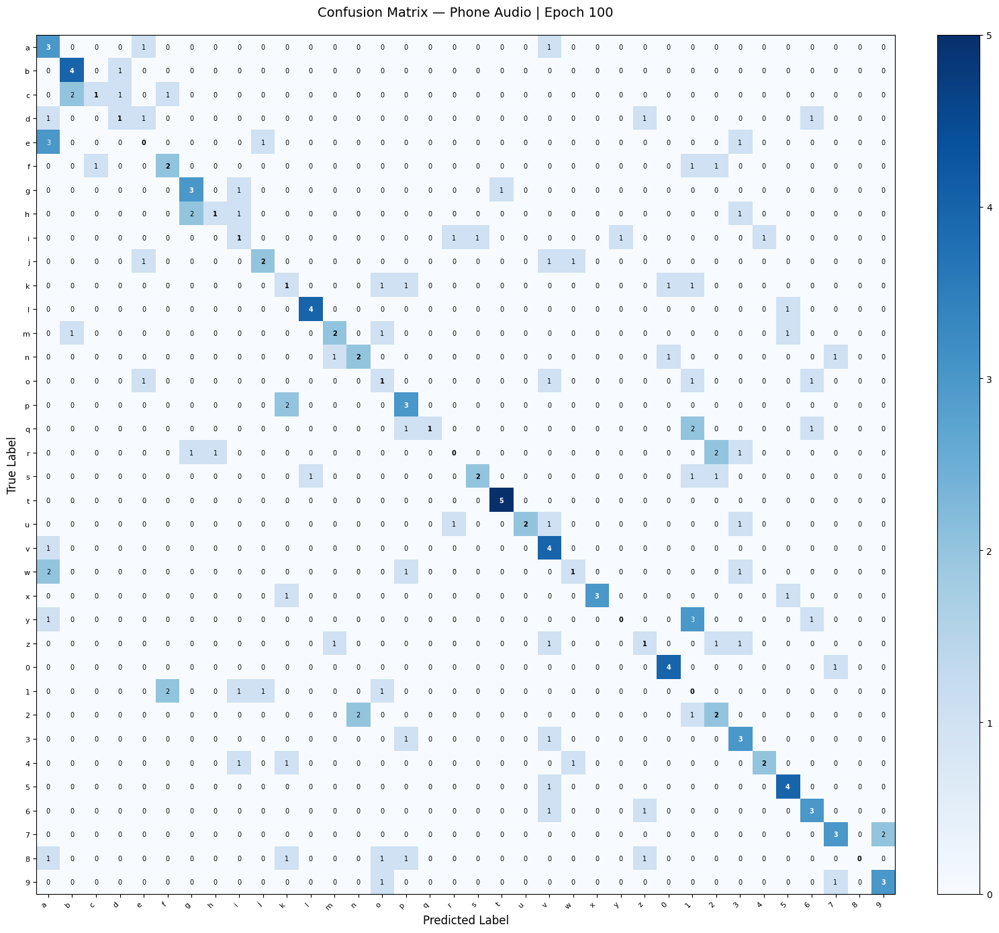

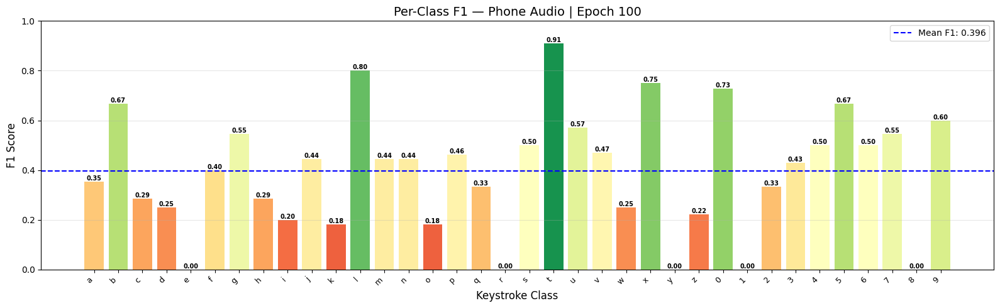

  Time      : 5.91s
  Train     → Loss: 0.8404 | Acc: 0.7625
  Val       → Loss: 1.9875   | Acc: 0.4111
  Weighted  → P: 0.4370 | R: 0.4111 | F1: 0.3959

Epoch 101/1100
------------------------------------------------------------



  Validation Results — Phone Audio | Epoch 101
  Accuracy  : 0.5111
  Precision : 0.5778  (weighted)
  Recall    : 0.5111  (weighted)
  F1 Score  : 0.5111  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.4000     0.3636          5
  b              0.6667     0.8000     0.7273          5
  c              0.6000     0.6000     0.6000          5
  d              1.0000     0.6000     0.7500          5
  e              0.3333     0.4000     0.3636          5
  f              0.5000     0.6000     0.5455          5
  g              0.7500     0.6000     0.6667          5
  h              1.0000     0.6000     0.7500          5
  i              0.2500     0.2000     0.2222          5
  j              0.8000     0.8000     0.8000          5
  k              0.2222     0.4000     0.2857          5
  l              0.8333     1.0000     0.9091          5
  m              0.


  Validation Results — Phone Audio | Epoch 102
  Accuracy  : 0.4667
  Precision : 0.5149  (weighted)
  Recall    : 0.4667  (weighted)
  F1 Score  : 0.4677  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.7500     0.6000     0.6667          5
  b              0.6667     0.8000     0.7273          5
  c              0.5000     0.4000     0.4444          5
  d              0.2500     0.2000     0.2222          5
  e              0.2857     0.4000     0.3333          5
  f              0.3333     0.4000     0.3636          5
  g              0.7500     0.6000     0.6667          5
  h              0.7500     0.6000     0.6667          5
  i              0.2000     0.2000     0.2000          5
  j              1.0000     0.4000     0.5714          5
  k              0.3636     0.8000     0.5000          5
  l              0.8000     0.8000     0.8000          5
  m              0.


  Validation Results — Phone Audio | Epoch 103
  Accuracy  : 0.4056
  Precision : 0.4450  (weighted)
  Recall    : 0.4056  (weighted)
  F1 Score  : 0.3968  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.4000     0.4444          5
  b              0.6667     0.4000     0.5000          5
  c              0.4286     0.6000     0.5000          5
  d              0.3333     0.2000     0.2500          5
  e              0.2000     0.2000     0.2000          5
  f              0.4286     0.6000     0.5000          5
  g              0.3333     0.2000     0.2500          5
  h              0.4286     0.6000     0.5000          5
  i              0.2500     0.2000     0.2222          5
  j              0.7500     0.6000     0.6667          5
  k              0.2000     0.2000     0.2000          5
  l              0.5714     0.8000     0.6667          5
  m              0.


  Validation Results — Phone Audio | Epoch 104
  Accuracy  : 0.5000
  Precision : 0.5101  (weighted)
  Recall    : 0.5000  (weighted)
  F1 Score  : 0.4827  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.4000     0.3636          5
  b              0.6667     0.8000     0.7273          5
  c              0.2500     0.2000     0.2222          5
  d              0.6000     0.6000     0.6000          5
  e              0.2000     0.2000     0.2000          5
  f              0.5000     0.4000     0.4444          5
  g              0.5000     0.4000     0.4444          5
  h              0.5000     0.6000     0.5455          5
  i              0.3333     0.2000     0.2500          5
  j              0.8333     1.0000     0.9091          5
  k              0.5714     0.8000     0.6667          5
  l              0.8333     1.0000     0.9091          5
  m              0.

...


  Validation Results — Phone Audio | Epoch 196
  Accuracy  : 0.4667
  Precision : 0.4956  (weighted)
  Recall    : 0.4667  (weighted)
  F1 Score  : 0.4543  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.6667     0.4000     0.5000          5
  b              0.5000     0.6000     0.5455          5
  c              0.5000     0.2000     0.2857          5
  d              0.2500     0.2000     0.2222          5
  e              0.4000     0.4000     0.4000          5
  f              0.3750     0.6000     0.4615          5
  g              0.6667     0.4000     0.5000          5
  h              0.6000     0.6000     0.6000          5
  i              0.2000     0.2000     0.2000          5
  j              1.0000     0.6000     0.7500          5
  k              0.2000     0.2000     0.2000          5
  l              0.8000     0.8000     0.8000          5
  m              1.


  Validation Results — Phone Audio | Epoch 197
  Accuracy  : 0.4667
  Precision : 0.5192  (weighted)
  Recall    : 0.4667  (weighted)
  F1 Score  : 0.4609  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3750     0.6000     0.4615          5
  b              0.7500     0.6000     0.6667          5
  c              0.6667     0.8000     0.7273          5
  d              0.2500     0.2000     0.2222          5
  e              0.3333     0.4000     0.3636          5
  f              0.3333     0.6000     0.4286          5
  g              0.0000     0.0000     0.0000          5
  h              0.5000     0.6000     0.5455          5
  i              1.0000     0.2000     0.3333          5
  j              1.0000     0.6000     0.7500          5
  k              0.1250     0.2000     0.1538          5
  l              1.0000     0.6000     0.7500          5
  m              0.


  Validation Results — Phone Audio | Epoch 198
  Accuracy  : 0.4833
  Precision : 0.5163  (weighted)
  Recall    : 0.4833  (weighted)
  F1 Score  : 0.4745  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3750     0.6000     0.4615          5
  b              0.4286     0.6000     0.5000          5
  c              1.0000     0.2000     0.3333          5
  d              0.4444     0.8000     0.5714          5
  e              0.3333     0.2000     0.2500          5
  f              0.2857     0.4000     0.3333          5
  g              0.4000     0.4000     0.4000          5
  h              0.7500     0.6000     0.6667          5
  i              0.3333     0.2000     0.2500          5
  j              1.0000     0.6000     0.7500          5
  k              0.2222     0.4000     0.2857          5
  l              0.8333     1.0000     0.9091          5
  m              0.


  Validation Results — Phone Audio | Epoch 199
  Accuracy  : 0.5333
  Precision : 0.5792  (weighted)
  Recall    : 0.5333  (weighted)
  F1 Score  : 0.5278  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.6000     0.5455          5
  b              0.4286     0.6000     0.5000          5
  c              0.4286     0.6000     0.5000          5
  d              0.7500     0.6000     0.6667          5
  e              0.6000     0.6000     0.6000          5
  f              0.3333     0.4000     0.3636          5
  g              0.6667     0.4000     0.5000          5
  h              0.7500     0.6000     0.6667          5
  i              0.3333     0.2000     0.2500          5
  j              0.8000     0.8000     0.8000          5
  k              0.2857     0.4000     0.3333          5
  l              0.8333     1.0000     0.9091          5
  m              1.


  Validation Results — Phone Audio | Epoch 200
  Accuracy  : 0.4667
  Precision : 0.5080  (weighted)
  Recall    : 0.4667  (weighted)
  F1 Score  : 0.4578  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.4000     0.4000     0.4000          5
  c              0.4286     0.6000     0.5000          5
  d              0.5000     0.2000     0.2857          5
  e              0.5000     0.4000     0.4444          5
  f              0.4286     0.6000     0.5000          5
  g              0.2500     0.2000     0.2222          5
  h              0.5000     0.6000     0.5455          5
  i              0.5000     0.2000     0.2857          5
  j              1.0000     0.8000     0.8889          5
  k              0.1429     0.2000     0.1667          5
  l              0.8000     0.8000     0.8000          5
  m              1.

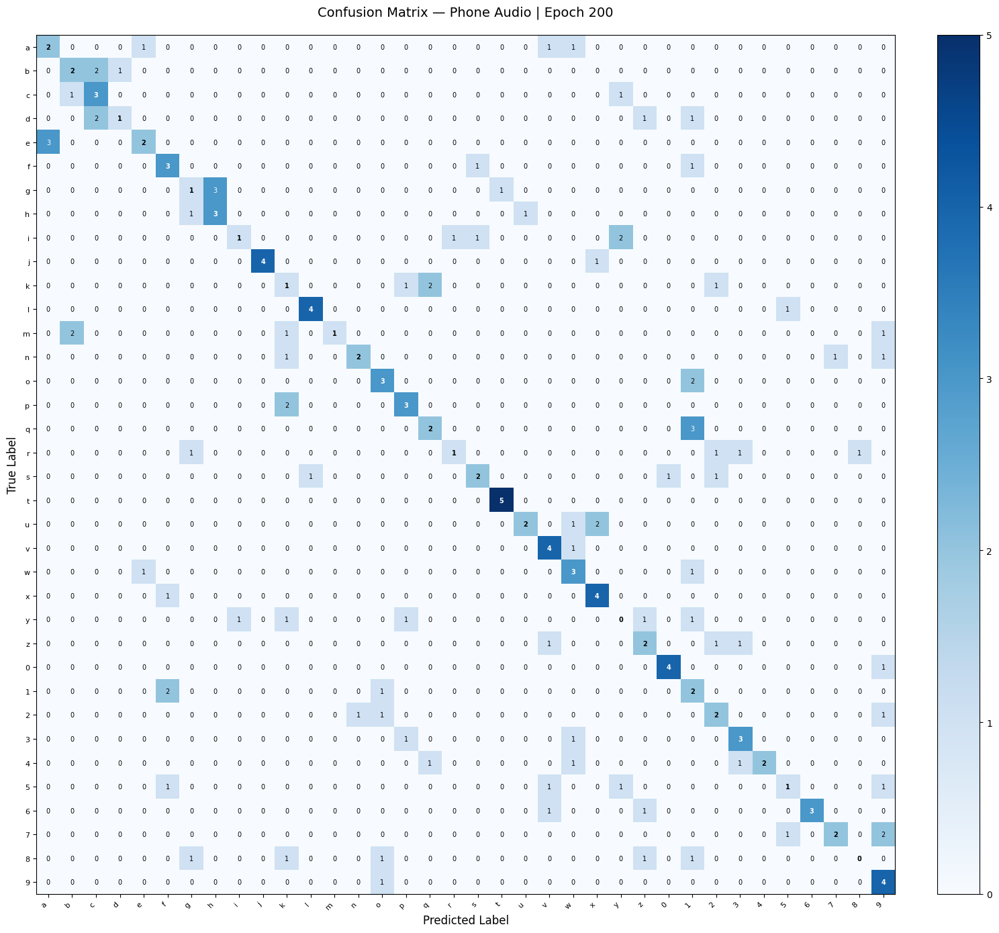

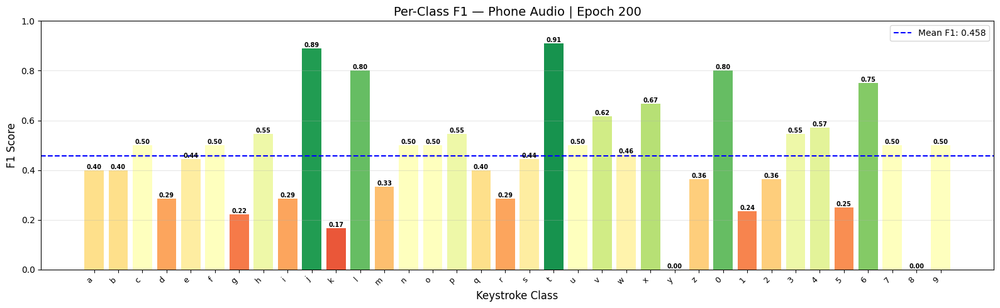

  Time      : 6.11s
  Train     → Loss: 0.1288 | Acc: 0.9708
  Val       → Loss: 2.4674   | Acc: 0.4667
  Weighted  → P: 0.5080 | R: 0.4667 | F1: 0.4578

Epoch 201/1100
------------------------------------------------------------



  Validation Results — Phone Audio | Epoch 201
  Accuracy  : 0.4833
  Precision : 0.4780  (weighted)
  Recall    : 0.4833  (weighted)
  F1 Score  : 0.4578  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.6000     0.5455          5
  b              0.4000     0.4000     0.4000          5
  c              0.2500     0.2000     0.2222          5
  d              0.0000     0.0000     0.0000          5
  e              1.0000     0.4000     0.5714          5
  f              0.3333     0.6000     0.4286          5
  g              0.4000     0.4000     0.4000          5
  h              0.6000     0.6000     0.6000          5
  i              0.3333     0.2000     0.2500          5
  j              0.6667     0.8000     0.7273          5
  k              0.2857     0.4000     0.3333          5
  l              0.8333     1.0000     0.9091          5
  m              1.


  Validation Results — Phone Audio | Epoch 202
  Accuracy  : 0.4056
  Precision : 0.4358  (weighted)
  Recall    : 0.4056  (weighted)
  F1 Score  : 0.3966  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              0.5000     0.6000     0.5455          5
  c              0.4000     0.4000     0.4000          5
  d              0.5000     0.2000     0.2857          5
  e              0.2500     0.4000     0.3077          5
  f              0.2500     0.4000     0.3077          5
  g              0.5000     0.2000     0.2857          5
  h              0.5000     0.4000     0.4444          5
  i              0.3333     0.2000     0.2500          5
  j              0.5714     0.8000     0.6667          5
  k              0.1429     0.2000     0.1667          5
  l              0.8333     1.0000     0.9091          5
  m              0.


  Validation Results — Phone Audio | Epoch 203
  Accuracy  : 0.4222
  Precision : 0.4556  (weighted)
  Recall    : 0.4222  (weighted)
  F1 Score  : 0.4151  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.4286     0.6000     0.5000          5
  c              0.2000     0.2000     0.2000          5
  d              0.3333     0.2000     0.2500          5
  e              0.4000     0.4000     0.4000          5
  f              0.3333     0.4000     0.3636          5
  g              0.5000     0.4000     0.4444          5
  h              0.7500     0.6000     0.6667          5
  i              1.0000     0.2000     0.3333          5
  j              0.8000     0.8000     0.8000          5
  k              0.2000     0.2000     0.2000          5
  l              0.8000     0.8000     0.8000          5
  m              0.


  Validation Results — Phone Audio | Epoch 204
  Accuracy  : 0.4667
  Precision : 0.4931  (weighted)
  Recall    : 0.4667  (weighted)
  F1 Score  : 0.4572  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.4000     0.2667          5
  b              0.5714     0.8000     0.6667          5
  c              0.7500     0.6000     0.6667          5
  d              0.3333     0.2000     0.2500          5
  e              0.4000     0.4000     0.4000          5
  f              0.4444     0.8000     0.5714          5
  g              0.5000     0.2000     0.2857          5
  h              0.5000     0.6000     0.5455          5
  i              0.5000     0.2000     0.2857          5
  j              0.8000     0.8000     0.8000          5
  k              0.1429     0.2000     0.1667          5
  l              0.8000     0.8000     0.8000          5
  m              0.

...


  Validation Results — Phone Audio | Epoch 296
  Accuracy  : 0.4667
  Precision : 0.4868  (weighted)
  Recall    : 0.4667  (weighted)
  F1 Score  : 0.4557  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.6000     0.5455          5
  b              0.5000     0.6000     0.5455          5
  c              0.5000     0.6000     0.5455          5
  d              0.5000     0.4000     0.4444          5
  e              0.6000     0.6000     0.6000          5
  f              0.5000     0.4000     0.4444          5
  g              0.4000     0.4000     0.4000          5
  h              0.5000     0.4000     0.4444          5
  i              1.0000     0.2000     0.3333          5
  j              1.0000     0.8000     0.8889          5
  k              0.2222     0.4000     0.2857          5
  l              0.6000     0.6000     0.6000          5
  m              0.


  Validation Results — Phone Audio | Epoch 297
  Accuracy  : 0.4611
  Precision : 0.4656  (weighted)
  Recall    : 0.4611  (weighted)
  F1 Score  : 0.4518  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.4000     0.3636          5
  b              0.4286     0.6000     0.5000          5
  c              0.4000     0.4000     0.4000          5
  d              0.3333     0.2000     0.2500          5
  e              0.7500     0.6000     0.6667          5
  f              0.2857     0.4000     0.3333          5
  g              0.0000     0.0000     0.0000          5
  h              0.5000     0.4000     0.4444          5
  i              0.3333     0.2000     0.2500          5
  j              0.8000     0.8000     0.8000          5
  k              0.2000     0.2000     0.2000          5
  l              1.0000     0.8000     0.8889          5
  m              0.


  Validation Results — Phone Audio | Epoch 298
  Accuracy  : 0.4556
  Precision : 0.4880  (weighted)
  Recall    : 0.4556  (weighted)
  F1 Score  : 0.4539  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3750     0.6000     0.4615          5
  b              0.3333     0.4000     0.3636          5
  c              0.4286     0.6000     0.5000          5
  d              0.0000     0.0000     0.0000          5
  e              0.7500     0.6000     0.6667          5
  f              0.2857     0.4000     0.3333          5
  g              0.6667     0.4000     0.5000          5
  h              0.6667     0.4000     0.5000          5
  i              0.3333     0.4000     0.3636          5
  j              1.0000     0.6000     0.7500          5
  k              0.3333     0.4000     0.3636          5
  l              1.0000     1.0000     1.0000          5
  m              1.


  Validation Results — Phone Audio | Epoch 299
  Accuracy  : 0.4611
  Precision : 0.4929  (weighted)
  Recall    : 0.4611  (weighted)
  F1 Score  : 0.4534  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4286     0.6000     0.5000          5
  b              0.3333     0.4000     0.3636          5
  c              0.3333     0.4000     0.3636          5
  d              0.0000     0.0000     0.0000          5
  e              1.0000     0.4000     0.5714          5
  f              0.1667     0.2000     0.1818          5
  g              0.5000     0.2000     0.2857          5
  h              0.5000     0.4000     0.4444          5
  i              0.6667     0.4000     0.5000          5
  j              1.0000     1.0000     1.0000          5
  k              0.3750     0.6000     0.4615          5
  l              0.8333     1.0000     0.9091          5
  m              1.


  Validation Results — Phone Audio | Epoch 300
  Accuracy  : 0.4500
  Precision : 0.4596  (weighted)
  Recall    : 0.4500  (weighted)
  F1 Score  : 0.4368  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3750     0.6000     0.4615          5
  b              0.2500     0.2000     0.2222          5
  c              0.5000     0.6000     0.5455          5
  d              0.3333     0.2000     0.2500          5
  e              0.5000     0.6000     0.5455          5
  f              0.2857     0.4000     0.3333          5
  g              0.2000     0.2000     0.2000          5
  h              0.4000     0.4000     0.4000          5
  i              0.3333     0.2000     0.2500          5
  j              1.0000     0.8000     0.8889          5
  k              0.2500     0.4000     0.3077          5
  l              0.8333     1.0000     0.9091          5
  m              0.

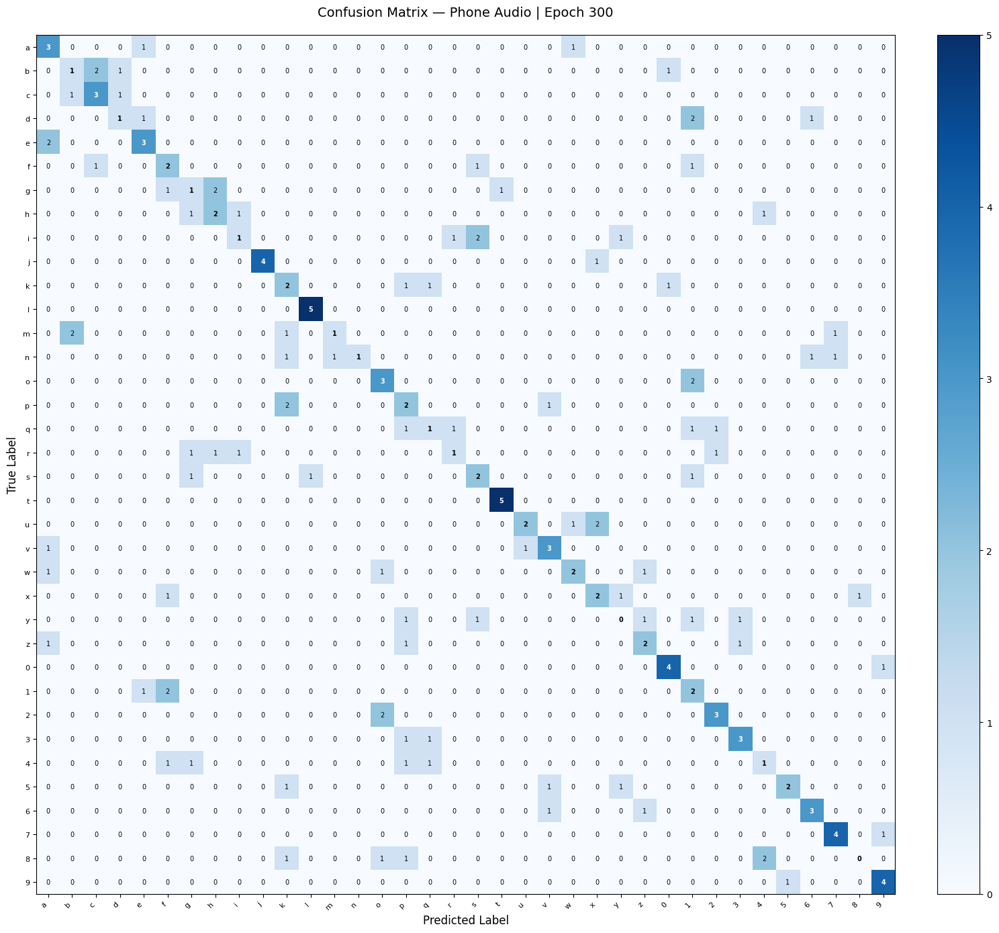

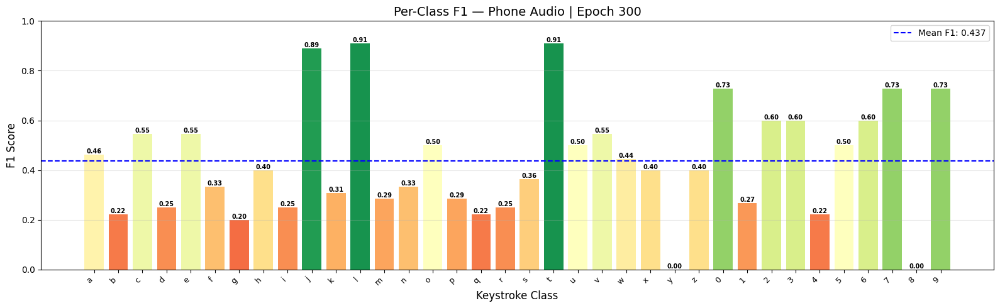

  Time      : 5.88s
  Train     → Loss: 0.0339 | Acc: 0.9958
  Val       → Loss: 3.2472   | Acc: 0.4500
  Weighted  → P: 0.4596 | R: 0.4500 | F1: 0.4368

Epoch 301/1100
------------------------------------------------------------



  Validation Results — Phone Audio | Epoch 301
  Accuracy  : 0.4611
  Precision : 0.4592  (weighted)
  Recall    : 0.4611  (weighted)
  F1 Score  : 0.4394  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.6000     0.5455          5
  b              0.4000     0.4000     0.4000          5
  c              0.2500     0.4000     0.3077          5
  d              0.0000     0.0000     0.0000          5
  e              0.5000     0.4000     0.4444          5
  f              0.3750     0.6000     0.4615          5
  g              0.5000     0.2000     0.2857          5
  h              0.6000     0.6000     0.6000          5
  i              0.5000     0.2000     0.2857          5
  j              0.6250     1.0000     0.7692          5
  k              0.3333     0.2000     0.2500          5
  l              1.0000     0.6000     0.7500          5
  m              0.


  Validation Results — Phone Audio | Epoch 302
  Accuracy  : 0.4389
  Precision : 0.4841  (weighted)
  Recall    : 0.4389  (weighted)
  F1 Score  : 0.4319  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.2000     0.2222          5
  b              0.3333     0.4000     0.3636          5
  c              0.5000     0.4000     0.4444          5
  d              0.3333     0.2000     0.2500          5
  e              0.5000     0.2000     0.2857          5
  f              0.3750     0.6000     0.4615          5
  g              1.0000     0.4000     0.5714          5
  h              0.6667     0.4000     0.5000          5
  i              0.2500     0.2000     0.2222          5
  j              0.7500     0.6000     0.6667          5
  k              0.2857     0.4000     0.3333          5
  l              0.8000     0.8000     0.8000          5
  m              1.


  Validation Results — Phone Audio | Epoch 303
  Accuracy  : 0.4667
  Precision : 0.4994  (weighted)
  Recall    : 0.4667  (weighted)
  F1 Score  : 0.4427  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.8000     0.5333          5
  b              0.4000     0.4000     0.4000          5
  c              0.3750     0.6000     0.4615          5
  d              0.0000     0.0000     0.0000          5
  e              1.0000     0.6000     0.7500          5
  f              0.5000     0.6000     0.5455          5
  g              0.5000     0.2000     0.2857          5
  h              0.4000     0.4000     0.4000          5
  i              0.5000     0.2000     0.2857          5
  j              1.0000     0.8000     0.8889          5
  k              0.2857     0.4000     0.3333          5
  l              0.8000     0.8000     0.8000          5
  m              1.


  Validation Results — Phone Audio | Epoch 304
  Accuracy  : 0.4556
  Precision : 0.4885  (weighted)
  Recall    : 0.4556  (weighted)
  F1 Score  : 0.4404  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3750     0.6000     0.4615          5
  b              0.5000     0.8000     0.6154          5
  c              0.3333     0.4000     0.3636          5
  d              0.0000     0.0000     0.0000          5
  e              1.0000     0.6000     0.7500          5
  f              0.3333     0.4000     0.3636          5
  g              1.0000     0.2000     0.3333          5
  h              0.6667     0.4000     0.5000          5
  i              1.0000     0.2000     0.3333          5
  j              0.6667     0.4000     0.5000          5
  k              0.2857     0.4000     0.3333          5
  l              0.7500     0.6000     0.6667          5
  m              0.

...


  Validation Results — Phone Audio | Epoch 396
  Accuracy  : 0.4556
  Precision : 0.4727  (weighted)
  Recall    : 0.4556  (weighted)
  F1 Score  : 0.4421  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4286     0.6000     0.5000          5
  b              0.5000     0.4000     0.4444          5
  c              0.4286     0.6000     0.5000          5
  d              0.5000     0.2000     0.2857          5
  e              0.5714     0.8000     0.6667          5
  f              0.2222     0.4000     0.2857          5
  g              1.0000     0.4000     0.5714          5
  h              1.0000     0.6000     0.7500          5
  i              0.3333     0.2000     0.2500          5
  j              0.8000     0.8000     0.8000          5
  k              0.1429     0.2000     0.1667          5
  l              1.0000     0.6000     0.7500          5
  m              0.


  Validation Results — Phone Audio | Epoch 397
  Accuracy  : 0.4500
  Precision : 0.4709  (weighted)
  Recall    : 0.4500  (weighted)
  F1 Score  : 0.4367  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3750     0.6000     0.4615          5
  b              0.6000     0.6000     0.6000          5
  c              0.5000     0.6000     0.5455          5
  d              0.0000     0.0000     0.0000          5
  e              1.0000     0.6000     0.7500          5
  f              0.5000     0.6000     0.5455          5
  g              0.5000     0.2000     0.2857          5
  h              0.4286     0.6000     0.5000          5
  i              1.0000     0.2000     0.3333          5
  j              0.5714     0.8000     0.6667          5
  k              0.2000     0.2000     0.2000          5
  l              0.6667     0.4000     0.5000          5
  m              0.


  Validation Results — Phone Audio | Epoch 398
  Accuracy  : 0.4000
  Precision : 0.4385  (weighted)
  Recall    : 0.4000  (weighted)
  F1 Score  : 0.3921  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2857     0.4000     0.3333          5
  b              0.2500     0.2000     0.2222          5
  c              0.5000     0.6000     0.5455          5
  d              0.0000     0.0000     0.0000          5
  e              0.3636     0.8000     0.5000          5
  f              0.3333     0.2000     0.2500          5
  g              0.6667     0.4000     0.5000          5
  h              1.0000     0.4000     0.5714          5
  i              0.5000     0.2000     0.2857          5
  j              0.7500     0.6000     0.6667          5
  k              0.2000     0.4000     0.2667          5
  l              0.6667     0.4000     0.5000          5
  m              0.


  Validation Results — Phone Audio | Epoch 399
  Accuracy  : 0.4500
  Precision : 0.5208  (weighted)
  Recall    : 0.4500  (weighted)
  F1 Score  : 0.4427  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2727     0.6000     0.3750          5
  b              0.5000     0.2000     0.2857          5
  c              0.6000     0.6000     0.6000          5
  d              0.4000     0.4000     0.4000          5
  e              0.6667     0.8000     0.7273          5
  f              0.3750     0.6000     0.4615          5
  g              0.6667     0.4000     0.5000          5
  h              1.0000     0.2000     0.3333          5
  i              0.3333     0.2000     0.2500          5
  j              1.0000     0.4000     0.5714          5
  k              0.2222     0.4000     0.2857          5
  l              0.6667     0.8000     0.7273          5
  m              1.


  Validation Results — Phone Audio | Epoch 400
  Accuracy  : 0.4500
  Precision : 0.4996  (weighted)
  Recall    : 0.4500  (weighted)
  F1 Score  : 0.4465  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.1818     0.4000     0.2500          5
  b              0.5000     0.8000     0.6154          5
  c              0.6667     0.4000     0.5000          5
  d              0.5000     0.4000     0.4444          5
  e              0.4000     0.4000     0.4000          5
  f              0.4000     0.4000     0.4000          5
  g              1.0000     0.4000     0.5714          5
  h              0.5000     0.4000     0.4444          5
  i              0.3333     0.2000     0.2500          5
  j              0.6667     0.8000     0.7273          5
  k              0.1250     0.2000     0.1538          5
  l              0.7500     0.6000     0.6667          5
  m              1.

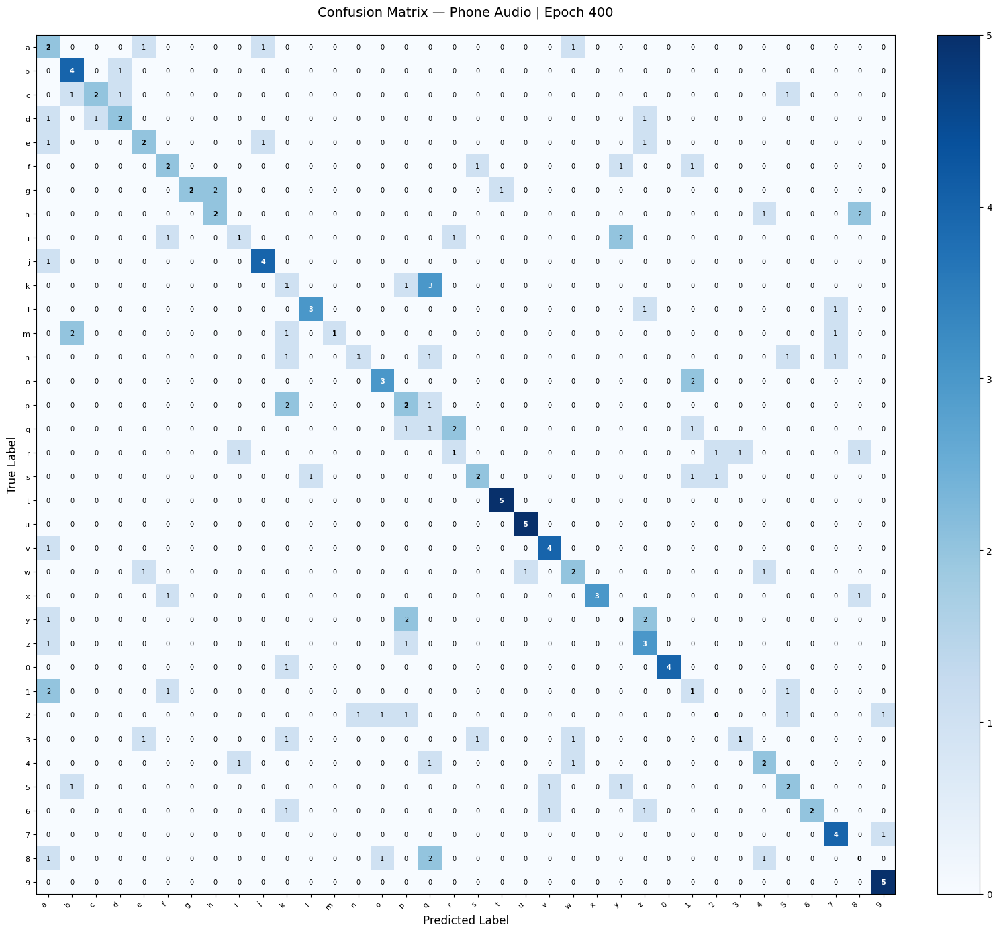

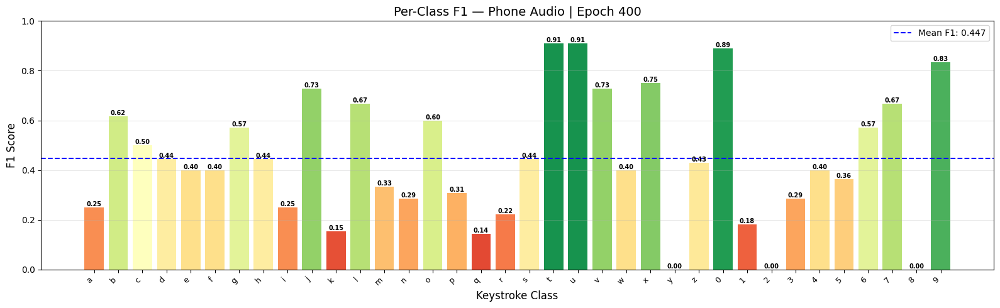

  Time      : 5.60s
  Train     → Loss: 0.0272 | Acc: 0.9931
  Val       → Loss: 3.6884   | Acc: 0.4500
  Weighted  → P: 0.4996 | R: 0.4500 | F1: 0.4465

Epoch 401/1100
------------------------------------------------------------



  Validation Results — Phone Audio | Epoch 401
  Accuracy  : 0.4444
  Precision : 0.5062  (weighted)
  Recall    : 0.4444  (weighted)
  F1 Score  : 0.4351  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.4000     0.3636          5
  b              0.4000     0.8000     0.5333          5
  c              0.6000     0.6000     0.6000          5
  d              0.3333     0.2000     0.2500          5
  e              0.7500     0.6000     0.6667          5
  f              0.2500     0.4000     0.3077          5
  g              0.5000     0.4000     0.4444          5
  h              1.0000     0.4000     0.5714          5
  i              0.5000     0.2000     0.2857          5
  j              0.7500     0.6000     0.6667          5
  k              0.3000     0.6000     0.4000          5
  l              0.6667     0.8000     0.7273          5
  m              1.


  Validation Results — Phone Audio | Epoch 402
  Accuracy  : 0.4333
  Precision : 0.4540  (weighted)
  Recall    : 0.4333  (weighted)
  F1 Score  : 0.4194  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3750     0.6000     0.4615          5
  b              0.2500     0.2000     0.2222          5
  c              0.3333     0.6000     0.4286          5
  d              0.0000     0.0000     0.0000          5
  e              1.0000     0.4000     0.5714          5
  f              0.5000     0.4000     0.4444          5
  g              0.6667     0.4000     0.5000          5
  h              0.3333     0.4000     0.3636          5
  i              0.0000     0.0000     0.0000          5
  j              0.6000     0.6000     0.6000          5
  k              0.2857     0.4000     0.3333          5
  l              0.6667     0.8000     0.7273          5
  m              1.


  Validation Results — Phone Audio | Epoch 403
  Accuracy  : 0.4722
  Precision : 0.5101  (weighted)
  Recall    : 0.4722  (weighted)
  F1 Score  : 0.4533  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.4000     0.3077          5
  b              0.5000     0.4000     0.4444          5
  c              0.6000     0.6000     0.6000          5
  d              0.3333     0.2000     0.2500          5
  e              0.7500     0.6000     0.6667          5
  f              0.2857     0.4000     0.3333          5
  g              0.5000     0.4000     0.4444          5
  h              0.6000     0.6000     0.6000          5
  i              1.0000     0.2000     0.3333          5
  j              1.0000     0.8000     0.8889          5
  k              0.3333     0.4000     0.3636          5
  l              0.8333     1.0000     0.9091          5
  m              1.


  Validation Results — Phone Audio | Epoch 404
  Accuracy  : 0.4278
  Precision : 0.4520  (weighted)
  Recall    : 0.4278  (weighted)
  F1 Score  : 0.4181  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.1250     0.2000     0.1538          5
  b              0.3333     0.4000     0.3636          5
  c              0.4000     0.4000     0.4000          5
  d              0.0000     0.0000     0.0000          5
  e              0.5000     0.4000     0.4444          5
  f              0.2000     0.4000     0.2667          5
  g              0.5000     0.2000     0.2857          5
  h              0.3333     0.2000     0.2500          5
  i              0.2000     0.2000     0.2000          5
  j              0.5000     0.8000     0.6154          5
  k              0.2000     0.2000     0.2000          5
  l              0.8333     1.0000     0.9091          5
  m              1.

...


  Validation Results — Phone Audio | Epoch 496
  Accuracy  : 0.4333
  Precision : 0.4907  (weighted)
  Recall    : 0.4333  (weighted)
  F1 Score  : 0.4290  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.8000     0.4706          5
  b              0.4286     0.6000     0.5000          5
  c              0.6667     0.4000     0.5000          5
  d              0.5000     0.4000     0.4444          5
  e              0.5000     0.4000     0.4444          5
  f              0.5000     0.4000     0.4444          5
  g              0.5000     0.4000     0.4444          5
  h              0.6667     0.4000     0.5000          5
  i              1.0000     0.2000     0.3333          5
  j              0.5000     0.4000     0.4444          5
  k              0.2500     0.4000     0.3077          5
  l              0.8000     0.8000     0.8000          5
  m              1.


  Validation Results — Phone Audio | Epoch 497
  Accuracy  : 0.4778
  Precision : 0.4750  (weighted)
  Recall    : 0.4778  (weighted)
  F1 Score  : 0.4552  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.5714     0.8000     0.6667          5
  c              0.7500     0.6000     0.6667          5
  d              0.5000     0.2000     0.2857          5
  e              0.3333     0.4000     0.3636          5
  f              0.4000     0.4000     0.4000          5
  g              0.6667     0.4000     0.5000          5
  h              0.3333     0.4000     0.3636          5
  i              0.5000     0.2000     0.2857          5
  j              0.4286     0.6000     0.5000          5
  k              0.2857     0.4000     0.3333          5
  l              0.6667     0.8000     0.7273          5
  m              0.


  Validation Results — Phone Audio | Epoch 498
  Accuracy  : 0.4500
  Precision : 0.4715  (weighted)
  Recall    : 0.4500  (weighted)
  F1 Score  : 0.4377  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.6000     0.5455          5
  b              0.2000     0.2000     0.2000          5
  c              0.4286     0.6000     0.5000          5
  d              0.0000     0.0000     0.0000          5
  e              0.5000     0.4000     0.4444          5
  f              0.2500     0.2000     0.2222          5
  g              0.6667     0.4000     0.5000          5
  h              0.5000     0.6000     0.5455          5
  i              0.5000     0.2000     0.2857          5
  j              0.6667     0.8000     0.7273          5
  k              0.3333     0.4000     0.3636          5
  l              1.0000     0.8000     0.8889          5
  m              1.


  Validation Results — Phone Audio | Epoch 499
  Accuracy  : 0.4778
  Precision : 0.4966  (weighted)
  Recall    : 0.4778  (weighted)
  F1 Score  : 0.4658  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4444     0.8000     0.5714          5
  b              0.3333     0.4000     0.3636          5
  c              0.4286     0.6000     0.5000          5
  d              0.0000     0.0000     0.0000          5
  e              1.0000     0.6000     0.7500          5
  f              0.3333     0.4000     0.3636          5
  g              0.5000     0.4000     0.4444          5
  h              0.4000     0.4000     0.4000          5
  i              0.5000     0.4000     0.4444          5
  j              1.0000     1.0000     1.0000          5
  k              0.3333     0.4000     0.3636          5
  l              1.0000     0.8000     0.8889          5
  m              1.


  Validation Results — Phone Audio | Epoch 500
  Accuracy  : 0.4444
  Precision : 0.4557  (weighted)
  Recall    : 0.4444  (weighted)
  F1 Score  : 0.4260  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.6000     0.5455          5
  b              0.2000     0.2000     0.2000          5
  c              0.4286     0.6000     0.5000          5
  d              0.0000     0.0000     0.0000          5
  e              0.6000     0.6000     0.6000          5
  f              0.3333     0.6000     0.4286          5
  g              0.5000     0.4000     0.4444          5
  h              0.5000     0.2000     0.2857          5
  i              0.5000     0.2000     0.2857          5
  j              0.8000     0.8000     0.8000          5
  k              0.1111     0.2000     0.1429          5
  l              0.8000     0.8000     0.8000          5
  m              1.

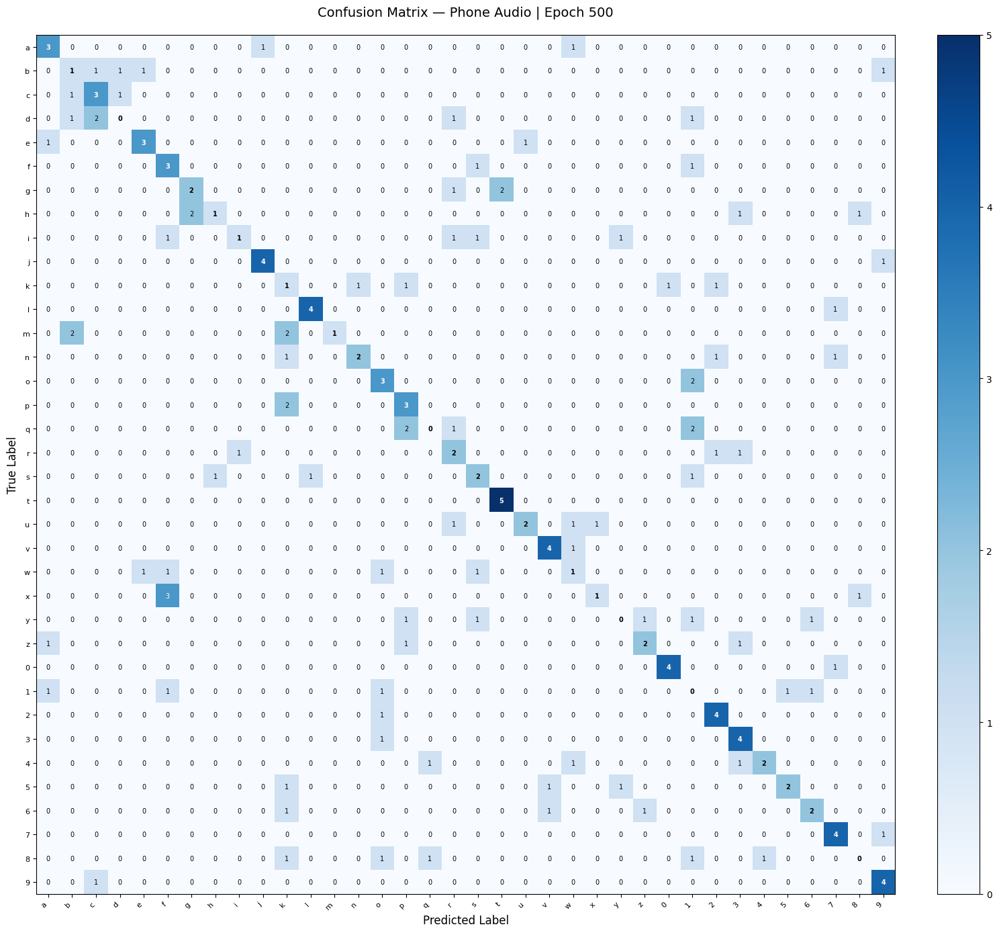

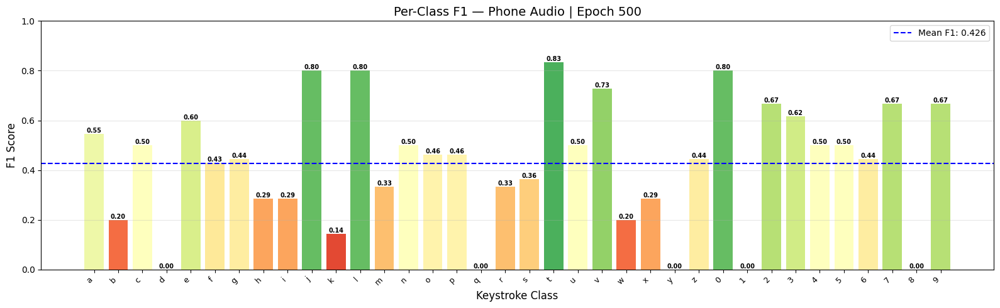

  Time      : 6.22s
  Train     → Loss: 0.0152 | Acc: 0.9958
  Val       → Loss: 4.2324   | Acc: 0.4444
  Weighted  → P: 0.4557 | R: 0.4444 | F1: 0.4260

Epoch 501/1100
------------------------------------------------------------



  Validation Results — Phone Audio | Epoch 501
  Accuracy  : 0.4444
  Precision : 0.4882  (weighted)
  Recall    : 0.4444  (weighted)
  F1 Score  : 0.4379  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.6000     0.6000     0.6000          5
  c              0.5000     0.6000     0.5455          5
  d              0.2500     0.2000     0.2222          5
  e              1.0000     0.4000     0.5714          5
  f              0.5000     0.6000     0.5455          5
  g              0.3333     0.2000     0.2500          5
  h              0.6667     0.4000     0.5000          5
  i              0.5000     0.2000     0.2857          5
  j              0.6000     0.6000     0.6000          5
  k              0.2222     0.4000     0.2857          5
  l              0.8000     0.8000     0.8000          5
  m              1.


  Validation Results — Phone Audio | Epoch 502
  Accuracy  : 0.4556
  Precision : 0.4914  (weighted)
  Recall    : 0.4556  (weighted)
  F1 Score  : 0.4445  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.5000     0.8000     0.6154          5
  c              0.5000     0.6000     0.5455          5
  d              0.0000     0.0000     0.0000          5
  e              0.5000     0.4000     0.4444          5
  f              0.1429     0.2000     0.1667          5
  g              0.5000     0.4000     0.4444          5
  h              0.4000     0.4000     0.4000          5
  i              0.5000     0.2000     0.2857          5
  j              0.3750     0.6000     0.4615          5
  k              0.2727     0.6000     0.3750          5
  l              1.0000     0.8000     0.8889          5
  m              1.


  Validation Results — Phone Audio | Epoch 503
  Accuracy  : 0.5056
  Precision : 0.5502  (weighted)
  Recall    : 0.5056  (weighted)
  F1 Score  : 0.4956  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.8000     0.6154          5
  b              0.6667     0.8000     0.7273          5
  c              0.7500     0.6000     0.6667          5
  d              0.3333     0.2000     0.2500          5
  e              0.6667     0.4000     0.5000          5
  f              0.2500     0.4000     0.3077          5
  g              0.5000     0.4000     0.4444          5
  h              0.4000     0.4000     0.4000          5
  i              1.0000     0.2000     0.3333          5
  j              0.5000     0.8000     0.6154          5
  k              0.2000     0.2000     0.2000          5
  l              0.8333     1.0000     0.9091          5
  m              0.


  Validation Results — Phone Audio | Epoch 504
  Accuracy  : 0.4444
  Precision : 0.5115  (weighted)
  Recall    : 0.4444  (weighted)
  F1 Score  : 0.4376  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.2857     0.4000     0.3333          5
  c              0.6000     0.6000     0.6000          5
  d              0.3333     0.2000     0.2500          5
  e              0.3333     0.4000     0.3636          5
  f              0.2500     0.4000     0.3077          5
  g              0.6667     0.4000     0.5000          5
  h              0.6667     0.4000     0.5000          5
  i              0.5000     0.2000     0.2857          5
  j              0.3333     0.4000     0.3636          5
  k              0.1538     0.4000     0.2222          5
  l              0.8333     1.0000     0.9091          5
  m              1.

...


  Validation Results — Phone Audio | Epoch 596
  Accuracy  : 0.4667
  Precision : 0.4665  (weighted)
  Recall    : 0.4667  (weighted)
  F1 Score  : 0.4443  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3750     0.6000     0.4615          5
  b              0.5000     0.8000     0.6154          5
  c              0.5000     0.6000     0.5455          5
  d              0.5000     0.2000     0.2857          5
  e              1.0000     0.4000     0.5714          5
  f              0.3333     0.2000     0.2500          5
  g              0.4000     0.4000     0.4000          5
  h              1.0000     0.4000     0.5714          5
  i              0.3333     0.2000     0.2500          5
  j              0.5556     1.0000     0.7143          5
  k              0.2500     0.4000     0.3077          5
  l              1.0000     0.8000     0.8889          5
  m              0.


  Validation Results — Phone Audio | Epoch 597
  Accuracy  : 0.4500
  Precision : 0.4874  (weighted)
  Recall    : 0.4500  (weighted)
  F1 Score  : 0.4422  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3750     0.6000     0.4615          5
  b              0.5000     0.8000     0.6154          5
  c              0.5000     0.6000     0.5455          5
  d              0.6667     0.4000     0.5000          5
  e              0.6000     0.6000     0.6000          5
  f              0.3333     0.2000     0.2500          5
  g              0.6000     0.6000     0.6000          5
  h              0.7500     0.6000     0.6667          5
  i              0.5000     0.2000     0.2857          5
  j              0.6000     0.6000     0.6000          5
  k              0.1250     0.2000     0.1538          5
  l              0.8000     0.8000     0.8000          5
  m              1.


  Validation Results — Phone Audio | Epoch 598
  Accuracy  : 0.4667
  Precision : 0.4945  (weighted)
  Recall    : 0.4667  (weighted)
  F1 Score  : 0.4602  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.1429     0.2000     0.1667          5
  b              0.4286     0.6000     0.5000          5
  c              0.7500     0.6000     0.6667          5
  d              0.5000     0.6000     0.5455          5
  e              0.5000     0.4000     0.4444          5
  f              0.5000     0.4000     0.4444          5
  g              1.0000     0.4000     0.5714          5
  h              0.6667     0.4000     0.5000          5
  i              0.3333     0.2000     0.2500          5
  j              0.5714     0.8000     0.6667          5
  k              0.3750     0.6000     0.4615          5
  l              0.6000     0.6000     0.6000          5
  m              1.


  Validation Results — Phone Audio | Epoch 599
  Accuracy  : 0.4500
  Precision : 0.4632  (weighted)
  Recall    : 0.4500  (weighted)
  F1 Score  : 0.4228  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.8000     0.5333          5
  b              0.6000     0.6000     0.6000          5
  c              0.5000     0.6000     0.5455          5
  d              0.0000     0.0000     0.0000          5
  e              0.7500     0.6000     0.6667          5
  f              0.3333     0.4000     0.3636          5
  g              0.0000     0.0000     0.0000          5
  h              0.6667     0.4000     0.5000          5
  i              1.0000     0.2000     0.3333          5
  j              1.0000     0.8000     0.8889          5
  k              0.1667     0.2000     0.1818          5
  l              0.7500     0.6000     0.6667          5
  m              0.


  Validation Results — Phone Audio | Epoch 600
  Accuracy  : 0.4389
  Precision : 0.5143  (weighted)
  Recall    : 0.4389  (weighted)
  F1 Score  : 0.4377  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3000     0.6000     0.4000          5
  b              0.6667     0.8000     0.7273          5
  c              0.7500     0.6000     0.6667          5
  d              0.2500     0.2000     0.2222          5
  e              0.7500     0.6000     0.6667          5
  f              0.4000     0.4000     0.4000          5
  g              0.5000     0.2000     0.2857          5
  h              0.7500     0.6000     0.6667          5
  i              1.0000     0.2000     0.3333          5
  j              0.7500     0.6000     0.6667          5
  k              0.2500     0.4000     0.3077          5
  l              1.0000     0.6000     0.7500          5
  m              0.

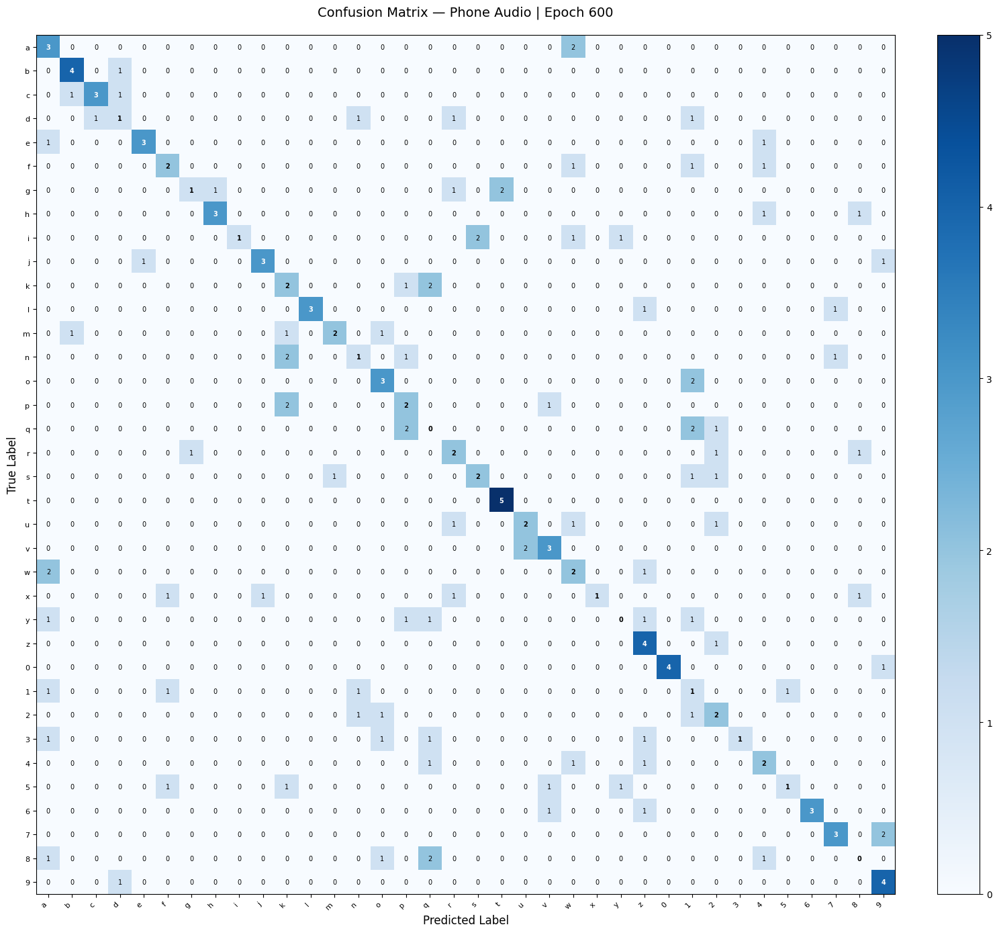

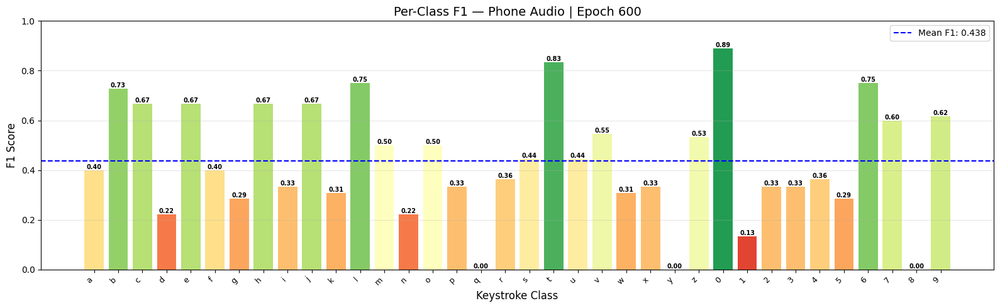

  Time      : 5.87s
  Train     → Loss: 0.0166 | Acc: 0.9944
  Val       → Loss: 4.9252   | Acc: 0.4389
  Weighted  → P: 0.5143 | R: 0.4389 | F1: 0.4377

Epoch 601/1100
------------------------------------------------------------



  Validation Results — Phone Audio | Epoch 601
  Accuracy  : 0.4389
  Precision : 0.4583  (weighted)
  Recall    : 0.4389  (weighted)
  F1 Score  : 0.4212  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              0.3750     0.6000     0.4615          5
  c              0.5000     0.6000     0.5455          5
  d              0.0000     0.0000     0.0000          5
  e              1.0000     0.4000     0.5714          5
  f              0.2000     0.2000     0.2000          5
  g              0.4000     0.4000     0.4000          5
  h              0.6000     0.6000     0.6000          5
  i              0.5000     0.2000     0.2857          5
  j              0.5000     0.6000     0.5455          5
  k              0.2143     0.6000     0.3158          5
  l              0.8333     1.0000     0.9091          5
  m              1.


  Validation Results — Phone Audio | Epoch 602
  Accuracy  : 0.4778
  Precision : 0.5506  (weighted)
  Recall    : 0.4778  (weighted)
  F1 Score  : 0.4669  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2857     0.4000     0.3333          5
  b              0.5000     0.6000     0.5455          5
  c              0.4286     0.6000     0.5000          5
  d              0.0000     0.0000     0.0000          5
  e              1.0000     0.6000     0.7500          5
  f              0.3333     0.4000     0.3636          5
  g              1.0000     0.2000     0.3333          5
  h              0.4286     0.6000     0.5000          5
  i              1.0000     0.2000     0.3333          5
  j              0.6667     0.4000     0.5000          5
  k              0.2500     0.4000     0.3077          5
  l              0.7143     1.0000     0.8333          5
  m              1.


  Validation Results — Phone Audio | Epoch 603
  Accuracy  : 0.4278
  Precision : 0.4886  (weighted)
  Recall    : 0.4278  (weighted)
  F1 Score  : 0.4198  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              0.4000     0.8000     0.5333          5
  c              0.6667     0.4000     0.5000          5
  d              0.5000     0.2000     0.2857          5
  e              0.6667     0.4000     0.5000          5
  f              0.2857     0.4000     0.3333          5
  g              1.0000     0.2000     0.3333          5
  h              0.5000     0.4000     0.4444          5
  i              1.0000     0.2000     0.3333          5
  j              0.5000     0.6000     0.5455          5
  k              0.2500     0.4000     0.3077          5
  l              0.8333     1.0000     0.9091          5
  m              0.


  Validation Results — Phone Audio | Epoch 604
  Accuracy  : 0.4278
  Precision : 0.4668  (weighted)
  Recall    : 0.4278  (weighted)
  F1 Score  : 0.4176  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2857     0.4000     0.3333          5
  b              0.6000     0.6000     0.6000          5
  c              0.4286     0.6000     0.5000          5
  d              0.3333     0.2000     0.2500          5
  e              0.4286     0.6000     0.5000          5
  f              0.3333     0.2000     0.2500          5
  g              0.6667     0.4000     0.5000          5
  h              0.6667     0.4000     0.5000          5
  i              1.0000     0.2000     0.3333          5
  j              0.6667     0.8000     0.7273          5
  k              0.2500     0.4000     0.3077          5
  l              0.8000     0.8000     0.8000          5
  m              1.

...


  Validation Results — Phone Audio | Epoch 696
  Accuracy  : 0.4278
  Precision : 0.4241  (weighted)
  Recall    : 0.4278  (weighted)
  F1 Score  : 0.4030  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.1667     0.2000     0.1818          5
  b              0.5000     0.6000     0.5455          5
  c              0.5000     0.4000     0.4444          5
  d              0.2000     0.2000     0.2000          5
  e              0.6667     0.4000     0.5000          5
  f              0.3333     0.6000     0.4286          5
  g              0.0000     0.0000     0.0000          5
  h              0.5000     0.6000     0.5455          5
  i              0.6667     0.4000     0.5000          5
  j              0.3333     0.4000     0.3636          5
  k              0.3750     0.6000     0.4615          5
  l              0.6667     0.8000     0.7273          5
  m              1.


  Validation Results — Phone Audio | Epoch 697
  Accuracy  : 0.4389
  Precision : 0.4971  (weighted)
  Recall    : 0.4389  (weighted)
  F1 Score  : 0.4251  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.2000     0.2222          5
  b              0.5000     0.6000     0.5455          5
  c              0.5000     0.4000     0.4444          5
  d              0.1667     0.2000     0.1818          5
  e              0.7500     0.6000     0.6667          5
  f              0.4286     0.6000     0.5000          5
  g              1.0000     0.2000     0.3333          5
  h              0.6000     0.6000     0.6000          5
  i              1.0000     0.2000     0.3333          5
  j              0.5000     0.6000     0.5455          5
  k              0.2727     0.6000     0.3750          5
  l              0.6667     0.8000     0.7273          5
  m              1.


  Validation Results — Phone Audio | Epoch 698
  Accuracy  : 0.4556
  Precision : 0.4990  (weighted)
  Recall    : 0.4556  (weighted)
  F1 Score  : 0.4469  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.4167     1.0000     0.5882          5
  c              0.4000     0.4000     0.4000          5
  d              0.5000     0.2000     0.2857          5
  e              0.6667     0.4000     0.5000          5
  f              0.5000     0.4000     0.4444          5
  g              0.2000     0.2000     0.2000          5
  h              0.5000     0.4000     0.4444          5
  i              0.5000     0.2000     0.2857          5
  j              0.6667     0.8000     0.7273          5
  k              0.3333     0.6000     0.4286          5
  l              0.7500     0.6000     0.6667          5
  m              0.


  Validation Results — Phone Audio | Epoch 699
  Accuracy  : 0.4722
  Precision : 0.4823  (weighted)
  Recall    : 0.4722  (weighted)
  F1 Score  : 0.4507  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.6000     0.4286          5
  b              0.5000     0.6000     0.5455          5
  c              0.5000     0.4000     0.4444          5
  d              0.3333     0.2000     0.2500          5
  e              1.0000     0.4000     0.5714          5
  f              0.5000     0.4000     0.4444          5
  g              0.2500     0.4000     0.3077          5
  h              0.5000     0.4000     0.4444          5
  i              0.5000     0.2000     0.2857          5
  j              0.8333     1.0000     0.9091          5
  k              0.2857     0.4000     0.3333          5
  l              0.6667     0.4000     0.5000          5
  m              1.


  Validation Results — Phone Audio | Epoch 700
  Accuracy  : 0.4889
  Precision : 0.4950  (weighted)
  Recall    : 0.4889  (weighted)
  F1 Score  : 0.4636  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4286     0.6000     0.5000          5
  b              0.5714     0.8000     0.6667          5
  c              1.0000     0.4000     0.5714          5
  d              0.3333     0.2000     0.2500          5
  e              1.0000     0.4000     0.5714          5
  f              0.5000     0.4000     0.4444          5
  g              0.3333     0.2000     0.2500          5
  h              0.5000     0.6000     0.5455          5
  i              0.5000     0.2000     0.2857          5
  j              0.8333     1.0000     0.9091          5
  k              0.2857     0.4000     0.3333          5
  l              0.6667     0.4000     0.5000          5
  m              1.

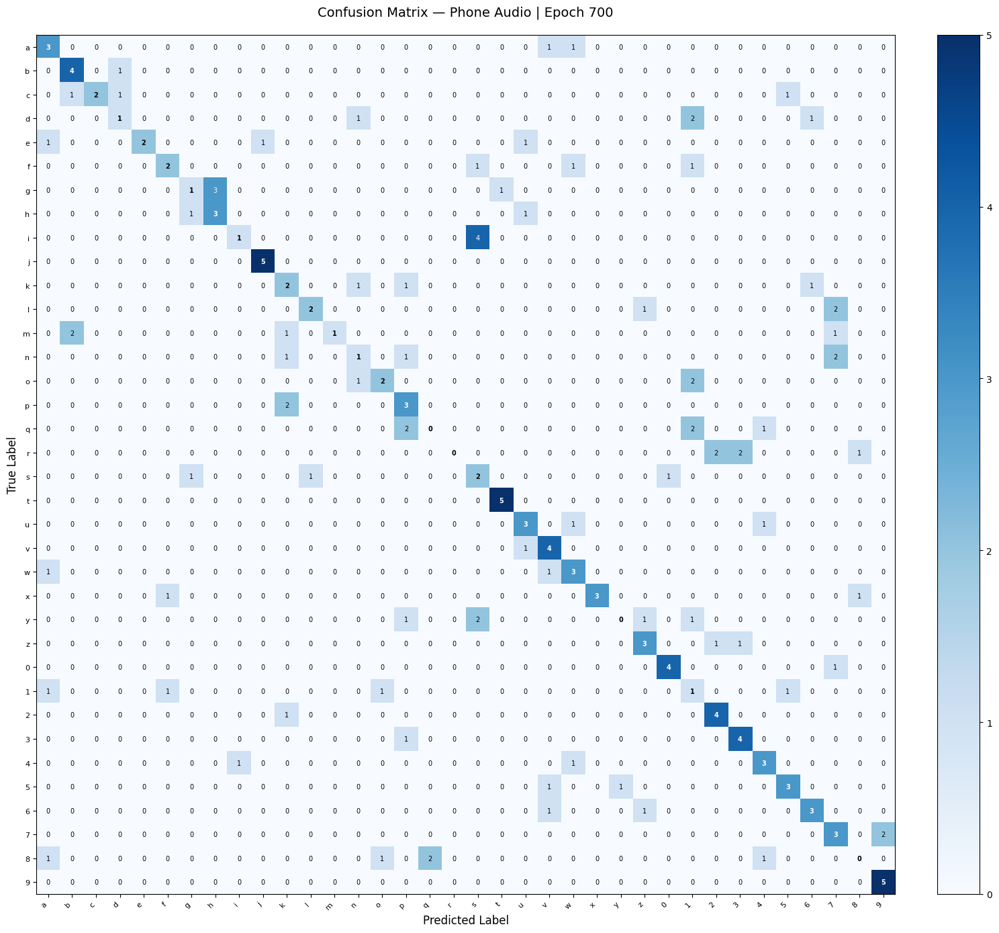

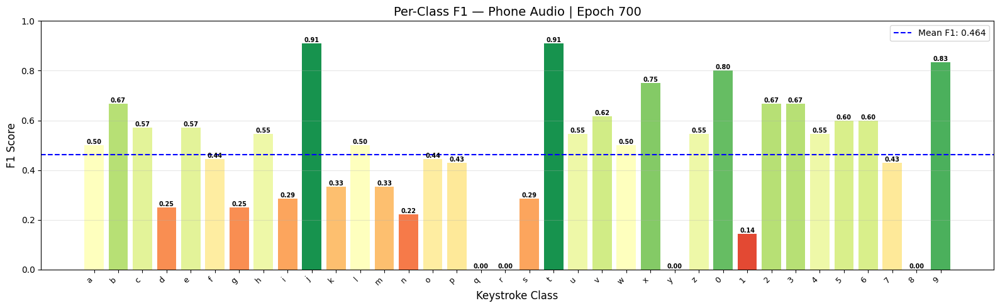

  Time      : 2.05s
  Train     → Loss: 0.0042 | Acc: 0.9922
  Val       → Loss: 4.5372   | Acc: 0.4889
  Weighted  → P: 0.4950 | R: 0.4889 | F1: 0.4636

Epoch 701/1100
------------------------------------------------------------



  Validation Results — Phone Audio | Epoch 701
  Accuracy  : 0.4556
  Precision : 0.4826  (weighted)
  Recall    : 0.4556  (weighted)
  F1 Score  : 0.4442  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.5000     0.6000     0.5455          5
  c              0.5000     0.6000     0.5455          5
  d              0.5000     0.4000     0.4444          5
  e              0.7500     0.6000     0.6667          5
  f              0.3333     0.2000     0.2500          5
  g              0.5000     0.2000     0.2857          5
  h              0.3750     0.6000     0.4615          5
  i              0.5000     0.2000     0.2857          5
  j              0.8000     0.8000     0.8000          5
  k              0.2857     0.4000     0.3333          5
  l              0.6667     0.4000     0.5000          5
  m              1.


  Validation Results — Phone Audio | Epoch 702
  Accuracy  : 0.4778
  Precision : 0.5093  (weighted)
  Recall    : 0.4778  (weighted)
  F1 Score  : 0.4626  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4286     0.6000     0.5000          5
  b              0.5000     0.6000     0.5455          5
  c              0.4286     0.6000     0.5000          5
  d              0.6000     0.6000     0.6000          5
  e              1.0000     0.4000     0.5714          5
  f              0.3333     0.2000     0.2500          5
  g              0.5000     0.2000     0.2857          5
  h              0.3750     0.6000     0.4615          5
  i              0.5000     0.2000     0.2857          5
  j              0.6667     0.8000     0.7273          5
  k              0.2857     0.4000     0.3333          5
  l              0.8000     0.8000     0.8000          5
  m              1.


  Validation Results — Phone Audio | Epoch 703
  Accuracy  : 0.4944
  Precision : 0.4933  (weighted)
  Recall    : 0.4944  (weighted)
  F1 Score  : 0.4741  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3750     0.6000     0.4615          5
  b              0.3333     0.6000     0.4286          5
  c              0.5000     0.6000     0.5455          5
  d              0.5000     0.4000     0.4444          5
  e              0.6667     0.4000     0.5000          5
  f              0.2500     0.2000     0.2222          5
  g              0.4000     0.4000     0.4000          5
  h              0.5000     0.4000     0.4444          5
  i              0.4000     0.4000     0.4000          5
  j              0.7500     0.6000     0.6667          5
  k              0.4286     0.6000     0.5000          5
  l              0.8000     0.8000     0.8000          5
  m              1.


  Validation Results — Phone Audio | Epoch 704
  Accuracy  : 0.4667
  Precision : 0.4915  (weighted)
  Recall    : 0.4667  (weighted)
  F1 Score  : 0.4550  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4444     0.8000     0.5714          5
  b              0.5000     0.4000     0.4444          5
  c              0.4286     0.6000     0.5000          5
  d              0.3333     0.2000     0.2500          5
  e              0.5000     0.4000     0.4444          5
  f              0.4000     0.4000     0.4000          5
  g              0.2000     0.2000     0.2000          5
  h              0.6000     0.6000     0.6000          5
  i              0.3333     0.2000     0.2500          5
  j              0.7500     0.6000     0.6667          5
  k              0.2000     0.2000     0.2000          5
  l              0.6667     0.8000     0.7273          5
  m              1.

...


  Validation Results — Phone Audio | Epoch 796
  Accuracy  : 0.4444
  Precision : 0.4518  (weighted)
  Recall    : 0.4444  (weighted)
  F1 Score  : 0.4257  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.8000     0.6154          5
  b              0.3333     0.4000     0.3636          5
  c              0.5714     0.8000     0.6667          5
  d              0.0000     0.0000     0.0000          5
  e              0.5000     0.4000     0.4444          5
  f              0.2500     0.2000     0.2222          5
  g              0.4000     0.4000     0.4000          5
  h              0.5000     0.4000     0.4444          5
  i              1.0000     0.2000     0.3333          5
  j              0.6000     0.6000     0.6000          5
  k              0.2857     0.4000     0.3333          5
  l              1.0000     0.8000     0.8889          5
  m              0.


  Validation Results — Phone Audio | Epoch 797
  Accuracy  : 0.4333
  Precision : 0.4796  (weighted)
  Recall    : 0.4333  (weighted)
  F1 Score  : 0.4329  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4444     0.8000     0.5714          5
  b              0.3333     0.4000     0.3636          5
  c              0.4000     0.4000     0.4000          5
  d              0.3333     0.2000     0.2500          5
  e              1.0000     0.4000     0.5714          5
  f              0.4000     0.4000     0.4000          5
  g              0.6667     0.4000     0.5000          5
  h              0.5000     0.4000     0.4444          5
  i              1.0000     0.2000     0.3333          5
  j              0.6000     0.6000     0.6000          5
  k              0.1667     0.2000     0.1818          5
  l              0.7500     0.6000     0.6667          5
  m              0.


  Validation Results — Phone Audio | Epoch 798
  Accuracy  : 0.4278
  Precision : 0.4758  (weighted)
  Recall    : 0.4278  (weighted)
  F1 Score  : 0.4243  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.3750     0.6000     0.4615          5
  c              0.3333     0.4000     0.3636          5
  d              0.0000     0.0000     0.0000          5
  e              0.5000     0.4000     0.4444          5
  f              0.2500     0.4000     0.3077          5
  g              0.6667     0.4000     0.5000          5
  h              0.6667     0.4000     0.5000          5
  i              0.5000     0.4000     0.4444          5
  j              0.5556     1.0000     0.7143          5
  k              0.2000     0.2000     0.2000          5
  l              1.0000     0.8000     0.8889          5
  m              1.


  Validation Results — Phone Audio | Epoch 799
  Accuracy  : 0.4722
  Precision : 0.5002  (weighted)
  Recall    : 0.4722  (weighted)
  F1 Score  : 0.4524  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5714     0.8000     0.6667          5
  b              0.4000     0.4000     0.4000          5
  c              0.3750     0.6000     0.4615          5
  d              0.3333     0.2000     0.2500          5
  e              1.0000     0.6000     0.7500          5
  f              0.3333     0.4000     0.3636          5
  g              0.5000     0.6000     0.5455          5
  h              0.7500     0.6000     0.6667          5
  i              1.0000     0.2000     0.3333          5
  j              0.7143     1.0000     0.8333          5
  k              0.3333     0.6000     0.4286          5
  l              0.7500     0.6000     0.6667          5
  m              0.


  Validation Results — Phone Audio | Epoch 800
  Accuracy  : 0.4278
  Precision : 0.4560  (weighted)
  Recall    : 0.4278  (weighted)
  F1 Score  : 0.4149  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3636     0.8000     0.5000          5
  b              0.5000     0.2000     0.2857          5
  c              0.5000     0.8000     0.6154          5
  d              0.6667     0.4000     0.5000          5
  e              0.7500     0.6000     0.6667          5
  f              0.1429     0.2000     0.1667          5
  g              1.0000     0.4000     0.5714          5
  h              0.7500     0.6000     0.6667          5
  i              0.3333     0.2000     0.2500          5
  j              0.4000     0.4000     0.4000          5
  k              0.0000     0.0000     0.0000          5
  l              1.0000     0.8000     0.8889          5
  m              1.

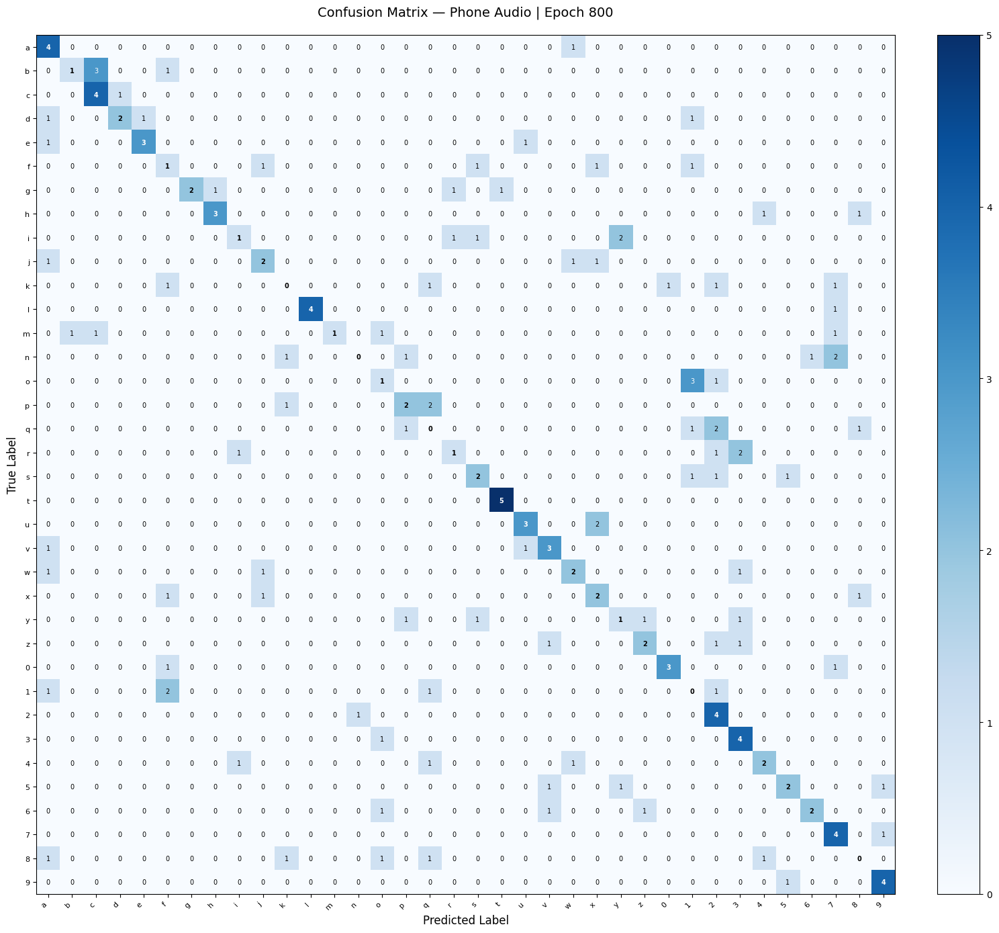

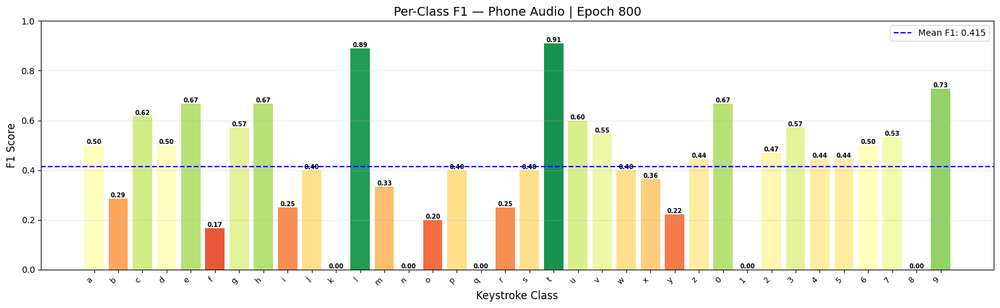

  Time      : 2.70s
  Train     → Loss: 0.0022 | Acc: 0.9958
  Val       → Loss: 4.6735   | Acc: 0.4278
  Weighted  → P: 0.4560 | R: 0.4278 | F1: 0.4149

Epoch 801/1100
------------------------------------------------------------



  Validation Results — Phone Audio | Epoch 801
  Accuracy  : 0.4333
  Precision : 0.4339  (weighted)
  Recall    : 0.4333  (weighted)
  F1 Score  : 0.4192  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3000     0.6000     0.4000          5
  b              0.2000     0.2000     0.2000          5
  c              0.3750     0.6000     0.4615          5
  d              0.6667     0.4000     0.5000          5
  e              0.7500     0.6000     0.6667          5
  f              0.2500     0.2000     0.2222          5
  g              0.6667     0.4000     0.5000          5
  h              1.0000     0.6000     0.7500          5
  i              0.3333     0.2000     0.2500          5
  j              0.5000     0.4000     0.4444          5
  k              0.0000     0.0000     0.0000          5
  l              1.0000     0.8000     0.8889          5
  m              0.


  Validation Results — Phone Audio | Epoch 802
  Accuracy  : 0.4667
  Precision : 0.4748  (weighted)
  Recall    : 0.4667  (weighted)
  F1 Score  : 0.4536  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4444     0.8000     0.5714          5
  b              0.5000     0.4000     0.4444          5
  c              0.3000     0.6000     0.4000          5
  d              0.3333     0.2000     0.2500          5
  e              0.7500     0.6000     0.6667          5
  f              0.2000     0.2000     0.2000          5
  g              0.4000     0.4000     0.4000          5
  h              1.0000     0.4000     0.5714          5
  i              0.5000     0.4000     0.4444          5
  j              0.7500     0.6000     0.6667          5
  k              0.3333     0.4000     0.3636          5
  l              0.8000     0.8000     0.8000          5
  m              1.


  Validation Results — Phone Audio | Epoch 803
  Accuracy  : 0.4444
  Precision : 0.4444  (weighted)
  Recall    : 0.4444  (weighted)
  F1 Score  : 0.4316  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.6000     0.5455          5
  b              0.5000     0.6000     0.5455          5
  c              0.4286     0.6000     0.5000          5
  d              0.3333     0.2000     0.2500          5
  e              0.6000     0.6000     0.6000          5
  f              0.3333     0.4000     0.3636          5
  g              0.6667     0.4000     0.5000          5
  h              0.6667     0.4000     0.5000          5
  i              0.3333     0.2000     0.2500          5
  j              1.0000     0.6000     0.7500          5
  k              0.1667     0.2000     0.1818          5
  l              1.0000     0.8000     0.8889          5
  m              0.


  Validation Results — Phone Audio | Epoch 804
  Accuracy  : 0.4444
  Precision : 0.4512  (weighted)
  Recall    : 0.4444  (weighted)
  F1 Score  : 0.4333  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.6000     0.5455          5
  b              0.5000     0.6000     0.5455          5
  c              0.4286     0.6000     0.5000          5
  d              0.3333     0.2000     0.2500          5
  e              0.6000     0.6000     0.6000          5
  f              0.3333     0.4000     0.3636          5
  g              0.6667     0.4000     0.5000          5
  h              0.6667     0.4000     0.5000          5
  i              0.5000     0.2000     0.2857          5
  j              1.0000     0.6000     0.7500          5
  k              0.1667     0.2000     0.1818          5
  l              1.0000     0.8000     0.8889          5
  m              0.

...


  Validation Results — Phone Audio | Epoch 896
  Accuracy  : 0.4778
  Precision : 0.4945  (weighted)
  Recall    : 0.4778  (weighted)
  F1 Score  : 0.4670  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3000     0.6000     0.4000          5
  b              0.4286     0.6000     0.5000          5
  c              0.4286     0.6000     0.5000          5
  d              0.3333     0.2000     0.2500          5
  e              0.6667     0.4000     0.5000          5
  f              0.5000     0.6000     0.5455          5
  g              0.7500     0.6000     0.6667          5
  h              0.5000     0.4000     0.4444          5
  i              0.3333     0.2000     0.2500          5
  j              1.0000     0.6000     0.7500          5
  k              0.3750     0.6000     0.4615          5
  l              0.7500     0.6000     0.6667          5
  m              0.


  Validation Results — Phone Audio | Epoch 897
  Accuracy  : 0.4556
  Precision : 0.4984  (weighted)
  Recall    : 0.4556  (weighted)
  F1 Score  : 0.4476  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3636     0.8000     0.5000          5
  b              0.3333     0.4000     0.3636          5
  c              0.6000     0.6000     0.6000          5
  d              0.2000     0.2000     0.2000          5
  e              1.0000     0.4000     0.5714          5
  f              0.3333     0.4000     0.3636          5
  g              0.6667     0.4000     0.5000          5
  h              0.3333     0.4000     0.3636          5
  i              1.0000     0.2000     0.3333          5
  j              1.0000     0.6000     0.7500          5
  k              0.1667     0.2000     0.1818          5
  l              1.0000     0.8000     0.8889          5
  m              0.


  Validation Results — Phone Audio | Epoch 898
  Accuracy  : 0.4278
  Precision : 0.4682  (weighted)
  Recall    : 0.4278  (weighted)
  F1 Score  : 0.4256  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3077     0.8000     0.4444          5
  b              0.4000     0.4000     0.4000          5
  c              0.6000     0.6000     0.6000          5
  d              0.2000     0.2000     0.2000          5
  e              1.0000     0.4000     0.5714          5
  f              0.3333     0.4000     0.3636          5
  g              0.6667     0.4000     0.5000          5
  h              0.4000     0.4000     0.4000          5
  i              0.5000     0.2000     0.2857          5
  j              1.0000     0.6000     0.7500          5
  k              0.1667     0.2000     0.1818          5
  l              0.8000     0.8000     0.8000          5
  m              0.


  Validation Results — Phone Audio | Epoch 899
  Accuracy  : 0.4556
  Precision : 0.4889  (weighted)
  Recall    : 0.4556  (weighted)
  F1 Score  : 0.4466  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.8000     0.5333          5
  b              0.5000     0.4000     0.4444          5
  c              0.3333     0.2000     0.2500          5
  d              0.3333     0.2000     0.2500          5
  e              0.6667     0.4000     0.5000          5
  f              0.2857     0.4000     0.3333          5
  g              1.0000     0.4000     0.5714          5
  h              0.4000     0.4000     0.4000          5
  i              0.5000     0.2000     0.2857          5
  j              0.5000     0.6000     0.5455          5
  k              0.2000     0.2000     0.2000          5
  l              1.0000     0.8000     0.8889          5
  m              1.


  Validation Results — Phone Audio | Epoch 900
  Accuracy  : 0.4667
  Precision : 0.5055  (weighted)
  Recall    : 0.4667  (weighted)
  F1 Score  : 0.4508  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.8000     0.6154          5
  b              0.5000     0.6000     0.5455          5
  c              0.2500     0.4000     0.3077          5
  d              0.3333     0.2000     0.2500          5
  e              1.0000     0.6000     0.7500          5
  f              0.2500     0.2000     0.2222          5
  g              0.6000     0.6000     0.6000          5
  h              0.5000     0.6000     0.5455          5
  i              1.0000     0.2000     0.3333          5
  j              0.5714     0.8000     0.6667          5
  k              0.3333     0.6000     0.4286          5
  l              0.8333     1.0000     0.9091          5
  m              1.

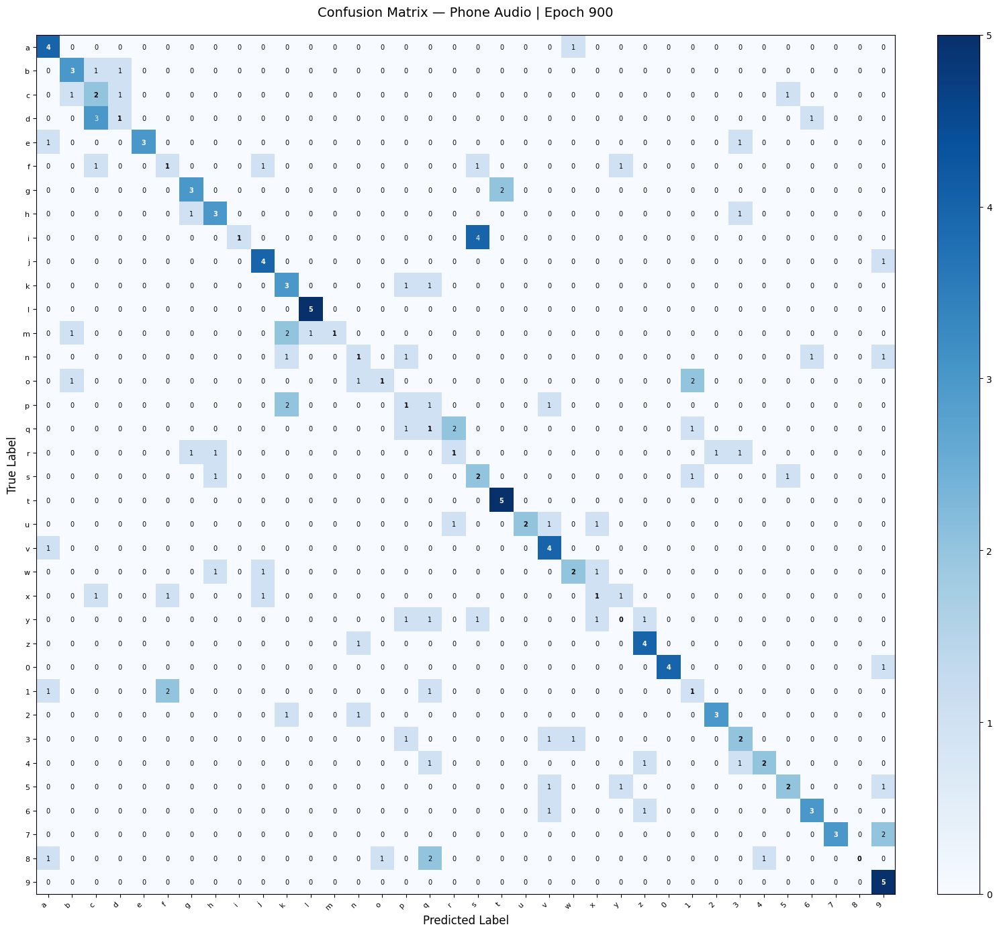

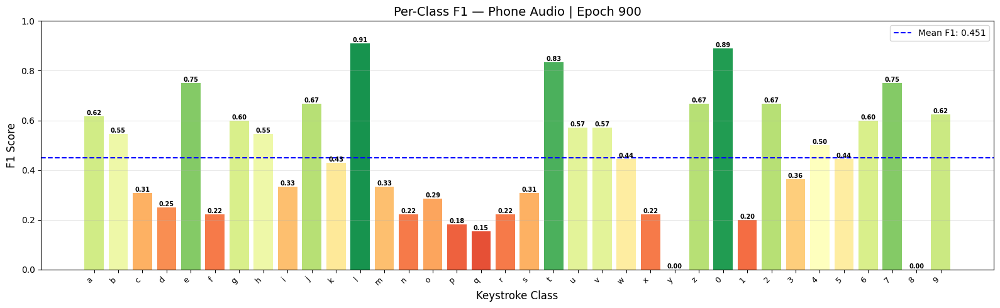

  Time      : 2.52s
  Train     → Loss: 0.0037 | Acc: 0.9904
  Val       → Loss: 4.3183   | Acc: 0.4667
  Weighted  → P: 0.5055 | R: 0.4667 | F1: 0.4508

Epoch 901/1100
------------------------------------------------------------



  Validation Results — Phone Audio | Epoch 901
  Accuracy  : 0.5000
  Precision : 0.4882  (weighted)
  Recall    : 0.5000  (weighted)
  F1 Score  : 0.4776  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.4000     0.3636          5
  b              0.5000     0.6000     0.5455          5
  c              0.4286     0.6000     0.5000          5
  d              0.0000     0.0000     0.0000          5
  e              0.6000     0.6000     0.6000          5
  f              0.1667     0.2000     0.1818          5
  g              0.6000     0.6000     0.6000          5
  h              0.6000     0.6000     0.6000          5
  i              0.5000     0.2000     0.2857          5
  j              0.5714     0.8000     0.6667          5
  k              0.2500     0.2000     0.2222          5
  l              0.7143     1.0000     0.8333          5
  m              0.


  Validation Results — Phone Audio | Epoch 902
  Accuracy  : 0.4833
  Precision : 0.5147  (weighted)
  Recall    : 0.4833  (weighted)
  F1 Score  : 0.4765  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4286     0.6000     0.5000          5
  b              0.6000     0.6000     0.6000          5
  c              0.4286     0.6000     0.5000          5
  d              0.5000     0.2000     0.2857          5
  e              0.7500     0.6000     0.6667          5
  f              0.1429     0.2000     0.1667          5
  g              1.0000     0.6000     0.7500          5
  h              0.6000     0.6000     0.6000          5
  i              0.5000     0.2000     0.2857          5
  j              0.5000     0.6000     0.5455          5
  k              0.2500     0.2000     0.2222          5
  l              0.8333     1.0000     0.9091          5
  m              0.


  Validation Results — Phone Audio | Epoch 903
  Accuracy  : 0.4389
  Precision : 0.4974  (weighted)
  Recall    : 0.4389  (weighted)
  F1 Score  : 0.4260  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.6000     0.4286          5
  b              0.4444     0.8000     0.5714          5
  c              0.4000     0.4000     0.4000          5
  d              0.0000     0.0000     0.0000          5
  e              1.0000     0.2000     0.3333          5
  f              0.2222     0.4000     0.2857          5
  g              0.6667     0.4000     0.5000          5
  h              0.6667     0.4000     0.5000          5
  i              0.5000     0.2000     0.2857          5
  j              0.5000     0.4000     0.4444          5
  k              0.2500     0.2000     0.2222          5
  l              1.0000     0.6000     0.7500          5
  m              0.


  Validation Results — Phone Audio | Epoch 904
  Accuracy  : 0.4778
  Precision : 0.4937  (weighted)
  Recall    : 0.4778  (weighted)
  F1 Score  : 0.4585  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.6000     0.5455          5
  b              0.4286     0.6000     0.5000          5
  c              0.3750     0.6000     0.4615          5
  d              0.0000     0.0000     0.0000          5
  e              1.0000     0.4000     0.5714          5
  f              0.3750     0.6000     0.4615          5
  g              0.5000     0.4000     0.4444          5
  h              0.5000     0.2000     0.2857          5
  i              0.5000     0.2000     0.2857          5
  j              0.8000     0.8000     0.8000          5
  k              0.2000     0.2000     0.2000          5
  l              1.0000     0.8000     0.8889          5
  m              1.

...


  Validation Results — Phone Audio | Epoch 996
  Accuracy  : 0.4667
  Precision : 0.5308  (weighted)
  Recall    : 0.4667  (weighted)
  F1 Score  : 0.4613  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3750     0.6000     0.4615          5
  b              0.3000     0.6000     0.4000          5
  c              0.3750     0.6000     0.4615          5
  d              0.3333     0.2000     0.2500          5
  e              1.0000     0.6000     0.7500          5
  f              0.1667     0.2000     0.1818          5
  g              1.0000     0.2000     0.3333          5
  h              1.0000     0.4000     0.5714          5
  i              0.5000     0.2000     0.2857          5
  j              0.7500     0.6000     0.6667          5
  k              0.2857     0.4000     0.3333          5
  l              1.0000     0.8000     0.8889          5
  m              1.


  Validation Results — Phone Audio | Epoch 997
  Accuracy  : 0.4611
  Precision : 0.5235  (weighted)
  Recall    : 0.4611  (weighted)
  F1 Score  : 0.4561  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3750     0.6000     0.4615          5
  b              0.3333     0.6000     0.4286          5
  c              0.4286     0.6000     0.5000          5
  d              0.2500     0.2000     0.2222          5
  e              1.0000     0.6000     0.7500          5
  f              0.2000     0.2000     0.2000          5
  g              1.0000     0.2000     0.3333          5
  h              0.6667     0.4000     0.5000          5
  i              0.5000     0.2000     0.2857          5
  j              1.0000     0.6000     0.7500          5
  k              0.1667     0.2000     0.1818          5
  l              1.0000     0.8000     0.8889          5
  m              0.


  Validation Results — Phone Audio | Epoch 998
  Accuracy  : 0.4833
  Precision : 0.5500  (weighted)
  Recall    : 0.4833  (weighted)
  F1 Score  : 0.4820  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3750     0.6000     0.4615          5
  b              0.4286     0.6000     0.5000          5
  c              0.5000     0.6000     0.5455          5
  d              0.4000     0.4000     0.4000          5
  e              0.7500     0.6000     0.6667          5
  f              0.2500     0.2000     0.2222          5
  g              1.0000     0.2000     0.3333          5
  h              0.5000     0.4000     0.4444          5
  i              0.5000     0.2000     0.2857          5
  j              0.7500     0.6000     0.6667          5
  k              0.2500     0.4000     0.3077          5
  l              0.8000     0.8000     0.8000          5
  m              0.


  Validation Results — Phone Audio | Epoch 999
  Accuracy  : 0.4222
  Precision : 0.4569  (weighted)
  Recall    : 0.4222  (weighted)
  F1 Score  : 0.4170  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3750     0.6000     0.4615          5
  b              0.5000     0.6000     0.5455          5
  c              0.5000     0.6000     0.5455          5
  d              0.3333     0.2000     0.2500          5
  e              0.5000     0.4000     0.4444          5
  f              0.1429     0.2000     0.1667          5
  g              1.0000     0.4000     0.5714          5
  h              0.4000     0.4000     0.4000          5
  i              0.5000     0.4000     0.4444          5
  j              0.5000     0.2000     0.2857          5
  k              0.0000     0.0000     0.0000          5
  l              1.0000     0.6000     0.7500          5
  m              0.


  Validation Results — Phone Audio | Epoch 1000
  Accuracy  : 0.4611
  Precision : 0.5096  (weighted)
  Recall    : 0.4611  (weighted)
  F1 Score  : 0.4596  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4286     0.6000     0.5000          5
  b              0.3750     0.6000     0.4615          5
  c              0.4286     0.6000     0.5000          5
  d              0.2500     0.2000     0.2222          5
  e              0.5000     0.6000     0.5455          5
  f              0.1667     0.2000     0.1818          5
  g              0.5000     0.4000     0.4444          5
  h              0.6667     0.4000     0.5000          5
  i              0.5000     0.2000     0.2857          5
  j              1.0000     0.2000     0.3333          5
  k              0.2857     0.4000     0.3333          5
  l              1.0000     0.8000     0.8889          5
  m              0

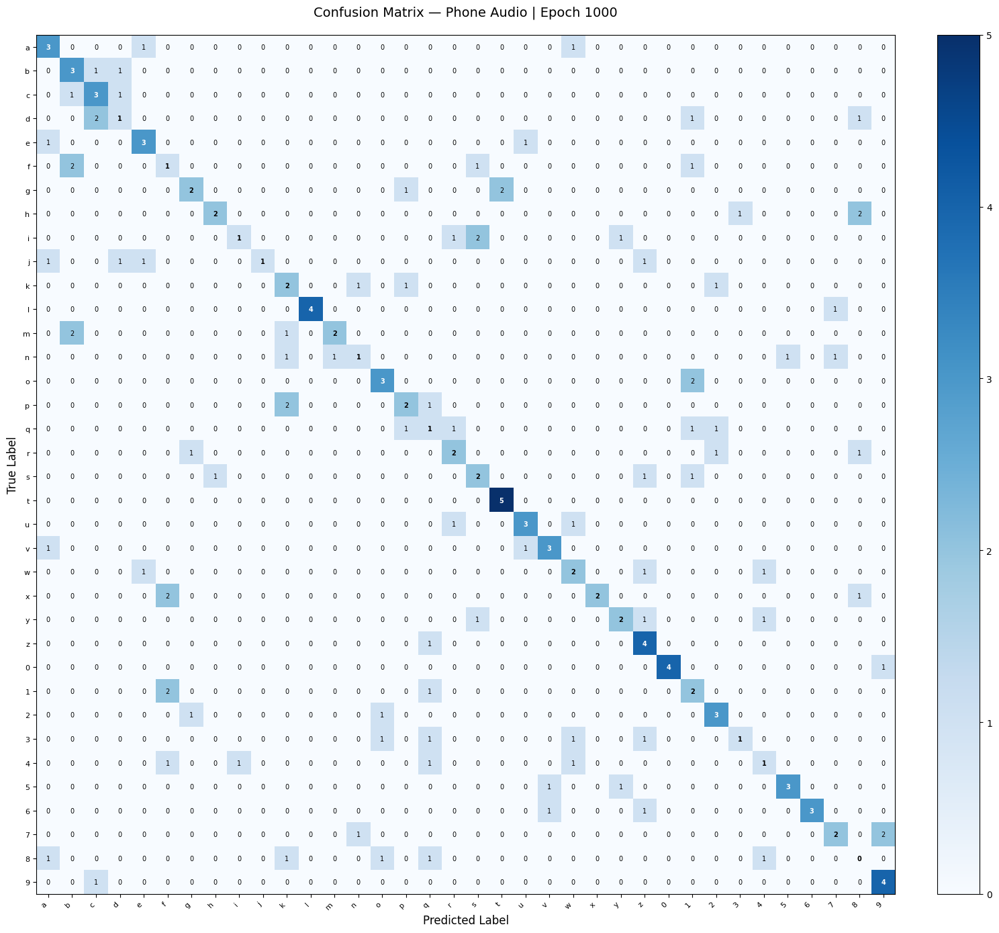

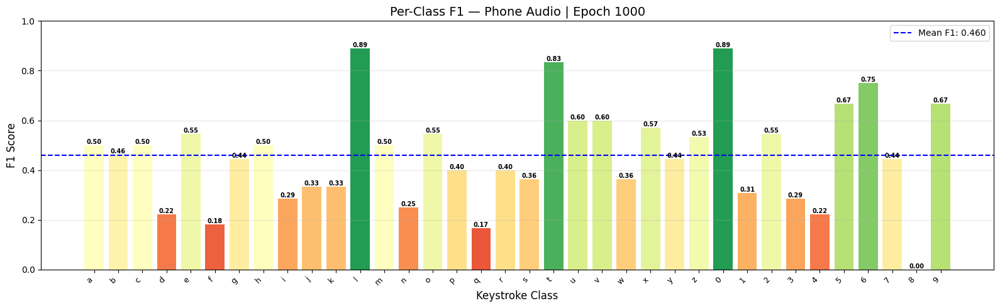

  Time      : 2.03s
  Train     → Loss: 0.0018 | Acc: 1.0000
  Val       → Loss: 5.2067   | Acc: 0.4611
  Weighted  → P: 0.5096 | R: 0.4611 | F1: 0.4596

Epoch 1001/1100
------------------------------------------------------------



  Validation Results — Phone Audio | Epoch 1001
  Accuracy  : 0.4778
  Precision : 0.5042  (weighted)
  Recall    : 0.4778  (weighted)
  F1 Score  : 0.4692  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.6000     0.4286          5
  b              0.5000     0.6000     0.5455          5
  c              0.4000     0.4000     0.4000          5
  d              0.5000     0.4000     0.4444          5
  e              0.4286     0.6000     0.5000          5
  f              0.4286     0.6000     0.5000          5
  g              0.5000     0.4000     0.4444          5
  h              0.7500     0.6000     0.6667          5
  i              0.6667     0.4000     0.5000          5
  j              0.7500     0.6000     0.6667          5
  k              0.2500     0.4000     0.3077          5
  l              0.7143     1.0000     0.8333          5
  m              1


  Validation Results — Phone Audio | Epoch 1002
  Accuracy  : 0.4611
  Precision : 0.5168  (weighted)
  Recall    : 0.4611  (weighted)
  F1 Score  : 0.4646  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.6000     0.4286          5
  b              0.4000     0.4000     0.4000          5
  c              0.5000     0.4000     0.4444          5
  d              0.5000     0.4000     0.4444          5
  e              0.3333     0.4000     0.3636          5
  f              0.1667     0.2000     0.1818          5
  g              0.5000     0.4000     0.4444          5
  h              0.5000     0.4000     0.4444          5
  i              1.0000     0.4000     0.5714          5
  j              0.5714     0.8000     0.6667          5
  k              0.2500     0.4000     0.3077          5
  l              0.8333     1.0000     0.9091          5
  m              1


  Validation Results — Phone Audio | Epoch 1003
  Accuracy  : 0.4444
  Precision : 0.5237  (weighted)
  Recall    : 0.4444  (weighted)
  F1 Score  : 0.4477  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2727     0.6000     0.3750          5
  b              0.5000     0.4000     0.4444          5
  c              0.5000     0.2000     0.2857          5
  d              0.3333     0.2000     0.2500          5
  e              0.6667     0.4000     0.5000          5
  f              0.1250     0.2000     0.1538          5
  g              1.0000     0.4000     0.5714          5
  h              0.5000     0.4000     0.4444          5
  i              1.0000     0.2000     0.3333          5
  j              0.6667     0.8000     0.7273          5
  k              0.2000     0.2000     0.2000          5
  l              0.8000     0.8000     0.8000          5
  m              1


  Validation Results — Phone Audio | Epoch 1004
  Accuracy  : 0.4500
  Precision : 0.5297  (weighted)
  Recall    : 0.4500  (weighted)
  F1 Score  : 0.4521  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3000     0.6000     0.4000          5
  b              0.5000     0.4000     0.4444          5
  c              0.3333     0.2000     0.2500          5
  d              0.0000     0.0000     0.0000          5
  e              1.0000     0.4000     0.5714          5
  f              0.1250     0.2000     0.1538          5
  g              1.0000     0.4000     0.5714          5
  h              0.5000     0.4000     0.4444          5
  i              1.0000     0.4000     0.5714          5
  j              0.7143     1.0000     0.8333          5
  k              0.2000     0.2000     0.2000          5
  l              0.8000     0.8000     0.8000          5
  m              1

...


  Validation Results — Phone Audio | Epoch 1096
  Accuracy  : 0.4667
  Precision : 0.5341  (weighted)
  Recall    : 0.4667  (weighted)
  F1 Score  : 0.4513  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2857     0.4000     0.3333          5
  b              0.3333     0.4000     0.3636          5
  c              0.3333     0.8000     0.4706          5
  d              0.0000     0.0000     0.0000          5
  e              1.0000     0.4000     0.5714          5
  f              0.2857     0.4000     0.3333          5
  g              0.5000     0.4000     0.4444          5
  h              1.0000     0.2000     0.3333          5
  i              0.3333     0.2000     0.2500          5
  j              0.7500     0.6000     0.6667          5
  k              0.3000     0.6000     0.4000          5
  l              0.8000     0.8000     0.8000          5
  m              0


  Validation Results — Phone Audio | Epoch 1097
  Accuracy  : 0.4278
  Precision : 0.4627  (weighted)
  Recall    : 0.4278  (weighted)
  F1 Score  : 0.4143  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2857     0.4000     0.3333          5
  b              0.3077     0.8000     0.4444          5
  c              0.6000     0.6000     0.6000          5
  d              0.3333     0.2000     0.2500          5
  e              1.0000     0.2000     0.3333          5
  f              0.2000     0.2000     0.2000          5
  g              0.5000     0.2000     0.2857          5
  h              0.6667     0.4000     0.5000          5
  i              0.5000     0.2000     0.2857          5
  j              0.7500     0.6000     0.6667          5
  k              0.2222     0.4000     0.2857          5
  l              0.8333     1.0000     0.9091          5
  m              0


  Validation Results — Phone Audio | Epoch 1098
  Accuracy  : 0.4500
  Precision : 0.4876  (weighted)
  Recall    : 0.4500  (weighted)
  F1 Score  : 0.4406  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2857     0.4000     0.3333          5
  b              0.4000     0.8000     0.5333          5
  c              0.6000     0.6000     0.6000          5
  d              0.3333     0.2000     0.2500          5
  e              0.6667     0.4000     0.5000          5
  f              0.1667     0.2000     0.1818          5
  g              0.6667     0.4000     0.5000          5
  h              0.4000     0.4000     0.4000          5
  i              1.0000     0.2000     0.3333          5
  j              0.6000     0.6000     0.6000          5
  k              0.1667     0.2000     0.1818          5
  l              1.0000     1.0000     1.0000          5
  m              1


  Validation Results — Phone Audio | Epoch 1099
  Accuracy  : 0.4500
  Precision : 0.4935  (weighted)
  Recall    : 0.4500  (weighted)
  F1 Score  : 0.4469  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2857     0.4000     0.3333          5
  b              0.3000     0.6000     0.4000          5
  c              0.5000     0.6000     0.5455          5
  d              0.3333     0.2000     0.2500          5
  e              1.0000     0.4000     0.5714          5
  f              0.2000     0.2000     0.2000          5
  g              0.6667     0.4000     0.5000          5
  h              0.6667     0.4000     0.5000          5
  i              0.4000     0.4000     0.4000          5
  j              0.5000     0.6000     0.5455          5
  k              0.1429     0.2000     0.1667          5
  l              1.0000     1.0000     1.0000          5
  m              1


  Validation Results — Phone Audio | Epoch 1100
  Accuracy  : 0.4500
  Precision : 0.4965  (weighted)
  Recall    : 0.4500  (weighted)
  F1 Score  : 0.4445  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.4000     0.3636          5
  b              0.3333     0.6000     0.4286          5
  c              0.4286     0.6000     0.5000          5
  d              0.3333     0.2000     0.2500          5
  e              1.0000     0.4000     0.5714          5
  f              0.2500     0.2000     0.2222          5
  g              0.6667     0.4000     0.5000          5
  h              0.6667     0.4000     0.5000          5
  i              0.4000     0.4000     0.4000          5
  j              0.5000     0.6000     0.5455          5
  k              0.1429     0.2000     0.1667          5
  l              0.8333     1.0000     0.9091          5
  m              1

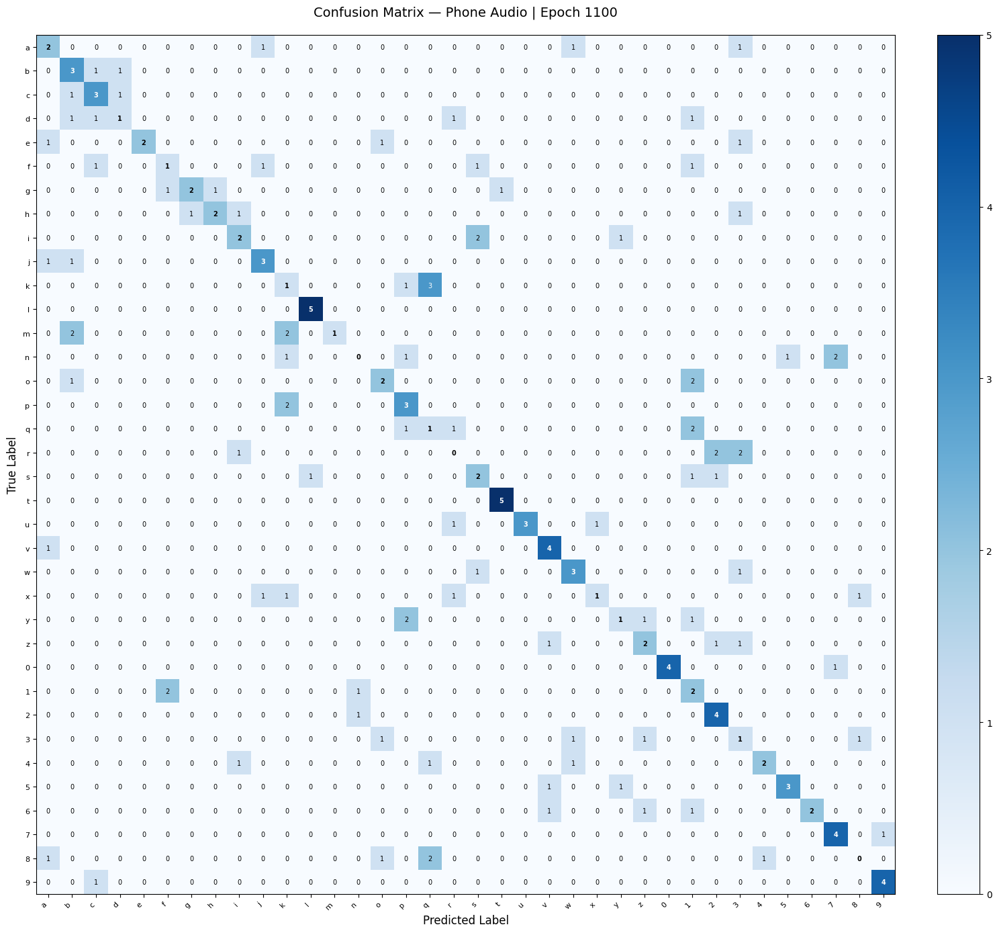

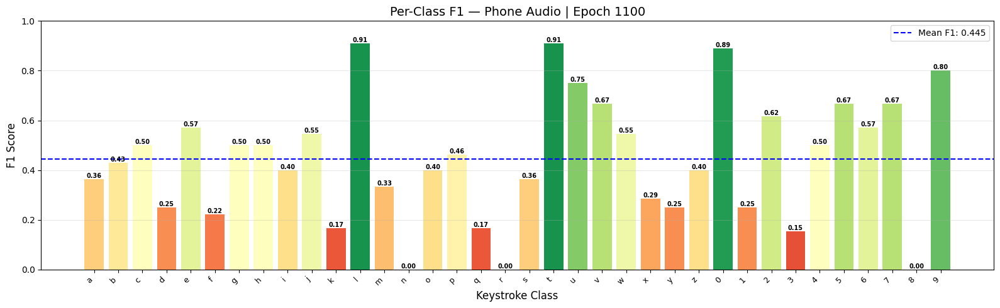

  Time      : 1.20s
  Train     → Loss: 0.0000 | Acc: 1.0000
  Val       → Loss: 4.8054   | Acc: 0.4500
  Weighted  → P: 0.4965 | R: 0.4500 | F1: 0.4445

✓ Loaded best Phone Audio weights  (F1: 0.5278)

  STARTING TRAINING: Zoom Audio
  Epochs     : 1100
  Device     : mps
  Parameters : 276,580

Epoch 1/1100
------------------------------------------------------------



  Validation Results — Zoom Audio | Epoch 1
  Accuracy  : 0.0278
  Precision : 0.0008  (weighted)
  Recall    : 0.0278  (weighted)
  F1 Score  : 0.0015  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.0000     0.0000     0.0000          5
  b              0.0000     0.0000     0.0000          5
  c              0.0000     0.0000     0.0000          5
  d              0.0000     0.0000     0.0000          5
  e              0.0000     0.0000     0.0000          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.0000     0.0000     0.0000          5
  j              0.0000     0.0000     0.0000          5
  k              0.0000     0.0000     0.0000          5
  l              0.0000     0.0000     0.0000          5
  m              0.000


  Validation Results — Zoom Audio | Epoch 2
  Accuracy  : 0.0278
  Precision : 0.0008  (weighted)
  Recall    : 0.0278  (weighted)
  F1 Score  : 0.0015  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.0000     0.0000     0.0000          5
  b              0.0000     0.0000     0.0000          5
  c              0.0000     0.0000     0.0000          5
  d              0.0000     0.0000     0.0000          5
  e              0.0000     0.0000     0.0000          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.0000     0.0000     0.0000          5
  j              0.0000     0.0000     0.0000          5
  k              0.0000     0.0000     0.0000          5
  l              0.0000     0.0000     0.0000          5
  m              0.000


  Validation Results — Zoom Audio | Epoch 3
  Accuracy  : 0.0278
  Precision : 0.0008  (weighted)
  Recall    : 0.0278  (weighted)
  F1 Score  : 0.0015  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.0000     0.0000     0.0000          5
  b              0.0000     0.0000     0.0000          5
  c              0.0000     0.0000     0.0000          5
  d              0.0000     0.0000     0.0000          5
  e              0.0000     0.0000     0.0000          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.0000     0.0000     0.0000          5
  j              0.0000     0.0000     0.0000          5
  k              0.0000     0.0000     0.0000          5
  l              0.0000     0.0000     0.0000          5
  m              0.000


  Validation Results — Zoom Audio | Epoch 4
  Accuracy  : 0.0278
  Precision : 0.0008  (weighted)
  Recall    : 0.0278  (weighted)
  F1 Score  : 0.0015  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.0000     0.0000     0.0000          5
  b              0.0000     0.0000     0.0000          5
  c              0.0000     0.0000     0.0000          5
  d              0.0000     0.0000     0.0000          5
  e              0.0000     0.0000     0.0000          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.0000     0.0000     0.0000          5
  j              0.0000     0.0000     0.0000          5
  k              0.0000     0.0000     0.0000          5
  l              0.0000     0.0000     0.0000          5
  m              0.000

...


  Validation Results — Zoom Audio | Epoch 96
  Accuracy  : 0.3611
  Precision : 0.3862  (weighted)
  Recall    : 0.3611  (weighted)
  F1 Score  : 0.3486  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.6000     0.4286          5
  b              0.4286     0.6000     0.5000          5
  c              0.2000     0.2000     0.2000          5
  d              0.3333     0.8000     0.4706          5
  e              0.2000     0.2000     0.2000          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.2000     0.2000     0.2000          5
  i              0.6667     0.4000     0.5000          5
  j              0.5000     0.4000     0.4444          5
  k              0.2857     0.4000     0.3333          5
  l              0.2000     0.4000     0.2667          5
  m              0.22


  Validation Results — Zoom Audio | Epoch 97
  Accuracy  : 0.3111
  Precision : 0.3226  (weighted)
  Recall    : 0.3111  (weighted)
  F1 Score  : 0.2844  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              1.0000     0.2000     0.3333          5
  b              0.3636     0.8000     0.5000          5
  c              0.2857     0.4000     0.3333          5
  d              0.1818     0.4000     0.2500          5
  e              0.1818     0.4000     0.2500          5
  f              0.3333     0.2000     0.2500          5
  g              0.0000     0.0000     0.0000          5
  h              0.3333     0.2000     0.2500          5
  i              0.6667     0.4000     0.5000          5
  j              0.3000     0.6000     0.4000          5
  k              0.1667     0.2000     0.1818          5
  l              0.1667     0.2000     0.1818          5
  m              0.00


  Validation Results — Zoom Audio | Epoch 98
  Accuracy  : 0.3556
  Precision : 0.3389  (weighted)
  Recall    : 0.3556  (weighted)
  F1 Score  : 0.3251  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.2000     0.2222          5
  b              0.5000     0.6000     0.5455          5
  c              0.5000     0.8000     0.6154          5
  d              0.4000     0.4000     0.4000          5
  e              0.3333     0.4000     0.3636          5
  f              0.4000     0.8000     0.5333          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.6667     0.4000     0.5000          5
  j              0.5000     0.4000     0.4444          5
  k              0.4286     0.6000     0.5000          5
  l              0.1429     0.2000     0.1667          5
  m              0.00


  Validation Results — Zoom Audio | Epoch 99
  Accuracy  : 0.3444
  Precision : 0.3661  (weighted)
  Recall    : 0.3444  (weighted)
  F1 Score  : 0.3302  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.2000     0.2857          5
  b              0.3333     0.6000     0.4286          5
  c              0.3333     0.4000     0.3636          5
  d              0.3333     0.6000     0.4286          5
  e              0.2857     0.4000     0.3333          5
  f              0.3750     0.6000     0.4615          5
  g              0.0000     0.0000     0.0000          5
  h              0.3333     0.2000     0.2500          5
  i              0.6667     0.4000     0.5000          5
  j              0.4000     0.4000     0.4000          5
  k              0.3333     0.6000     0.4286          5
  l              0.1667     0.2000     0.1818          5
  m              0.20


  Validation Results — Zoom Audio | Epoch 100
  Accuracy  : 0.3000
  Precision : 0.2864  (weighted)
  Recall    : 0.3000  (weighted)
  F1 Score  : 0.2801  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2857     0.4000     0.3333          5
  b              0.4000     0.4000     0.4000          5
  c              0.4000     0.4000     0.4000          5
  d              0.3333     0.6000     0.4286          5
  e              0.3000     0.6000     0.4000          5
  f              0.1667     0.2000     0.1818          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.6667     0.4000     0.5000          5
  j              0.5000     0.4000     0.4444          5
  k              0.1667     0.2000     0.1818          5
  l              0.1818     0.4000     0.2500          5
  m              0.0

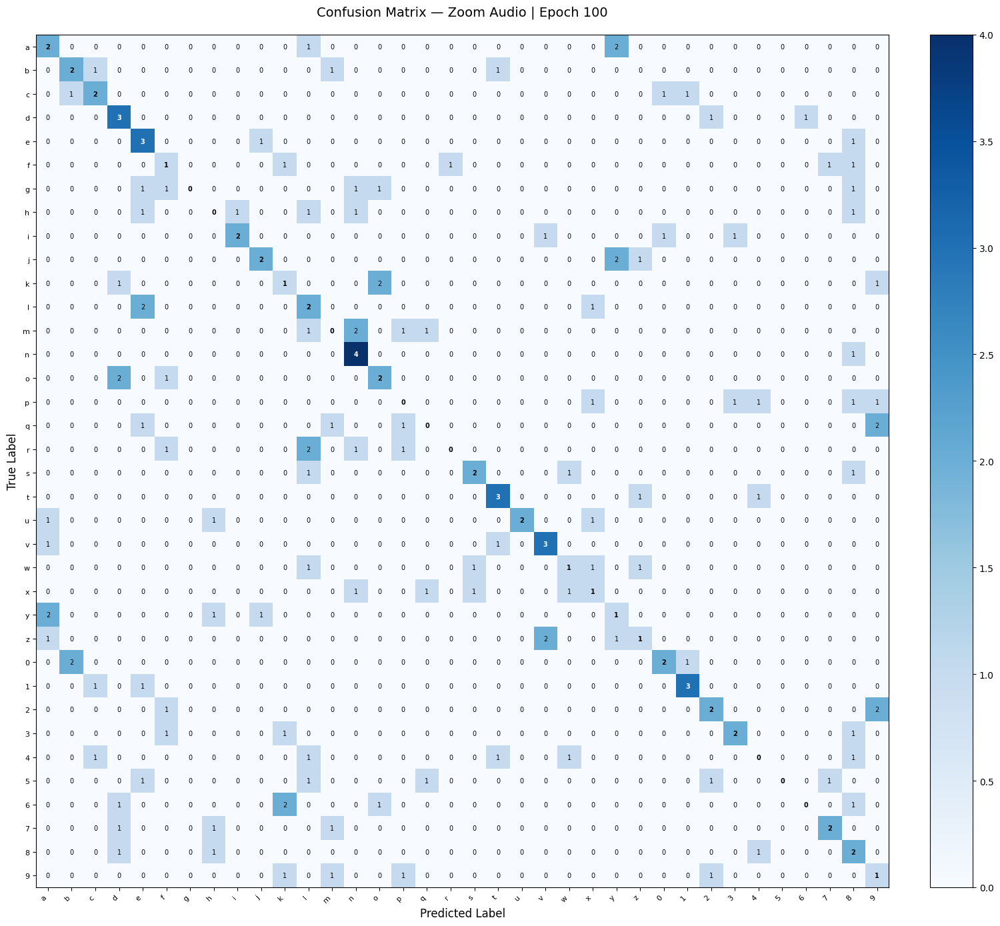

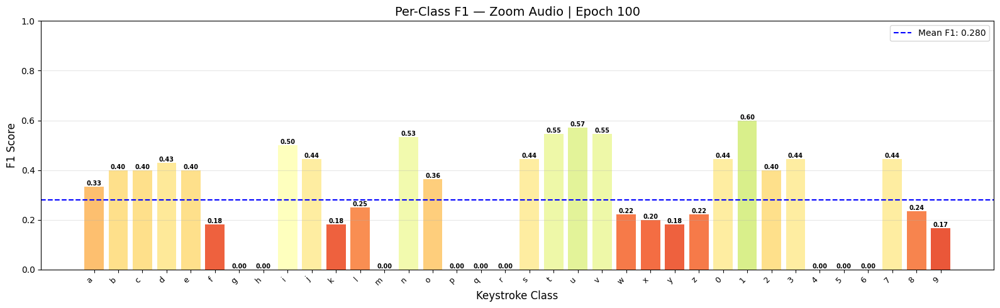

  Time      : 5.31s
  Train     → Loss: 0.8274 | Acc: 0.7764
  Val       → Loss: 2.0957   | Acc: 0.3000
  Weighted  → P: 0.2864 | R: 0.3000 | F1: 0.2801

Epoch 101/1100
------------------------------------------------------------



  Validation Results — Zoom Audio | Epoch 101
  Accuracy  : 0.3278
  Precision : 0.3128  (weighted)
  Recall    : 0.3278  (weighted)
  F1 Score  : 0.3023  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.1667     0.2000     0.1818          5
  b              0.4000     0.4000     0.4000          5
  c              0.5000     0.8000     0.6154          5
  d              0.2500     0.2000     0.2222          5
  e              0.4000     0.4000     0.4000          5
  f              0.3333     0.4000     0.3636          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.4000     0.4000     0.4000          5
  j              0.4000     0.4000     0.4000          5
  k              0.3333     0.2000     0.2500          5
  l              0.1429     0.2000     0.1667          5
  m              0.0


  Validation Results — Zoom Audio | Epoch 102
  Accuracy  : 0.3389
  Precision : 0.3888  (weighted)
  Recall    : 0.3389  (weighted)
  F1 Score  : 0.3301  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.2857     0.4000     0.3333          5
  c              0.5000     0.6000     0.5455          5
  d              1.0000     0.2000     0.3333          5
  e              0.3000     0.6000     0.4000          5
  f              0.4286     0.6000     0.5000          5
  g              0.0000     0.0000     0.0000          5
  h              1.0000     0.2000     0.3333          5
  i              0.4000     0.4000     0.4000          5
  j              0.3636     0.8000     0.5000          5
  k              0.3750     0.6000     0.4615          5
  l              0.1000     0.2000     0.1333          5
  m              0.0


  Validation Results — Zoom Audio | Epoch 103
  Accuracy  : 0.2944
  Precision : 0.3145  (weighted)
  Recall    : 0.2944  (weighted)
  F1 Score  : 0.2900  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.2000     0.2857          5
  b              0.2222     0.4000     0.2857          5
  c              0.3333     0.4000     0.3636          5
  d              0.3333     0.2000     0.2500          5
  e              0.3333     0.2000     0.2500          5
  f              0.6000     0.6000     0.6000          5
  g              0.0000     0.0000     0.0000          5
  h              0.2000     0.2000     0.2000          5
  i              0.5000     0.2000     0.2857          5
  j              0.2222     0.4000     0.2857          5
  k              0.1111     0.2000     0.1429          5
  l              0.0909     0.2000     0.1250          5
  m              0.1


  Validation Results — Zoom Audio | Epoch 104
  Accuracy  : 0.3444
  Precision : 0.4113  (weighted)
  Recall    : 0.3444  (weighted)
  F1 Score  : 0.3334  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              0.2857     0.4000     0.3333          5
  c              0.5000     0.4000     0.4444          5
  d              0.2500     0.2000     0.2222          5
  e              0.2500     0.6000     0.3529          5
  f              0.3333     0.6000     0.4286          5
  g              0.0000     0.0000     0.0000          5
  h              0.5000     0.2000     0.2857          5
  i              0.5000     0.4000     0.4444          5
  j              0.3333     0.4000     0.3636          5
  k              0.2000     0.2000     0.2000          5
  l              0.2222     0.4000     0.2857          5
  m              0.5

...


  Validation Results — Zoom Audio | Epoch 196
  Accuracy  : 0.3222
  Precision : 0.3423  (weighted)
  Recall    : 0.3222  (weighted)
  F1 Score  : 0.3086  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.4000     0.4444          5
  b              0.3750     0.6000     0.4615          5
  c              0.5000     0.8000     0.6154          5
  d              0.2500     0.2000     0.2222          5
  e              0.3333     0.4000     0.3636          5
  f              0.4000     0.4000     0.4000          5
  g              0.3333     0.2000     0.2500          5
  h              0.0000     0.0000     0.0000          5
  i              0.5000     0.4000     0.4444          5
  j              0.3333     0.4000     0.3636          5
  k              0.0000     0.0000     0.0000          5
  l              0.1000     0.2000     0.1333          5
  m              0.0


  Validation Results — Zoom Audio | Epoch 197
  Accuracy  : 0.2833
  Precision : 0.3059  (weighted)
  Recall    : 0.2833  (weighted)
  F1 Score  : 0.2724  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.4000     0.3636          5
  b              0.3000     0.6000     0.4000          5
  c              0.5000     0.6000     0.5455          5
  d              0.1667     0.2000     0.1818          5
  e              0.1765     0.6000     0.2727          5
  f              0.0000     0.0000     0.0000          5
  g              0.2500     0.2000     0.2222          5
  h              0.0000     0.0000     0.0000          5
  i              0.2000     0.2000     0.2000          5
  j              0.3333     0.4000     0.3636          5
  k              0.2500     0.2000     0.2222          5
  l              0.0833     0.2000     0.1176          5
  m              0.0


  Validation Results — Zoom Audio | Epoch 198
  Accuracy  : 0.3056
  Precision : 0.3340  (weighted)
  Recall    : 0.3056  (weighted)
  F1 Score  : 0.3006  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.5000     0.4000     0.4444          5
  c              0.3333     0.6000     0.4286          5
  d              0.2500     0.2000     0.2222          5
  e              0.2222     0.4000     0.2857          5
  f              0.2000     0.4000     0.2667          5
  g              0.0000     0.0000     0.0000          5
  h              0.3333     0.2000     0.2500          5
  i              0.4000     0.4000     0.4000          5
  j              0.2500     0.4000     0.3077          5
  k              0.2000     0.2000     0.2000          5
  l              0.1429     0.4000     0.2105          5
  m              0.0


  Validation Results — Zoom Audio | Epoch 199
  Accuracy  : 0.3333
  Precision : 0.3079  (weighted)
  Recall    : 0.3333  (weighted)
  F1 Score  : 0.3093  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.4000     0.4444          5
  b              0.3333     0.4000     0.3636          5
  c              0.4000     0.8000     0.5333          5
  d              0.3333     0.2000     0.2500          5
  e              0.2857     0.4000     0.3333          5
  f              0.2857     0.4000     0.3333          5
  g              0.0000     0.0000     0.0000          5
  h              0.5000     0.2000     0.2857          5
  i              0.4000     0.4000     0.4000          5
  j              0.3333     0.2000     0.2500          5
  k              0.3750     0.6000     0.4615          5
  l              0.0833     0.2000     0.1176          5
  m              0.0


  Validation Results — Zoom Audio | Epoch 200
  Accuracy  : 0.3333
  Precision : 0.3515  (weighted)
  Recall    : 0.3333  (weighted)
  F1 Score  : 0.3188  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2857     0.4000     0.3333          5
  b              0.3077     0.8000     0.4444          5
  c              0.5000     0.6000     0.5455          5
  d              0.2500     0.4000     0.3077          5
  e              0.3333     0.6000     0.4286          5
  f              0.5000     0.6000     0.5455          5
  g              0.2500     0.2000     0.2222          5
  h              0.2000     0.2000     0.2000          5
  i              1.0000     0.2000     0.3333          5
  j              0.2500     0.2000     0.2222          5
  k              0.1667     0.2000     0.1818          5
  l              0.2500     0.4000     0.3077          5
  m              0.0

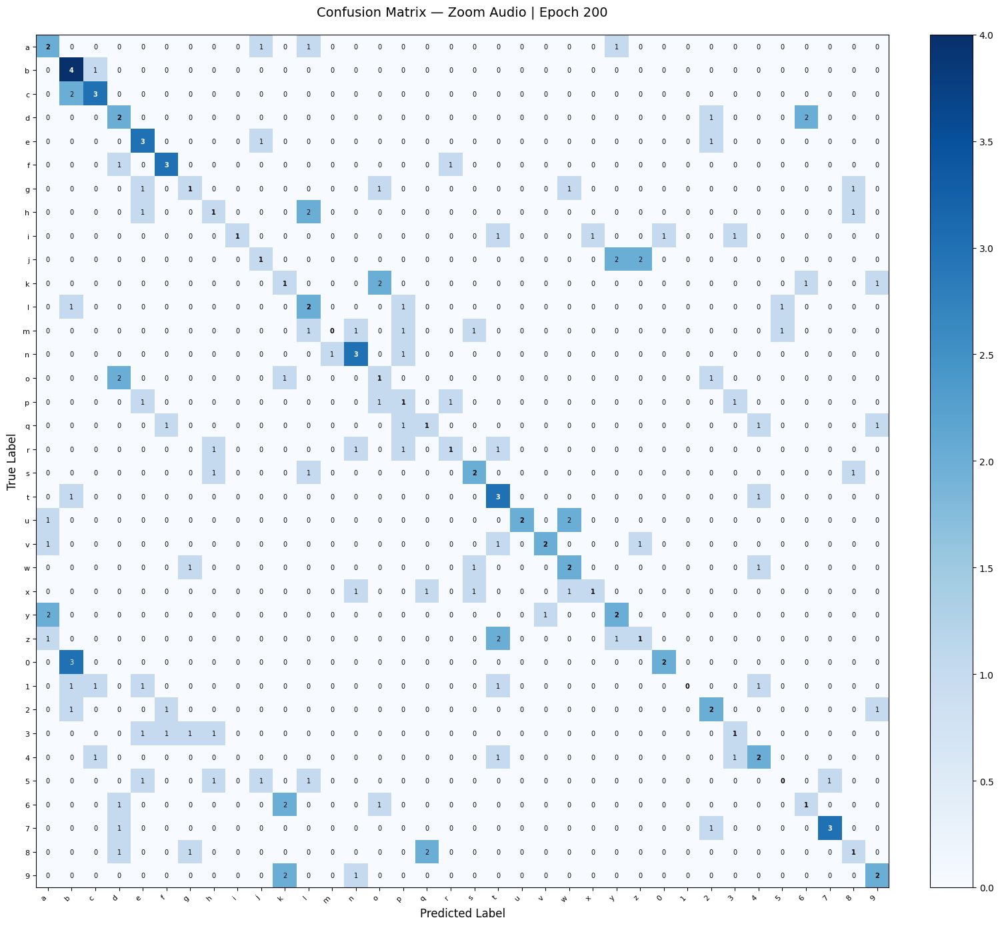

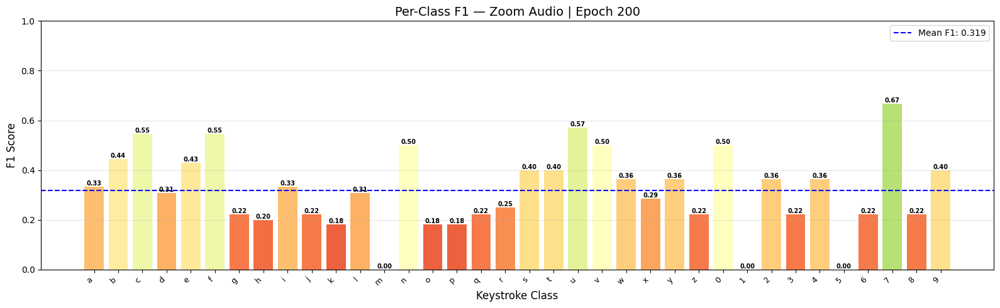

  Time      : 5.00s
  Train     → Loss: 0.1702 | Acc: 0.9583
  Val       → Loss: 2.8032   | Acc: 0.3333
  Weighted  → P: 0.3515 | R: 0.3333 | F1: 0.3188

Epoch 201/1100
------------------------------------------------------------



  Validation Results — Zoom Audio | Epoch 201
  Accuracy  : 0.2833
  Precision : 0.3188  (weighted)
  Recall    : 0.2833  (weighted)
  F1 Score  : 0.2776  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.4000     0.3636          5
  b              0.3000     0.6000     0.4000          5
  c              0.5000     0.4000     0.4444          5
  d              0.1429     0.2000     0.1667          5
  e              0.1667     0.2000     0.1818          5
  f              0.2500     0.4000     0.3077          5
  g              0.3333     0.2000     0.2500          5
  h              0.0000     0.0000     0.0000          5
  i              0.5000     0.2000     0.2857          5
  j              0.6667     0.4000     0.5000          5
  k              0.2857     0.4000     0.3333          5
  l              0.2222     0.4000     0.2857          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 202
  Accuracy  : 0.3056
  Precision : 0.3150  (weighted)
  Recall    : 0.3056  (weighted)
  F1 Score  : 0.2946  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.5000     0.4000     0.4444          5
  c              0.5000     0.8000     0.6154          5
  d              0.3333     0.2000     0.2500          5
  e              0.3750     0.6000     0.4615          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.5000     0.2000     0.2857          5
  i              0.5000     0.4000     0.4444          5
  j              0.4286     0.6000     0.5000          5
  k              0.2500     0.4000     0.3077          5
  l              0.1250     0.2000     0.1538          5
  m              0.0


  Validation Results — Zoom Audio | Epoch 203
  Accuracy  : 0.2833
  Precision : 0.2939  (weighted)
  Recall    : 0.2833  (weighted)
  F1 Score  : 0.2698  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.4000     0.3636          5
  b              0.2500     0.6000     0.3529          5
  c              0.4000     0.4000     0.4000          5
  d              0.2000     0.2000     0.2000          5
  e              0.1875     0.6000     0.2857          5
  f              0.3333     0.2000     0.2500          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.4000     0.4000     0.4000          5
  j              0.5000     0.2000     0.2857          5
  k              0.2000     0.2000     0.2000          5
  l              0.1111     0.2000     0.1429          5
  m              0.0


  Validation Results — Zoom Audio | Epoch 204
  Accuracy  : 0.3167
  Precision : 0.3067  (weighted)
  Recall    : 0.3167  (weighted)
  F1 Score  : 0.2948  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.3333     0.6000     0.4286          5
  c              0.4000     0.4000     0.4000          5
  d              0.2857     0.4000     0.3333          5
  e              0.1429     0.2000     0.1667          5
  f              0.2857     0.4000     0.3333          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.6667     0.4000     0.5000          5
  j              0.6667     0.4000     0.5000          5
  k              0.3333     0.8000     0.4706          5
  l              0.1111     0.2000     0.1429          5
  m              0.2

...


  Validation Results — Zoom Audio | Epoch 296
  Accuracy  : 0.3278
  Precision : 0.3363  (weighted)
  Recall    : 0.3278  (weighted)
  F1 Score  : 0.3203  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.4000     0.3636          5
  b              0.3750     0.6000     0.4615          5
  c              0.2500     0.2000     0.2222          5
  d              0.6667     0.4000     0.5000          5
  e              0.2727     0.6000     0.3750          5
  f              0.5000     0.4000     0.4444          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.2500     0.2000     0.2222          5
  j              0.2000     0.2000     0.2000          5
  k              0.1429     0.2000     0.1667          5
  l              0.1250     0.2000     0.1538          5
  m              0.7


  Validation Results — Zoom Audio | Epoch 297
  Accuracy  : 0.3111
  Precision : 0.3451  (weighted)
  Recall    : 0.3111  (weighted)
  F1 Score  : 0.3073  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.2000     0.2222          5
  b              0.5000     0.6000     0.5455          5
  c              0.5000     0.6000     0.5455          5
  d              0.3333     0.2000     0.2500          5
  e              0.2857     0.4000     0.3333          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.2500     0.2000     0.2222          5
  i              0.2000     0.2000     0.2000          5
  j              0.2000     0.2000     0.2000          5
  k              0.2000     0.2000     0.2000          5
  l              0.1111     0.2000     0.1429          5
  m              0.5


  Validation Results — Zoom Audio | Epoch 298
  Accuracy  : 0.3222
  Precision : 0.3434  (weighted)
  Recall    : 0.3222  (weighted)
  F1 Score  : 0.3146  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.4286     0.6000     0.5000          5
  c              0.4000     0.4000     0.4000          5
  d              0.3333     0.4000     0.3636          5
  e              0.3000     0.6000     0.4000          5
  f              0.2500     0.2000     0.2222          5
  g              0.2500     0.2000     0.2222          5
  h              0.3333     0.2000     0.2500          5
  i              0.0000     0.0000     0.0000          5
  j              0.2222     0.4000     0.2857          5
  k              0.1667     0.2000     0.1818          5
  l              0.0667     0.2000     0.1000          5
  m              0.5


  Validation Results — Zoom Audio | Epoch 299
  Accuracy  : 0.3167
  Precision : 0.3194  (weighted)
  Recall    : 0.3167  (weighted)
  F1 Score  : 0.3033  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.4000     0.3077          5
  b              0.4286     0.6000     0.5000          5
  c              0.3333     0.4000     0.3636          5
  d              0.2857     0.4000     0.3333          5
  e              0.3750     0.6000     0.4615          5
  f              0.2500     0.2000     0.2222          5
  g              0.0000     0.0000     0.0000          5
  h              0.3333     0.2000     0.2500          5
  i              0.2500     0.2000     0.2222          5
  j              0.2857     0.4000     0.3333          5
  k              0.1667     0.2000     0.1818          5
  l              0.0000     0.0000     0.0000          5
  m              0.5


  Validation Results — Zoom Audio | Epoch 300
  Accuracy  : 0.3389
  Precision : 0.3510  (weighted)
  Recall    : 0.3389  (weighted)
  F1 Score  : 0.3149  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              0.3750     0.6000     0.4615          5
  c              0.4000     0.4000     0.4000          5
  d              0.3333     0.2000     0.2500          5
  e              0.3333     0.4000     0.3636          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.5000     0.2000     0.2857          5
  i              0.4000     0.4000     0.4000          5
  j              0.1818     0.4000     0.2500          5
  k              0.0000     0.0000     0.0000          5
  l              0.4000     0.4000     0.4000          5
  m              0.4

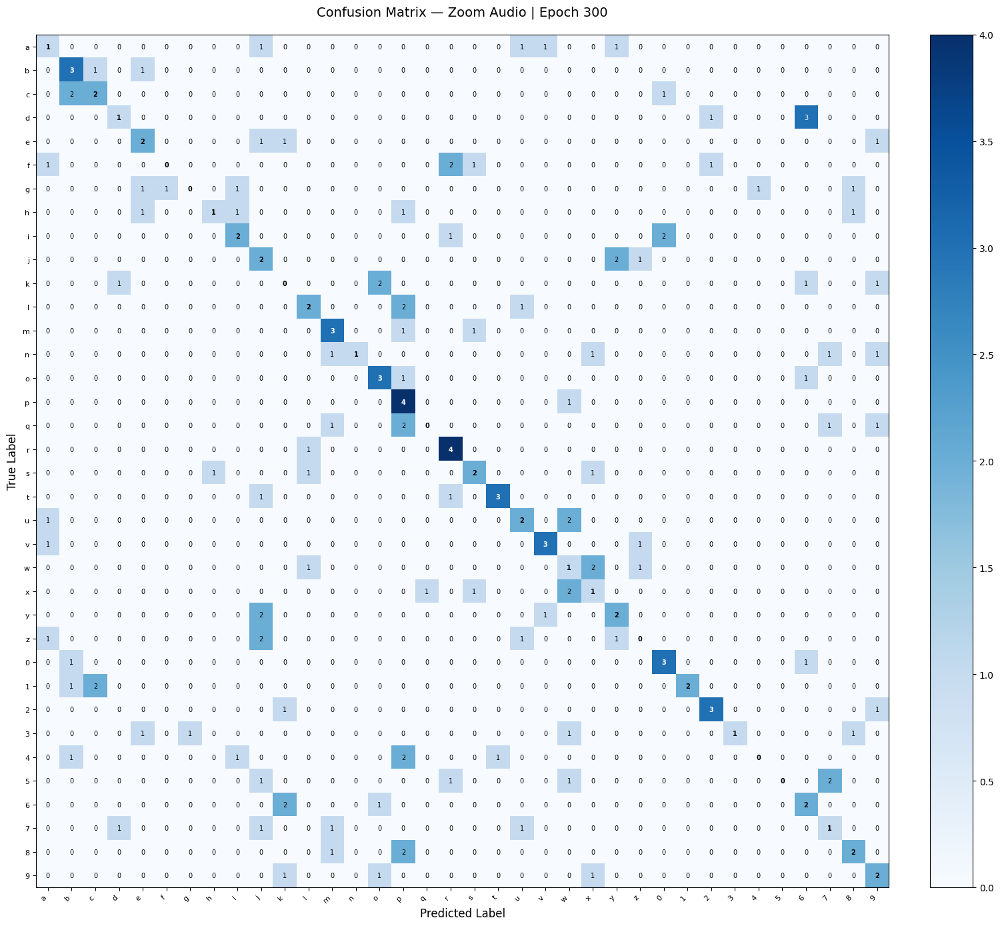

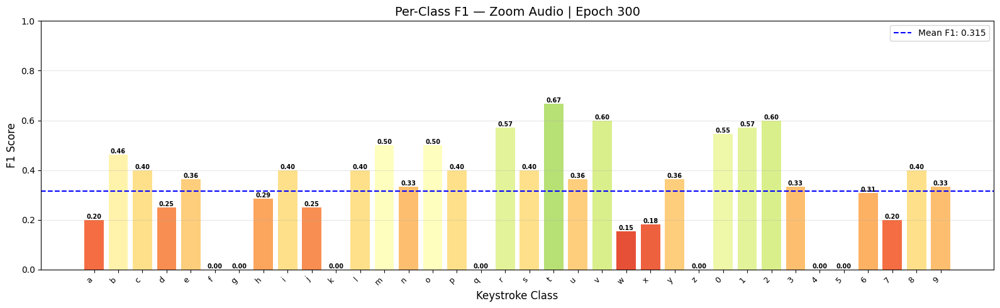

  Time      : 4.88s
  Train     → Loss: 0.0463 | Acc: 0.9875
  Val       → Loss: 3.8498   | Acc: 0.3389
  Weighted  → P: 0.3510 | R: 0.3389 | F1: 0.3149

Epoch 301/1100
------------------------------------------------------------



  Validation Results — Zoom Audio | Epoch 301
  Accuracy  : 0.2944
  Precision : 0.3268  (weighted)
  Recall    : 0.2944  (weighted)
  F1 Score  : 0.2921  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.1250     0.2000     0.1538          5
  b              0.3333     0.4000     0.3636          5
  c              0.1667     0.2000     0.1818          5
  d              0.2500     0.4000     0.3077          5
  e              0.3333     0.6000     0.4286          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.5000     0.2000     0.2857          5
  i              0.3750     0.6000     0.4615          5
  j              0.2500     0.4000     0.3077          5
  k              0.1250     0.2000     0.1538          5
  l              0.1429     0.2000     0.1667          5
  m              0.2


  Validation Results — Zoom Audio | Epoch 302
  Accuracy  : 0.3056
  Precision : 0.3181  (weighted)
  Recall    : 0.3056  (weighted)
  F1 Score  : 0.2843  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2857     0.4000     0.3333          5
  b              0.3333     0.6000     0.4286          5
  c              0.1667     0.2000     0.1818          5
  d              0.2857     0.4000     0.3333          5
  e              0.3000     0.6000     0.4000          5
  f              0.3333     0.2000     0.2500          5
  g              0.0000     0.0000     0.0000          5
  h              0.2000     0.2000     0.2000          5
  i              0.2500     0.2000     0.2222          5
  j              0.0000     0.0000     0.0000          5
  k              0.0000     0.0000     0.0000          5
  l              0.0000     0.0000     0.0000          5
  m              0.2


  Validation Results — Zoom Audio | Epoch 303
  Accuracy  : 0.3500
  Precision : 0.3486  (weighted)
  Recall    : 0.3500  (weighted)
  F1 Score  : 0.3364  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.1429     0.2000     0.1667          5
  b              0.5000     0.6000     0.5455          5
  c              0.2500     0.2000     0.2222          5
  d              0.2500     0.2000     0.2222          5
  e              0.4286     0.6000     0.5000          5
  f              0.4000     0.4000     0.4000          5
  g              0.2500     0.2000     0.2222          5
  h              0.2000     0.2000     0.2000          5
  i              0.2857     0.4000     0.3333          5
  j              0.2500     0.2000     0.2222          5
  k              0.3333     0.4000     0.3636          5
  l              0.2500     0.2000     0.2222          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 304
  Accuracy  : 0.3000
  Precision : 0.3346  (weighted)
  Recall    : 0.3000  (weighted)
  F1 Score  : 0.2911  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.2000     0.2222          5
  b              1.0000     0.2000     0.3333          5
  c              0.3636     0.8000     0.5000          5
  d              0.2500     0.2000     0.2222          5
  e              0.3000     0.6000     0.4000          5
  f              0.2500     0.2000     0.2222          5
  g              0.0000     0.0000     0.0000          5
  h              0.1429     0.2000     0.1667          5
  i              0.2500     0.2000     0.2222          5
  j              0.3333     0.4000     0.3636          5
  k              0.2500     0.2000     0.2222          5
  l              0.1111     0.2000     0.1429          5
  m              0.2

...


  Validation Results — Zoom Audio | Epoch 396
  Accuracy  : 0.3389
  Precision : 0.3273  (weighted)
  Recall    : 0.3389  (weighted)
  F1 Score  : 0.3229  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              0.5000     0.6000     0.5455          5
  c              0.5000     0.6000     0.5455          5
  d              0.2500     0.2000     0.2222          5
  e              0.4286     0.6000     0.5000          5
  f              0.0000     0.0000     0.0000          5
  g              0.2500     0.2000     0.2222          5
  h              0.0000     0.0000     0.0000          5
  i              0.1667     0.2000     0.1818          5
  j              0.2500     0.4000     0.3077          5
  k              0.0000     0.0000     0.0000          5
  l              0.1667     0.2000     0.1818          5
  m              0.5


  Validation Results — Zoom Audio | Epoch 397
  Accuracy  : 0.3222
  Precision : 0.3024  (weighted)
  Recall    : 0.3222  (weighted)
  F1 Score  : 0.2981  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.1818     0.4000     0.2500          5
  b              0.3333     0.6000     0.4286          5
  c              0.3333     0.2000     0.2500          5
  d              0.2500     0.4000     0.3077          5
  e              0.5000     0.4000     0.4444          5
  f              0.2500     0.2000     0.2222          5
  g              0.0000     0.0000     0.0000          5
  h              0.2222     0.4000     0.2857          5
  i              0.2500     0.2000     0.2222          5
  j              0.0000     0.0000     0.0000          5
  k              0.0000     0.0000     0.0000          5
  l              0.2857     0.4000     0.3333          5
  m              0.4


  Validation Results — Zoom Audio | Epoch 398
  Accuracy  : 0.3111
  Precision : 0.3161  (weighted)
  Recall    : 0.3111  (weighted)
  F1 Score  : 0.2960  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.2000     0.2857          5
  b              0.4000     0.4000     0.4000          5
  c              0.1667     0.2000     0.1818          5
  d              0.3333     0.4000     0.3636          5
  e              0.5000     0.6000     0.5455          5
  f              0.0000     0.0000     0.0000          5
  g              0.2500     0.2000     0.2222          5
  h              0.0000     0.0000     0.0000          5
  i              0.2000     0.2000     0.2000          5
  j              0.1429     0.2000     0.1667          5
  k              0.0000     0.0000     0.0000          5
  l              0.2500     0.2000     0.2222          5
  m              0.5


  Validation Results — Zoom Audio | Epoch 399
  Accuracy  : 0.3278
  Precision : 0.3895  (weighted)
  Recall    : 0.3278  (weighted)
  F1 Score  : 0.3266  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.2000     0.2857          5
  b              0.5000     0.6000     0.5455          5
  c              0.5000     0.4000     0.4444          5
  d              0.5000     0.4000     0.4444          5
  e              0.4000     0.4000     0.4000          5
  f              0.0000     0.0000     0.0000          5
  g              0.5000     0.2000     0.2857          5
  h              0.3333     0.2000     0.2500          5
  i              0.3333     0.4000     0.3636          5
  j              0.4000     0.8000     0.5333          5
  k              0.2500     0.2000     0.2222          5
  l              0.0909     0.2000     0.1250          5
  m              0.2


  Validation Results — Zoom Audio | Epoch 400
  Accuracy  : 0.2889
  Precision : 0.3203  (weighted)
  Recall    : 0.2889  (weighted)
  F1 Score  : 0.2820  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.2000     0.2857          5
  b              0.7500     0.6000     0.6667          5
  c              0.3333     0.4000     0.3636          5
  d              0.1667     0.2000     0.1818          5
  e              0.3333     0.6000     0.4286          5
  f              1.0000     0.2000     0.3333          5
  g              0.5000     0.2000     0.2857          5
  h              0.0000     0.0000     0.0000          5
  i              0.0000     0.0000     0.0000          5
  j              0.2500     0.4000     0.3077          5
  k              0.2000     0.2000     0.2000          5
  l              0.2222     0.4000     0.2857          5
  m              0.2

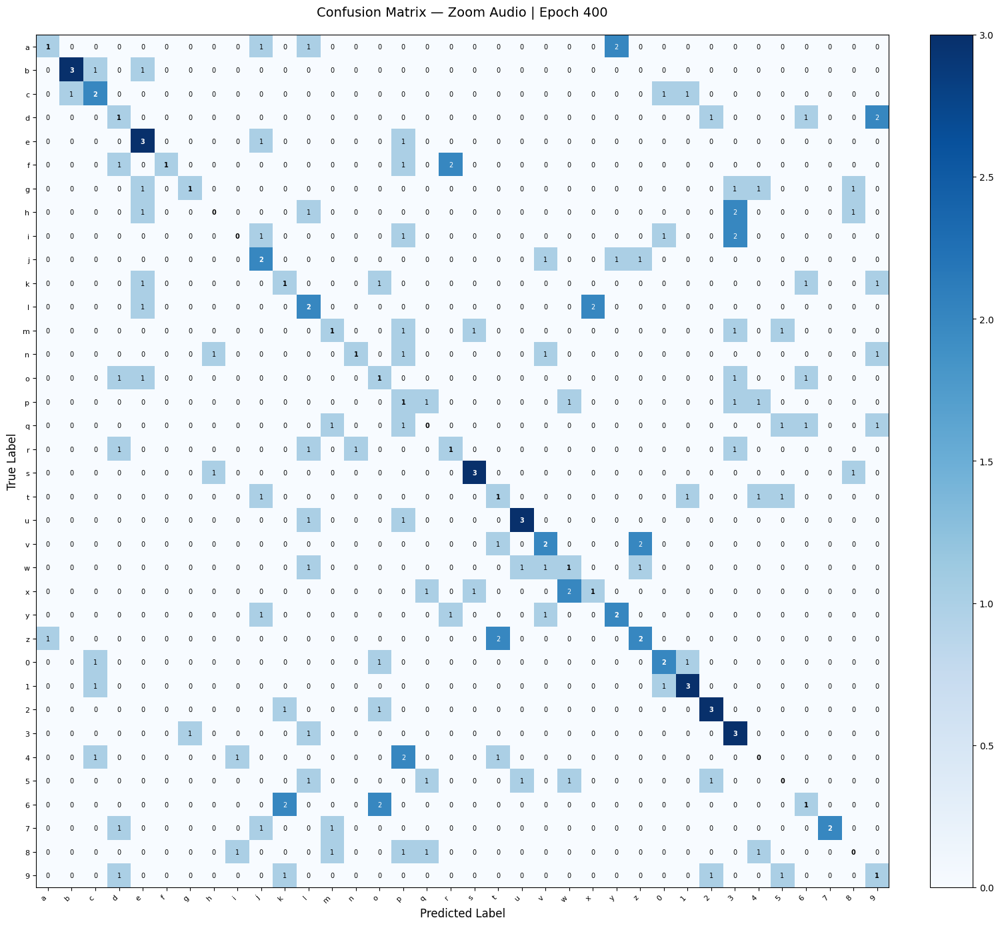

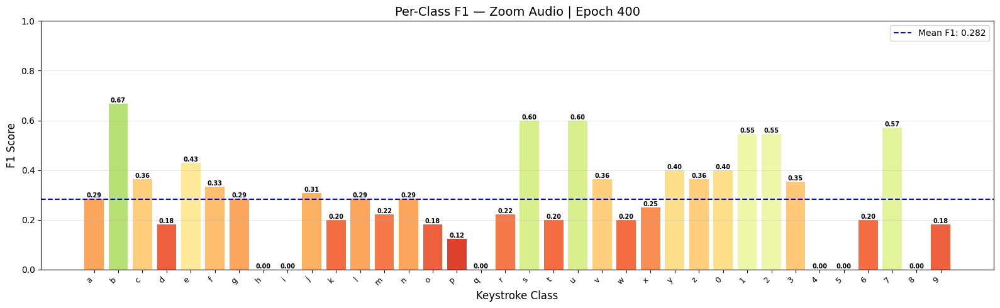

  Time      : 5.23s
  Train     → Loss: 0.0310 | Acc: 0.9944
  Val       → Loss: 4.3190   | Acc: 0.2889
  Weighted  → P: 0.3203 | R: 0.2889 | F1: 0.2820

Epoch 401/1100
------------------------------------------------------------



  Validation Results — Zoom Audio | Epoch 401
  Accuracy  : 0.2778
  Precision : 0.3073  (weighted)
  Recall    : 0.2778  (weighted)
  F1 Score  : 0.2691  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.2000     0.2857          5
  b              0.2857     0.4000     0.3333          5
  c              0.2857     0.4000     0.3333          5
  d              0.2500     0.2000     0.2222          5
  e              0.2222     0.4000     0.2857          5
  f              0.5000     0.2000     0.2857          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.5000     0.4000     0.4444          5
  j              0.4000     0.4000     0.4000          5
  k              0.0000     0.0000     0.0000          5
  l              0.1250     0.2000     0.1538          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 402
  Accuracy  : 0.3111
  Precision : 0.3096  (weighted)
  Recall    : 0.3111  (weighted)
  F1 Score  : 0.2969  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              0.6000     0.6000     0.6000          5
  c              0.2857     0.4000     0.3333          5
  d              0.0000     0.0000     0.0000          5
  e              0.1429     0.2000     0.1667          5
  f              0.2222     0.4000     0.2857          5
  g              0.5000     0.2000     0.2857          5
  h              0.3333     0.2000     0.2500          5
  i              0.1667     0.2000     0.1818          5
  j              0.2500     0.6000     0.3529          5
  k              0.1667     0.2000     0.1818          5
  l              0.1250     0.2000     0.1538          5
  m              0.0


  Validation Results — Zoom Audio | Epoch 403
  Accuracy  : 0.3056
  Precision : 0.3206  (weighted)
  Recall    : 0.3056  (weighted)
  F1 Score  : 0.2833  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              0.4286     0.6000     0.5000          5
  c              0.2500     0.2000     0.2222          5
  d              0.2500     0.2000     0.2222          5
  e              0.3000     0.6000     0.4000          5
  f              0.5000     0.2000     0.2857          5
  g              0.2000     0.2000     0.2000          5
  h              0.3333     0.2000     0.2500          5
  i              0.2500     0.2000     0.2222          5
  j              0.4000     0.4000     0.4000          5
  k              0.0000     0.0000     0.0000          5
  l              0.0000     0.0000     0.0000          5
  m              0.1


  Validation Results — Zoom Audio | Epoch 404
  Accuracy  : 0.3556
  Precision : 0.3550  (weighted)
  Recall    : 0.3556  (weighted)
  F1 Score  : 0.3334  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.5000     0.4000     0.4444          5
  c              0.4286     0.6000     0.5000          5
  d              0.3333     0.4000     0.3636          5
  e              0.2727     0.6000     0.3750          5
  f              0.0000     0.0000     0.0000          5
  g              0.5000     0.2000     0.2857          5
  h              0.0000     0.0000     0.0000          5
  i              0.3333     0.2000     0.2500          5
  j              0.6000     0.6000     0.6000          5
  k              0.2222     0.4000     0.2857          5
  l              0.2000     0.2000     0.2000          5
  m              0.3

...


  Validation Results — Zoom Audio | Epoch 496
  Accuracy  : 0.3000
  Precision : 0.3102  (weighted)
  Recall    : 0.3000  (weighted)
  F1 Score  : 0.2802  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.3000     0.6000     0.4000          5
  c              0.1429     0.2000     0.1667          5
  d              0.0000     0.0000     0.0000          5
  e              0.3333     0.4000     0.3636          5
  f              0.3333     0.6000     0.4286          5
  g              0.2000     0.2000     0.2000          5
  h              0.0000     0.0000     0.0000          5
  i              0.2857     0.4000     0.3333          5
  j              0.3333     0.4000     0.3636          5
  k              0.1250     0.2000     0.1538          5
  l              0.2500     0.2000     0.2222          5
  m              0.1


  Validation Results — Zoom Audio | Epoch 497
  Accuracy  : 0.2944
  Precision : 0.3035  (weighted)
  Recall    : 0.2944  (weighted)
  F1 Score  : 0.2727  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              0.3333     0.6000     0.4286          5
  c              0.2222     0.4000     0.2857          5
  d              0.2000     0.4000     0.2667          5
  e              0.3750     0.6000     0.4615          5
  f              0.1250     0.2000     0.1538          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.4000     0.4000     0.4000          5
  j              0.3333     0.4000     0.3636          5
  k              0.0000     0.0000     0.0000          5
  l              0.2500     0.4000     0.3077          5
  m              0.0


  Validation Results — Zoom Audio | Epoch 498
  Accuracy  : 0.3389
  Precision : 0.3761  (weighted)
  Recall    : 0.3389  (weighted)
  F1 Score  : 0.3265  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              1.0000     0.2000     0.3333          5
  b              0.6667     0.4000     0.5000          5
  c              0.3000     0.6000     0.4000          5
  d              0.3333     0.2000     0.2500          5
  e              0.3333     0.6000     0.4286          5
  f              0.5000     0.2000     0.2857          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.5000     0.4000     0.4444          5
  j              0.3333     0.6000     0.4286          5
  k              0.0909     0.2000     0.1250          5
  l              0.1111     0.2000     0.1429          5
  m              0.5


  Validation Results — Zoom Audio | Epoch 499
  Accuracy  : 0.3556
  Precision : 0.3638  (weighted)
  Recall    : 0.3556  (weighted)
  F1 Score  : 0.3368  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.2000     0.2857          5
  b              0.4444     0.8000     0.5714          5
  c              0.3750     0.6000     0.4615          5
  d              0.3333     0.2000     0.2500          5
  e              0.2222     0.4000     0.2857          5
  f              0.7500     0.6000     0.6667          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.3333     0.6000     0.4286          5
  j              0.4286     0.6000     0.5000          5
  k              0.1667     0.2000     0.1818          5
  l              0.1111     0.2000     0.1429          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 500
  Accuracy  : 0.2889
  Precision : 0.3442  (weighted)
  Recall    : 0.2889  (weighted)
  F1 Score  : 0.2871  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.5000     0.6000     0.5455          5
  c              0.3000     0.6000     0.4000          5
  d              0.2500     0.4000     0.3077          5
  e              0.2500     0.6000     0.3529          5
  f              0.5000     0.2000     0.2857          5
  g              0.0000     0.0000     0.0000          5
  h              0.1667     0.2000     0.1818          5
  i              0.3333     0.2000     0.2500          5
  j              0.2500     0.4000     0.3077          5
  k              0.0000     0.0000     0.0000          5
  l              0.0000     0.0000     0.0000          5
  m              1.0

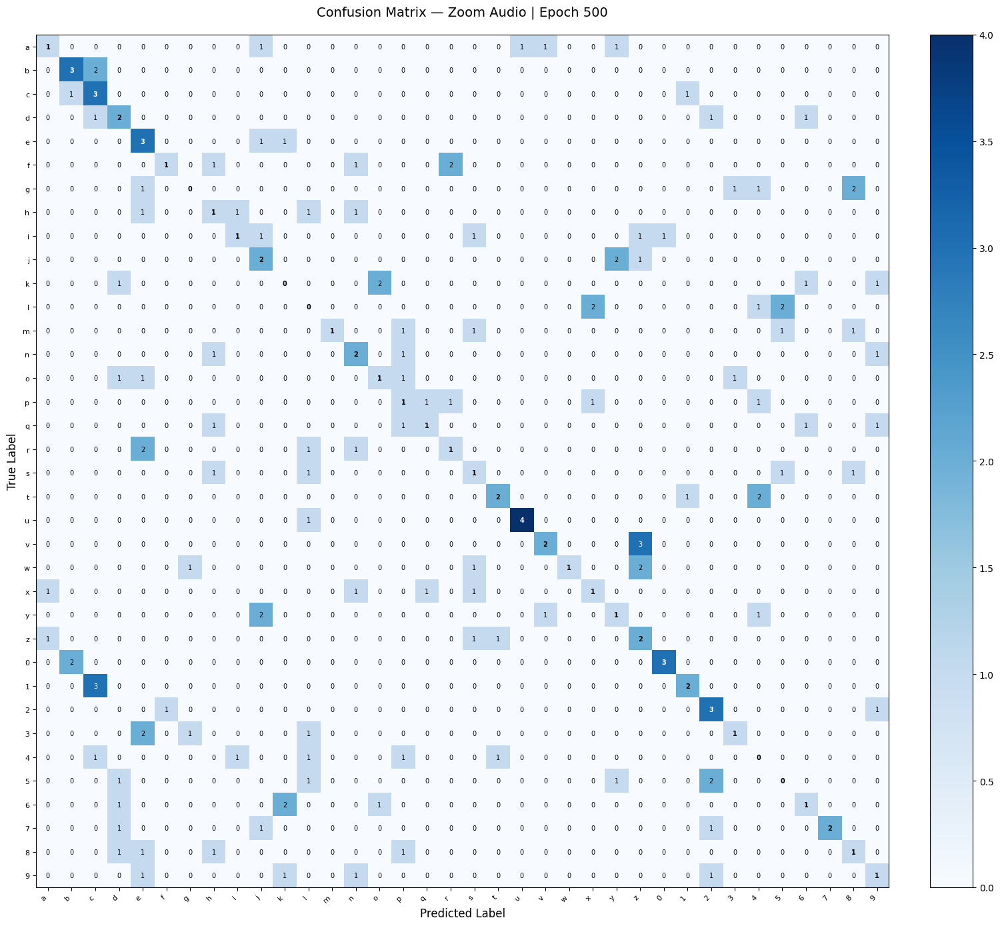

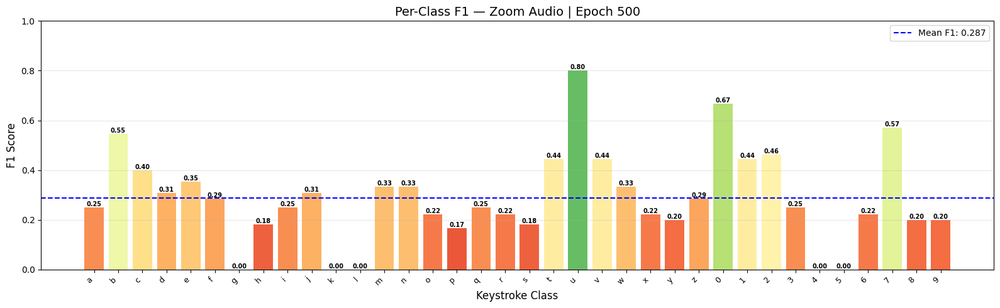

  Time      : 4.96s
  Train     → Loss: 0.0185 | Acc: 0.9931
  Val       → Loss: 4.5393   | Acc: 0.2889
  Weighted  → P: 0.3442 | R: 0.2889 | F1: 0.2871

Epoch 501/1100
------------------------------------------------------------



  Validation Results — Zoom Audio | Epoch 501
  Accuracy  : 0.2833
  Precision : 0.3042  (weighted)
  Recall    : 0.2833  (weighted)
  F1 Score  : 0.2801  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              1.0000     0.6000     0.7500          5
  c              0.3000     0.6000     0.4000          5
  d              0.3333     0.4000     0.3636          5
  e              0.2500     0.2000     0.2222          5
  f              0.2000     0.2000     0.2000          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.5000     0.2000     0.2857          5
  j              0.2857     0.4000     0.3333          5
  k              0.0000     0.0000     0.0000          5
  l              0.2500     0.4000     0.3077          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 502
  Accuracy  : 0.3167
  Precision : 0.3092  (weighted)
  Recall    : 0.3167  (weighted)
  F1 Score  : 0.2990  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.2000     0.2222          5
  b              0.6000     0.6000     0.6000          5
  c              0.3750     0.6000     0.4615          5
  d              0.2857     0.4000     0.3333          5
  e              0.3750     0.6000     0.4615          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.2857     0.4000     0.3333          5
  j              0.1818     0.4000     0.2500          5
  k              0.1429     0.2000     0.1667          5
  l              0.3333     0.4000     0.3636          5
  m              0.2


  Validation Results — Zoom Audio | Epoch 503
  Accuracy  : 0.3111
  Precision : 0.3350  (weighted)
  Recall    : 0.3111  (weighted)
  F1 Score  : 0.3003  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.2500     0.2000     0.2222          5
  c              0.3000     0.6000     0.4000          5
  d              0.2857     0.4000     0.3333          5
  e              0.3333     0.6000     0.4286          5
  f              0.0000     0.0000     0.0000          5
  g              0.5000     0.2000     0.2857          5
  h              0.2000     0.2000     0.2000          5
  i              0.3333     0.2000     0.2500          5
  j              0.2857     0.4000     0.3333          5
  k              0.0000     0.0000     0.0000          5
  l              0.2222     0.4000     0.2857          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 504
  Accuracy  : 0.3111
  Precision : 0.2916  (weighted)
  Recall    : 0.3111  (weighted)
  F1 Score  : 0.2878  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2857     0.4000     0.3333          5
  b              0.5000     0.8000     0.6154          5
  c              0.2000     0.2000     0.2000          5
  d              0.4000     0.4000     0.4000          5
  e              0.2000     0.4000     0.2667          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.3333     0.4000     0.3636          5
  i              0.6667     0.4000     0.5000          5
  j              0.5000     0.2000     0.2857          5
  k              0.3333     0.4000     0.3636          5
  l              0.1667     0.2000     0.1818          5
  m              0.2

...


  Validation Results — Zoom Audio | Epoch 596
  Accuracy  : 0.3444
  Precision : 0.3613  (weighted)
  Recall    : 0.3444  (weighted)
  F1 Score  : 0.3332  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.4000     0.3636          5
  b              0.3333     0.2000     0.2500          5
  c              0.4000     0.8000     0.5333          5
  d              0.6667     0.4000     0.5000          5
  e              0.4000     0.4000     0.4000          5
  f              0.2500     0.2000     0.2222          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.1429     0.2000     0.1667          5
  j              0.2857     0.4000     0.3333          5
  k              0.1667     0.2000     0.1818          5
  l              0.2222     0.4000     0.2857          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 597
  Accuracy  : 0.3111
  Precision : 0.3032  (weighted)
  Recall    : 0.3111  (weighted)
  F1 Score  : 0.2944  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.3750     0.6000     0.4615          5
  c              0.5000     0.4000     0.4444          5
  d              0.5000     0.6000     0.5455          5
  e              0.5000     0.6000     0.5455          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.3333     0.2000     0.2500          5
  i              0.1250     0.2000     0.1538          5
  j              0.2500     0.4000     0.3077          5
  k              0.0909     0.2000     0.1250          5
  l              0.1000     0.2000     0.1333          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 598
  Accuracy  : 0.3556
  Precision : 0.3682  (weighted)
  Recall    : 0.3556  (weighted)
  F1 Score  : 0.3316  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2857     0.4000     0.3333          5
  b              0.4286     0.6000     0.5000          5
  c              0.5000     0.6000     0.5455          5
  d              0.3000     0.6000     0.4000          5
  e              0.3750     0.6000     0.4615          5
  f              0.2500     0.2000     0.2222          5
  g              0.0000     0.0000     0.0000          5
  h              0.2000     0.2000     0.2000          5
  i              0.2500     0.4000     0.3077          5
  j              0.5000     0.2000     0.2857          5
  k              0.1667     0.4000     0.2353          5
  l              0.3000     0.6000     0.4000          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 599
  Accuracy  : 0.2944
  Precision : 0.3021  (weighted)
  Recall    : 0.2944  (weighted)
  F1 Score  : 0.2785  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2857     0.4000     0.3333          5
  b              0.3333     0.4000     0.3636          5
  c              0.3000     0.6000     0.4000          5
  d              0.3333     0.4000     0.3636          5
  e              0.4286     0.6000     0.5000          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.2500     0.2000     0.2222          5
  i              0.1667     0.2000     0.1818          5
  j              0.2000     0.2000     0.2000          5
  k              0.1000     0.2000     0.1333          5
  l              0.2000     0.2000     0.2000          5
  m              0.2


  Validation Results — Zoom Audio | Epoch 600
  Accuracy  : 0.3056
  Precision : 0.2884  (weighted)
  Recall    : 0.3056  (weighted)
  F1 Score  : 0.2842  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.2000     0.2222          5
  b              0.2857     0.4000     0.3333          5
  c              0.3333     0.4000     0.3636          5
  d              0.2000     0.2000     0.2000          5
  e              0.2500     0.6000     0.3529          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.3333     0.2000     0.2500          5
  i              0.2500     0.2000     0.2222          5
  j              0.2857     0.4000     0.3333          5
  k              0.0000     0.0000     0.0000          5
  l              0.2500     0.2000     0.2222          5
  m              0.2

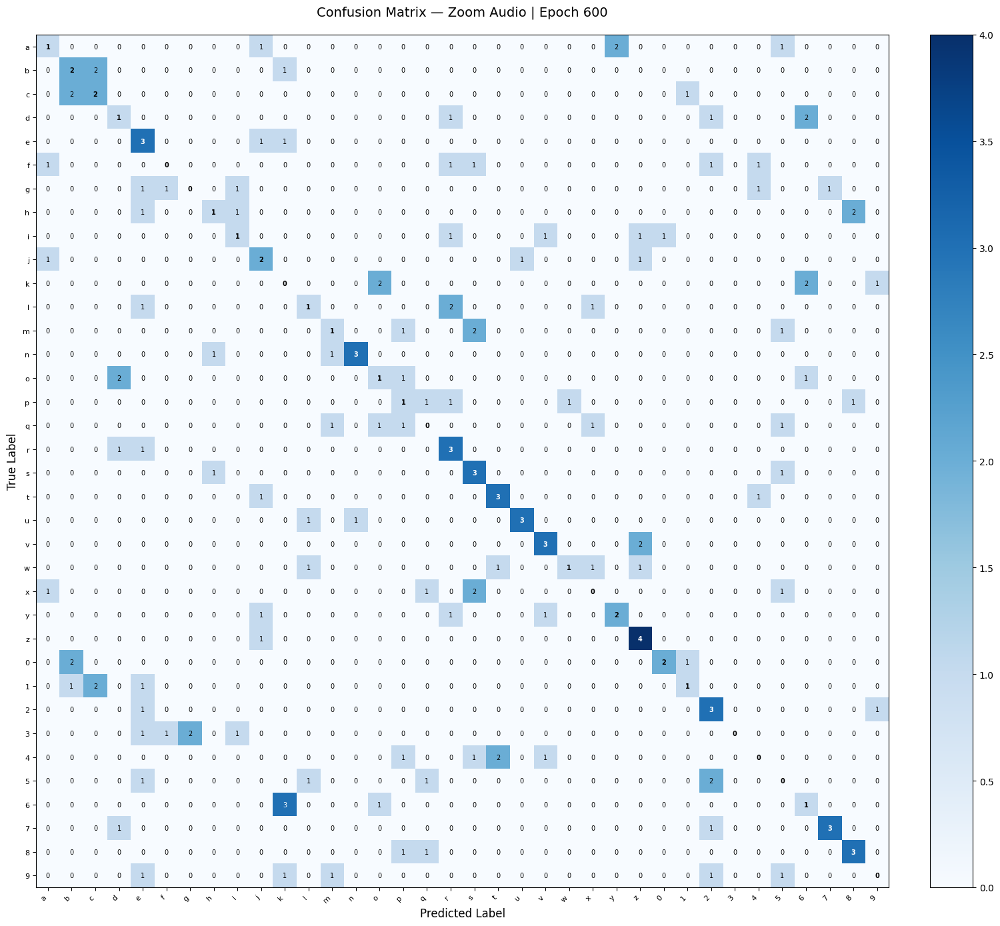

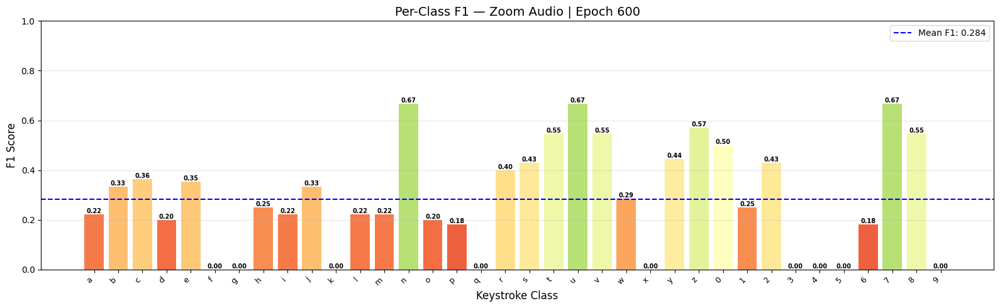

  Time      : 4.50s
  Train     → Loss: 0.0267 | Acc: 0.9917
  Val       → Loss: 4.8015   | Acc: 0.3056
  Weighted  → P: 0.2884 | R: 0.3056 | F1: 0.2842

Epoch 601/1100
------------------------------------------------------------



  Validation Results — Zoom Audio | Epoch 601
  Accuracy  : 0.3222
  Precision : 0.3485  (weighted)
  Recall    : 0.3222  (weighted)
  F1 Score  : 0.3056  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.1667     0.2000     0.1818          5
  b              0.4000     0.8000     0.5333          5
  c              0.6667     0.8000     0.7273          5
  d              0.3750     0.6000     0.4615          5
  e              0.2727     0.6000     0.3750          5
  f              0.2500     0.2000     0.2222          5
  g              0.2500     0.2000     0.2222          5
  h              0.2000     0.2000     0.2000          5
  i              0.3333     0.2000     0.2500          5
  j              0.2222     0.4000     0.2857          5
  k              0.1250     0.2000     0.1538          5
  l              0.1667     0.2000     0.1818          5
  m              0.1


  Validation Results — Zoom Audio | Epoch 602
  Accuracy  : 0.3000
  Precision : 0.2938  (weighted)
  Recall    : 0.3000  (weighted)
  F1 Score  : 0.2766  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              0.3636     0.8000     0.5000          5
  c              0.2000     0.2000     0.2000          5
  d              0.5000     0.6000     0.5455          5
  e              0.3333     0.6000     0.4286          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.4000     0.4000     0.4000          5
  j              0.2500     0.2000     0.2222          5
  k              0.2222     0.4000     0.2857          5
  l              0.1250     0.2000     0.1538          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 603
  Accuracy  : 0.3111
  Precision : 0.3310  (weighted)
  Recall    : 0.3111  (weighted)
  F1 Score  : 0.2946  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              1.0000     0.2000     0.3333          5
  b              0.2500     0.2000     0.2222          5
  c              0.3333     0.6000     0.4286          5
  d              0.3333     0.6000     0.4286          5
  e              0.2500     0.6000     0.3529          5
  f              0.2500     0.2000     0.2222          5
  g              0.0000     0.0000     0.0000          5
  h              0.3333     0.2000     0.2500          5
  i              0.0000     0.0000     0.0000          5
  j              0.2857     0.4000     0.3333          5
  k              0.2222     0.4000     0.2857          5
  l              0.2000     0.4000     0.2667          5
  m              0.1


  Validation Results — Zoom Audio | Epoch 604
  Accuracy  : 0.3222
  Precision : 0.3506  (weighted)
  Recall    : 0.3222  (weighted)
  F1 Score  : 0.3005  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.2000     0.2222          5
  b              0.3333     0.8000     0.4706          5
  c              0.4000     0.4000     0.4000          5
  d              0.2727     0.6000     0.3750          5
  e              0.3750     0.6000     0.4615          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.3333     0.2000     0.2500          5
  j              0.3000     0.6000     0.4000          5
  k              0.1250     0.2000     0.1538          5
  l              0.2000     0.2000     0.2000          5
  m              0.3

...


  Validation Results — Zoom Audio | Epoch 696
  Accuracy  : 0.2944
  Precision : 0.3032  (weighted)
  Recall    : 0.2944  (weighted)
  F1 Score  : 0.2827  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.1667     0.2000     0.1818          5
  b              0.6667     0.4000     0.5000          5
  c              0.4286     0.6000     0.5000          5
  d              0.2857     0.4000     0.3333          5
  e              0.2857     0.4000     0.3333          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.2857     0.4000     0.3333          5
  i              0.4000     0.4000     0.4000          5
  j              0.1667     0.2000     0.1818          5
  k              0.0769     0.2000     0.1111          5
  l              0.2000     0.2000     0.2000          5
  m              0.2


  Validation Results — Zoom Audio | Epoch 697
  Accuracy  : 0.2833
  Precision : 0.2866  (weighted)
  Recall    : 0.2833  (weighted)
  F1 Score  : 0.2697  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.2000     0.2857          5
  b              0.5000     0.2000     0.2857          5
  c              0.3750     0.6000     0.4615          5
  d              0.4000     0.4000     0.4000          5
  e              0.2500     0.4000     0.3077          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.5000     0.2000     0.2857          5
  i              0.2857     0.4000     0.3333          5
  j              0.2857     0.4000     0.3333          5
  k              0.0833     0.2000     0.1176          5
  l              0.2500     0.2000     0.2222          5
  m              0.2


  Validation Results — Zoom Audio | Epoch 698
  Accuracy  : 0.3000
  Precision : 0.2891  (weighted)
  Recall    : 0.3000  (weighted)
  F1 Score  : 0.2737  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              0.2500     0.2000     0.2222          5
  c              0.4000     0.8000     0.5333          5
  d              0.2857     0.4000     0.3333          5
  e              0.3333     0.6000     0.4286          5
  f              0.0000     0.0000     0.0000          5
  g              0.3333     0.2000     0.2500          5
  h              0.3333     0.4000     0.3636          5
  i              0.2500     0.4000     0.3077          5
  j              0.0000     0.0000     0.0000          5
  k              0.1667     0.2000     0.1818          5
  l              0.1250     0.2000     0.1538          5
  m              0.0


  Validation Results — Zoom Audio | Epoch 699
  Accuracy  : 0.3056
  Precision : 0.3298  (weighted)
  Recall    : 0.3056  (weighted)
  F1 Score  : 0.2935  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.2000     0.2222          5
  b              0.5000     0.2000     0.2857          5
  c              0.3000     0.6000     0.4000          5
  d              0.2500     0.4000     0.3077          5
  e              0.3636     0.8000     0.5000          5
  f              0.0000     0.0000     0.0000          5
  g              0.5000     0.2000     0.2857          5
  h              0.2000     0.2000     0.2000          5
  i              0.1667     0.2000     0.1818          5
  j              0.2222     0.4000     0.2857          5
  k              0.2000     0.2000     0.2000          5
  l              0.2000     0.4000     0.2667          5
  m              0.0


  Validation Results — Zoom Audio | Epoch 700
  Accuracy  : 0.2778
  Precision : 0.2908  (weighted)
  Recall    : 0.2778  (weighted)
  F1 Score  : 0.2672  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.3333     0.2000     0.2500          5
  c              0.3000     0.6000     0.4000          5
  d              0.2857     0.4000     0.3333          5
  e              0.3000     0.6000     0.4000          5
  f              0.2500     0.2000     0.2222          5
  g              0.3333     0.2000     0.2500          5
  h              0.5000     0.2000     0.2857          5
  i              0.0000     0.0000     0.0000          5
  j              0.2222     0.4000     0.2857          5
  k              0.3333     0.2000     0.2500          5
  l              0.0000     0.0000     0.0000          5
  m              0.4

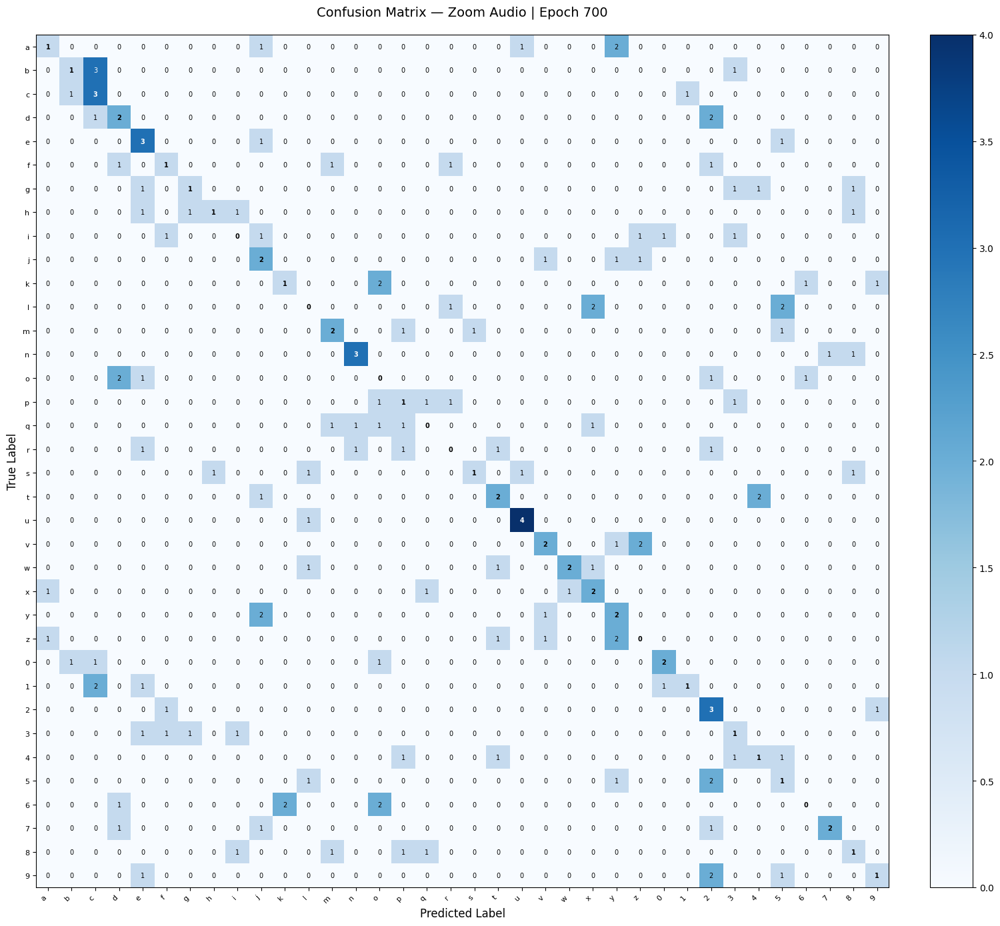

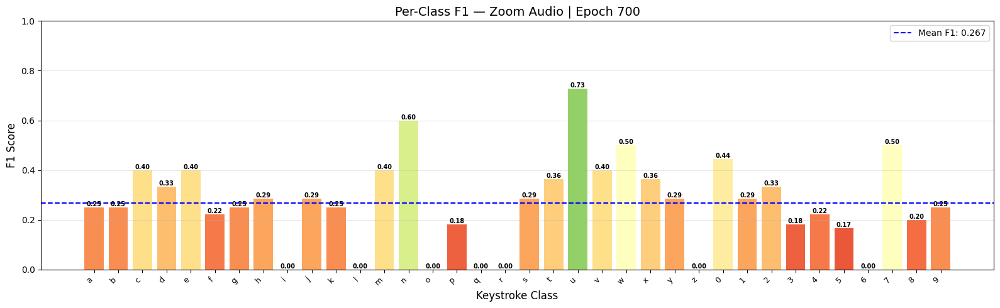

  Time      : 2.38s
  Train     → Loss: 0.0009 | Acc: 1.0000
  Val       → Loss: 5.1707   | Acc: 0.2778
  Weighted  → P: 0.2908 | R: 0.2778 | F1: 0.2672

Epoch 701/1100
------------------------------------------------------------



  Validation Results — Zoom Audio | Epoch 701
  Accuracy  : 0.2944
  Precision : 0.3090  (weighted)
  Recall    : 0.2944  (weighted)
  F1 Score  : 0.2842  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.5000     0.4000     0.4444          5
  c              0.4286     0.6000     0.5000          5
  d              0.2222     0.4000     0.2857          5
  e              0.3636     0.8000     0.5000          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.2000     0.2000     0.2000          5
  i              0.2500     0.2000     0.2222          5
  j              0.2000     0.4000     0.2667          5
  k              0.2500     0.2000     0.2222          5
  l              0.0000     0.0000     0.0000          5
  m              0.2


  Validation Results — Zoom Audio | Epoch 702
  Accuracy  : 0.3000
  Precision : 0.3324  (weighted)
  Recall    : 0.3000  (weighted)
  F1 Score  : 0.2896  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.6667     0.4000     0.5000          5
  c              0.2500     0.4000     0.3077          5
  d              0.2857     0.4000     0.3333          5
  e              0.3636     0.8000     0.5000          5
  f              0.4000     0.4000     0.4000          5
  g              0.5000     0.2000     0.2857          5
  h              0.2000     0.2000     0.2000          5
  i              0.0000     0.0000     0.0000          5
  j              0.2000     0.4000     0.2667          5
  k              0.2000     0.2000     0.2000          5
  l              0.0000     0.0000     0.0000          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 703
  Accuracy  : 0.2778
  Precision : 0.2721  (weighted)
  Recall    : 0.2778  (weighted)
  F1 Score  : 0.2593  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.1429     0.2000     0.1667          5
  b              0.4286     0.6000     0.5000          5
  c              0.2500     0.2000     0.2222          5
  d              0.2000     0.2000     0.2000          5
  e              0.4286     0.6000     0.5000          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.0000     0.0000     0.0000          5
  j              0.2000     0.2000     0.2000          5
  k              0.1250     0.2000     0.1538          5
  l              0.0000     0.0000     0.0000          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 704
  Accuracy  : 0.2722
  Precision : 0.2926  (weighted)
  Recall    : 0.2722  (weighted)
  F1 Score  : 0.2572  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              0.4286     0.6000     0.5000          5
  c              0.2500     0.2000     0.2222          5
  d              0.2857     0.4000     0.3333          5
  e              0.3000     0.6000     0.4000          5
  f              0.2500     0.2000     0.2222          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.0000     0.0000     0.0000          5
  j              0.2500     0.2000     0.2222          5
  k              0.1000     0.2000     0.1333          5
  l              0.1667     0.2000     0.1818          5
  m              0.3

...


  Validation Results — Zoom Audio | Epoch 796
  Accuracy  : 0.2833
  Precision : 0.2953  (weighted)
  Recall    : 0.2833  (weighted)
  F1 Score  : 0.2713  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.2000     0.2222          5
  b              0.5000     0.4000     0.4444          5
  c              0.3750     0.6000     0.4615          5
  d              0.2308     0.6000     0.3333          5
  e              0.2000     0.4000     0.2667          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.2000     0.2000     0.2000          5
  j              0.0000     0.0000     0.0000          5
  k              0.1111     0.2000     0.1429          5
  l              0.6000     0.6000     0.6000          5
  m              0.4


  Validation Results — Zoom Audio | Epoch 797
  Accuracy  : 0.3667
  Precision : 0.3931  (weighted)
  Recall    : 0.3667  (weighted)
  F1 Score  : 0.3576  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.2000     0.2222          5
  b              1.0000     0.4000     0.5714          5
  c              0.4286     0.6000     0.5000          5
  d              0.2857     0.4000     0.3333          5
  e              0.3750     0.6000     0.4615          5
  f              1.0000     0.2000     0.3333          5
  g              0.3333     0.2000     0.2500          5
  h              0.0000     0.0000     0.0000          5
  i              0.2500     0.2000     0.2222          5
  j              0.2500     0.2000     0.2222          5
  k              0.2000     0.2000     0.2000          5
  l              0.2857     0.4000     0.3333          5
  m              0.4


  Validation Results — Zoom Audio | Epoch 798
  Accuracy  : 0.3111
  Precision : 0.3281  (weighted)
  Recall    : 0.3111  (weighted)
  F1 Score  : 0.2955  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.4000     0.4444          5
  b              1.0000     0.4000     0.5714          5
  c              0.3333     0.6000     0.4286          5
  d              0.6667     0.4000     0.5000          5
  e              0.1667     0.2000     0.1818          5
  f              0.5000     0.2000     0.2857          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.3750     0.6000     0.4615          5
  j              0.0000     0.0000     0.0000          5
  k              0.1111     0.2000     0.1429          5
  l              0.4000     0.4000     0.4000          5
  m              0.4


  Validation Results — Zoom Audio | Epoch 799
  Accuracy  : 0.3333
  Precision : 0.3582  (weighted)
  Recall    : 0.3333  (weighted)
  F1 Score  : 0.3227  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.6667     0.4000     0.5000          5
  b              0.6667     0.4000     0.5000          5
  c              0.3333     0.6000     0.4286          5
  d              0.4000     0.4000     0.4000          5
  e              0.2500     0.4000     0.3077          5
  f              0.1667     0.2000     0.1818          5
  g              0.2500     0.2000     0.2222          5
  h              0.0000     0.0000     0.0000          5
  i              0.2000     0.2000     0.2000          5
  j              0.4000     0.4000     0.4000          5
  k              0.2857     0.4000     0.3333          5
  l              0.1667     0.2000     0.1818          5
  m              0.2


  Validation Results — Zoom Audio | Epoch 800
  Accuracy  : 0.3000
  Precision : 0.3315  (weighted)
  Recall    : 0.3000  (weighted)
  F1 Score  : 0.2950  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.1667     0.2000     0.1818          5
  b              0.6667     0.4000     0.5000          5
  c              0.2000     0.4000     0.2667          5
  d              0.3000     0.6000     0.4000          5
  e              0.2222     0.4000     0.2857          5
  f              0.3333     0.4000     0.3636          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.1429     0.2000     0.1667          5
  j              0.5000     0.4000     0.4444          5
  k              0.0833     0.2000     0.1176          5
  l              0.3333     0.4000     0.3636          5
  m              0.3

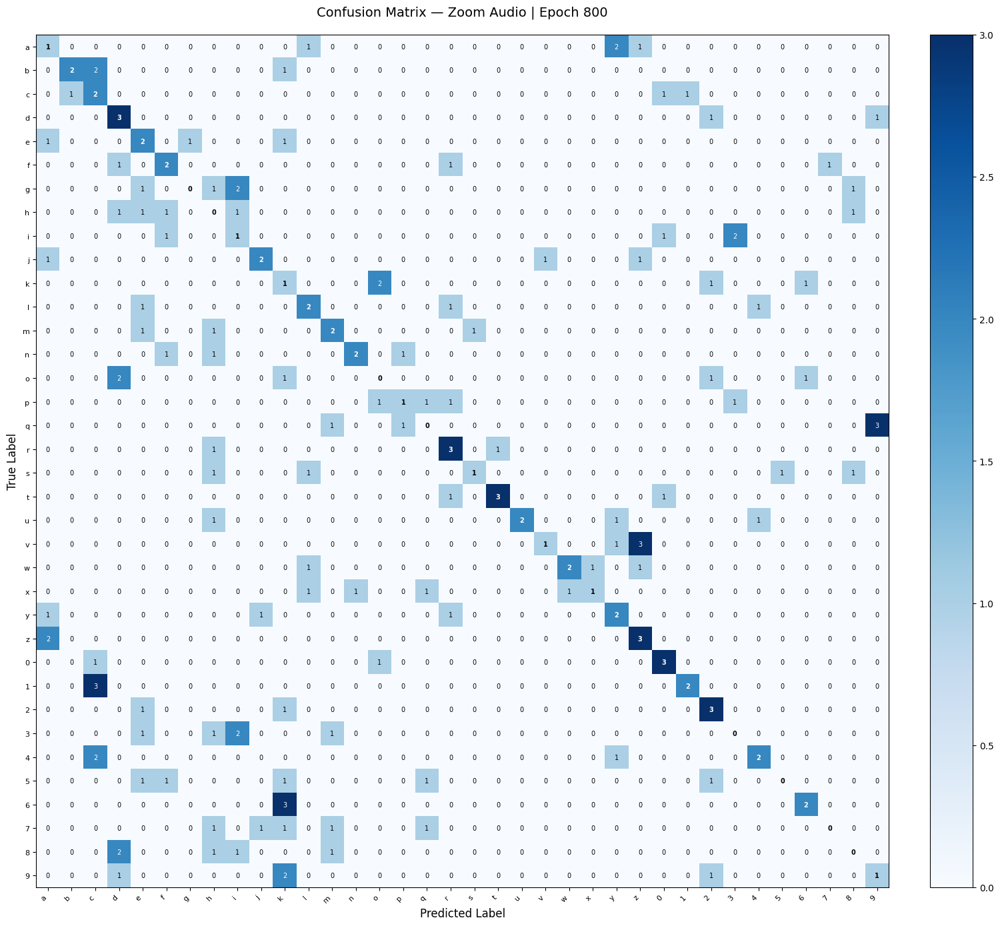

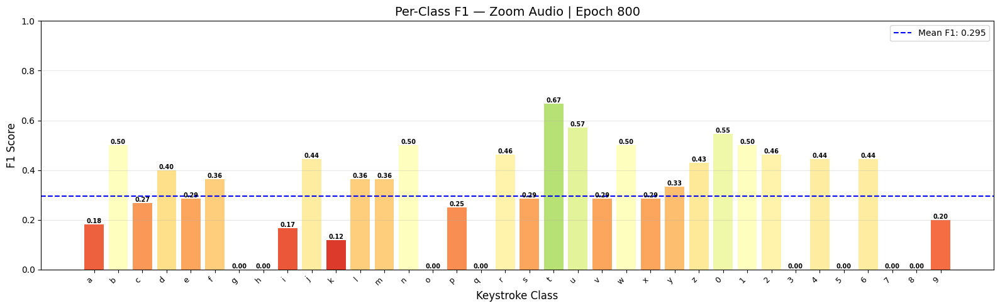

  Time      : 4.24s
  Train     → Loss: 0.0224 | Acc: 0.9931
  Val       → Loss: 5.4680   | Acc: 0.3000
  Weighted  → P: 0.3315 | R: 0.3000 | F1: 0.2950

Epoch 801/1100
------------------------------------------------------------



  Validation Results — Zoom Audio | Epoch 801
  Accuracy  : 0.3333
  Precision : 0.3638  (weighted)
  Recall    : 0.3333  (weighted)
  F1 Score  : 0.3165  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.6000     0.6000     0.6000          5
  c              0.4000     0.4000     0.4000          5
  d              0.6000     0.6000     0.6000          5
  e              0.3333     0.6000     0.4286          5
  f              0.3333     0.2000     0.2500          5
  g              1.0000     0.2000     0.3333          5
  h              0.0000     0.0000     0.0000          5
  i              0.5000     0.2000     0.2857          5
  j              0.0000     0.0000     0.0000          5
  k              0.1111     0.2000     0.1429          5
  l              0.1667     0.2000     0.1818          5
  m              0.2


  Validation Results — Zoom Audio | Epoch 802
  Accuracy  : 0.3167
  Precision : 0.3379  (weighted)
  Recall    : 0.3167  (weighted)
  F1 Score  : 0.2970  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.5000     0.8000     0.6154          5
  c              0.2857     0.4000     0.3333          5
  d              0.3333     0.4000     0.3636          5
  e              0.2143     0.6000     0.3158          5
  f              0.5000     0.2000     0.2857          5
  g              0.3333     0.2000     0.2500          5
  h              0.0000     0.0000     0.0000          5
  i              0.3333     0.4000     0.3636          5
  j              0.2000     0.2000     0.2000          5
  k              0.0000     0.0000     0.0000          5
  l              0.3333     0.2000     0.2500          5
  m              0.1


  Validation Results — Zoom Audio | Epoch 803
  Accuracy  : 0.3333
  Precision : 0.3131  (weighted)
  Recall    : 0.3333  (weighted)
  F1 Score  : 0.3094  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.2000     0.2222          5
  b              0.4444     0.8000     0.5714          5
  c              0.3333     0.4000     0.3636          5
  d              0.4000     0.4000     0.4000          5
  e              0.2308     0.6000     0.3333          5
  f              0.5000     0.2000     0.2857          5
  g              0.3333     0.2000     0.2500          5
  h              0.0000     0.0000     0.0000          5
  i              0.2500     0.4000     0.3077          5
  j              0.1667     0.2000     0.1818          5
  k              0.0000     0.0000     0.0000          5
  l              0.2500     0.2000     0.2222          5
  m              0.1


  Validation Results — Zoom Audio | Epoch 804
  Accuracy  : 0.2889
  Precision : 0.3034  (weighted)
  Recall    : 0.2889  (weighted)
  F1 Score  : 0.2683  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.4000     0.3077          5
  b              0.4000     0.8000     0.5333          5
  c              0.3333     0.4000     0.3636          5
  d              0.2857     0.4000     0.3333          5
  e              0.2308     0.6000     0.3333          5
  f              0.0000     0.0000     0.0000          5
  g              1.0000     0.2000     0.3333          5
  h              0.3333     0.2000     0.2500          5
  i              0.2000     0.4000     0.2667          5
  j              0.0000     0.0000     0.0000          5
  k              0.0000     0.0000     0.0000          5
  l              0.3333     0.4000     0.3636          5
  m              0.2

...


  Validation Results — Zoom Audio | Epoch 896
  Accuracy  : 0.3278
  Precision : 0.3517  (weighted)
  Recall    : 0.3278  (weighted)
  F1 Score  : 0.3164  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.2000     0.2857          5
  b              1.0000     0.4000     0.5714          5
  c              0.4286     0.6000     0.5000          5
  d              1.0000     0.2000     0.3333          5
  e              0.2500     0.4000     0.3077          5
  f              0.6667     0.4000     0.5000          5
  g              0.2000     0.2000     0.2000          5
  h              0.0000     0.0000     0.0000          5
  i              0.0000     0.0000     0.0000          5
  j              0.2857     0.4000     0.3333          5
  k              0.2500     0.2000     0.2222          5
  l              0.1250     0.2000     0.1538          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 897
  Accuracy  : 0.3111
  Precision : 0.3264  (weighted)
  Recall    : 0.3111  (weighted)
  F1 Score  : 0.3017  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              1.0000     0.4000     0.5714          5
  c              0.3750     0.6000     0.4615          5
  d              0.2500     0.2000     0.2222          5
  e              0.1818     0.4000     0.2500          5
  f              0.0000     0.0000     0.0000          5
  g              0.1250     0.2000     0.1538          5
  h              0.0000     0.0000     0.0000          5
  i              0.2857     0.4000     0.3333          5
  j              0.3333     0.4000     0.3636          5
  k              0.1429     0.2000     0.1667          5
  l              0.1667     0.2000     0.1818          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 898
  Accuracy  : 0.3333
  Precision : 0.3221  (weighted)
  Recall    : 0.3333  (weighted)
  F1 Score  : 0.3209  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.4000     0.3636          5
  b              0.2857     0.4000     0.3333          5
  c              0.2857     0.4000     0.3333          5
  d              0.4000     0.4000     0.4000          5
  e              0.5000     0.6000     0.5455          5
  f              0.4286     0.6000     0.5000          5
  g              0.0000     0.0000     0.0000          5
  h              0.2857     0.4000     0.3333          5
  i              0.1667     0.2000     0.1818          5
  j              0.2500     0.2000     0.2222          5
  k              0.1667     0.2000     0.1818          5
  l              0.0000     0.0000     0.0000          5
  m              0.1


  Validation Results — Zoom Audio | Epoch 899
  Accuracy  : 0.3667
  Precision : 0.3675  (weighted)
  Recall    : 0.3667  (weighted)
  F1 Score  : 0.3503  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.4000     0.3636          5
  b              0.5000     0.4000     0.4444          5
  c              0.3333     0.6000     0.4286          5
  d              0.6000     0.6000     0.6000          5
  e              0.2857     0.4000     0.3333          5
  f              0.3333     0.4000     0.3636          5
  g              0.0000     0.0000     0.0000          5
  h              0.2857     0.4000     0.3333          5
  i              0.3333     0.2000     0.2500          5
  j              0.4000     0.4000     0.4000          5
  k              0.2000     0.2000     0.2000          5
  l              0.3333     0.2000     0.2500          5
  m              0.2


  Validation Results — Zoom Audio | Epoch 900
  Accuracy  : 0.3056
  Precision : 0.3419  (weighted)
  Recall    : 0.3056  (weighted)
  F1 Score  : 0.2961  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              1.0000     0.2000     0.3333          5
  c              0.3333     0.6000     0.4286          5
  d              0.5000     0.2000     0.2857          5
  e              0.5000     0.4000     0.4444          5
  f              0.2000     0.2000     0.2000          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.0000     0.0000     0.0000          5
  j              0.4000     0.4000     0.4000          5
  k              0.0000     0.0000     0.0000          5
  l              0.5000     0.4000     0.4444          5
  m              0.3

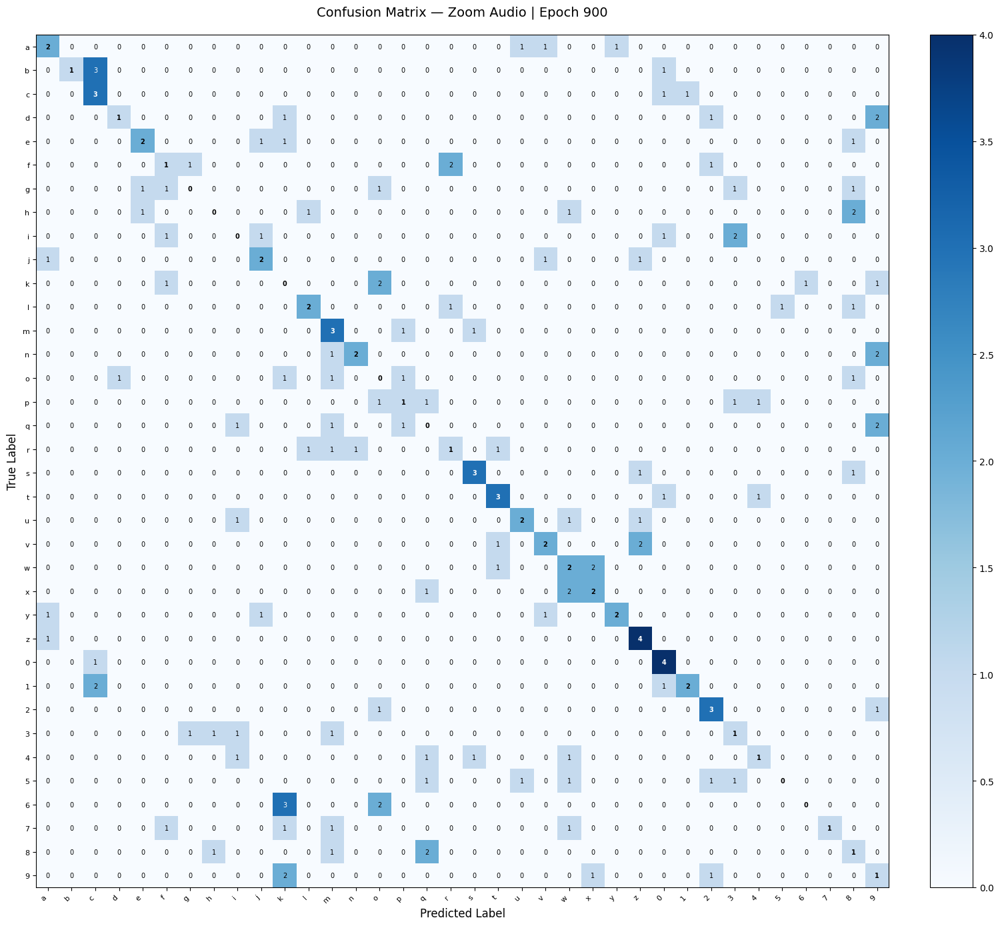

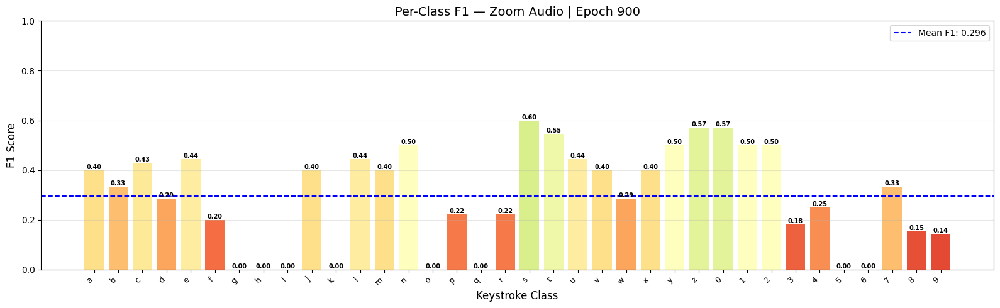

  Time      : 3.01s
  Train     → Loss: 0.0087 | Acc: 0.9946
  Val       → Loss: 5.1480   | Acc: 0.3056
  Weighted  → P: 0.3419 | R: 0.3056 | F1: 0.2961

Epoch 901/1100
------------------------------------------------------------



  Validation Results — Zoom Audio | Epoch 901
  Accuracy  : 0.3444
  Precision : 0.3325  (weighted)
  Recall    : 0.3444  (weighted)
  F1 Score  : 0.3272  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.5000     0.2000     0.2857          5
  c              0.3750     0.6000     0.4615          5
  d              0.4000     0.4000     0.4000          5
  e              0.3333     0.4000     0.3636          5
  f              0.1667     0.2000     0.1818          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.1667     0.2000     0.1818          5
  j              0.3333     0.2000     0.2500          5
  k              0.2500     0.2000     0.2222          5
  l              0.2500     0.4000     0.3077          5
  m              0.4


  Validation Results — Zoom Audio | Epoch 902
  Accuracy  : 0.3667
  Precision : 0.3494  (weighted)
  Recall    : 0.3667  (weighted)
  F1 Score  : 0.3429  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.5000     0.2000     0.2857          5
  c              0.4444     0.8000     0.5714          5
  d              0.6667     0.4000     0.5000          5
  e              0.5000     0.6000     0.5455          5
  f              0.2000     0.2000     0.2000          5
  g              0.0000     0.0000     0.0000          5
  h              0.2500     0.2000     0.2222          5
  i              0.1667     0.2000     0.1818          5
  j              0.2500     0.2000     0.2222          5
  k              0.2000     0.2000     0.2000          5
  l              0.2500     0.4000     0.3077          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 903
  Accuracy  : 0.3389
  Precision : 0.3076  (weighted)
  Recall    : 0.3389  (weighted)
  F1 Score  : 0.3126  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.4000     0.4444          5
  b              0.5000     0.4000     0.4444          5
  c              0.5000     0.8000     0.6154          5
  d              0.5000     0.6000     0.5455          5
  e              0.3333     0.2000     0.2500          5
  f              0.2857     0.4000     0.3333          5
  g              0.0000     0.0000     0.0000          5
  h              0.2000     0.2000     0.2000          5
  i              0.1250     0.2000     0.1538          5
  j              0.2500     0.2000     0.2222          5
  k              0.2000     0.2000     0.2000          5
  l              0.3333     0.4000     0.3636          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 904
  Accuracy  : 0.3333
  Precision : 0.3048  (weighted)
  Recall    : 0.3333  (weighted)
  F1 Score  : 0.3085  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.4000     0.4444          5
  b              0.5000     0.4000     0.4444          5
  c              0.5000     0.8000     0.6154          5
  d              0.5000     0.6000     0.5455          5
  e              0.3333     0.2000     0.2500          5
  f              0.2857     0.4000     0.3333          5
  g              0.0000     0.0000     0.0000          5
  h              0.2000     0.2000     0.2000          5
  i              0.1250     0.2000     0.1538          5
  j              0.2500     0.2000     0.2222          5
  k              0.2000     0.2000     0.2000          5
  l              0.3333     0.4000     0.3636          5
  m              0.2

...


  Validation Results — Zoom Audio | Epoch 996
  Accuracy  : 0.3222
  Precision : 0.3252  (weighted)
  Recall    : 0.3222  (weighted)
  F1 Score  : 0.3061  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.2000     0.2000     0.2000          5
  c              0.3750     0.6000     0.4615          5
  d              0.5000     0.2000     0.2857          5
  e              0.3333     0.6000     0.4286          5
  f              0.6000     0.6000     0.6000          5
  g              0.0000     0.0000     0.0000          5
  h              0.5000     0.2000     0.2857          5
  i              0.1250     0.2000     0.1538          5
  j              0.1667     0.2000     0.1818          5
  k              0.1429     0.4000     0.2105          5
  l              0.4000     0.4000     0.4000          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 997
  Accuracy  : 0.3611
  Precision : 0.3403  (weighted)
  Recall    : 0.3611  (weighted)
  F1 Score  : 0.3354  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.2000     0.2857          5
  b              0.5000     0.2000     0.2857          5
  c              0.4444     0.8000     0.5714          5
  d              0.6667     0.4000     0.5000          5
  e              0.6000     0.6000     0.6000          5
  f              0.3333     0.4000     0.3636          5
  g              0.0000     0.0000     0.0000          5
  h              0.2000     0.2000     0.2000          5
  i              0.0000     0.0000     0.0000          5
  j              0.2857     0.4000     0.3333          5
  k              0.1000     0.2000     0.1333          5
  l              0.2000     0.2000     0.2000          5
  m              0.1


  Validation Results — Zoom Audio | Epoch 998
  Accuracy  : 0.3000
  Precision : 0.2967  (weighted)
  Recall    : 0.3000  (weighted)
  F1 Score  : 0.2899  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              0.4000     0.4000     0.4000          5
  c              0.2500     0.4000     0.3077          5
  d              0.5000     0.4000     0.4444          5
  e              0.6000     0.6000     0.6000          5
  f              0.6667     0.4000     0.5000          5
  g              0.0000     0.0000     0.0000          5
  h              0.2500     0.2000     0.2222          5
  i              0.2500     0.2000     0.2222          5
  j              0.2000     0.2000     0.2000          5
  k              0.0909     0.2000     0.1250          5
  l              0.4000     0.4000     0.4000          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 999
  Accuracy  : 0.3000
  Precision : 0.2858  (weighted)
  Recall    : 0.3000  (weighted)
  F1 Score  : 0.2834  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2500     0.2000     0.2222          5
  b              0.3333     0.4000     0.3636          5
  c              0.2222     0.4000     0.2857          5
  d              0.4000     0.4000     0.4000          5
  e              0.7500     0.6000     0.6667          5
  f              0.6667     0.4000     0.5000          5
  g              0.0000     0.0000     0.0000          5
  h              0.3333     0.4000     0.3636          5
  i              0.2500     0.2000     0.2222          5
  j              0.0000     0.0000     0.0000          5
  k              0.1000     0.2000     0.1333          5
  l              0.3333     0.4000     0.3636          5
  m              0.3


  Validation Results — Zoom Audio | Epoch 1000
  Accuracy  : 0.3444
  Precision : 0.3305  (weighted)
  Recall    : 0.3444  (weighted)
  F1 Score  : 0.3223  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              0.5000     0.6000     0.5455          5
  c              0.3750     0.6000     0.4615          5
  d              0.2857     0.4000     0.3333          5
  e              0.4286     0.6000     0.5000          5
  f              0.3333     0.2000     0.2500          5
  g              0.0000     0.0000     0.0000          5
  h              0.2000     0.2000     0.2000          5
  i              0.2000     0.2000     0.2000          5
  j              0.2000     0.2000     0.2000          5
  k              0.2000     0.4000     0.2667          5
  l              0.5000     0.2000     0.2857          5
  m              0.

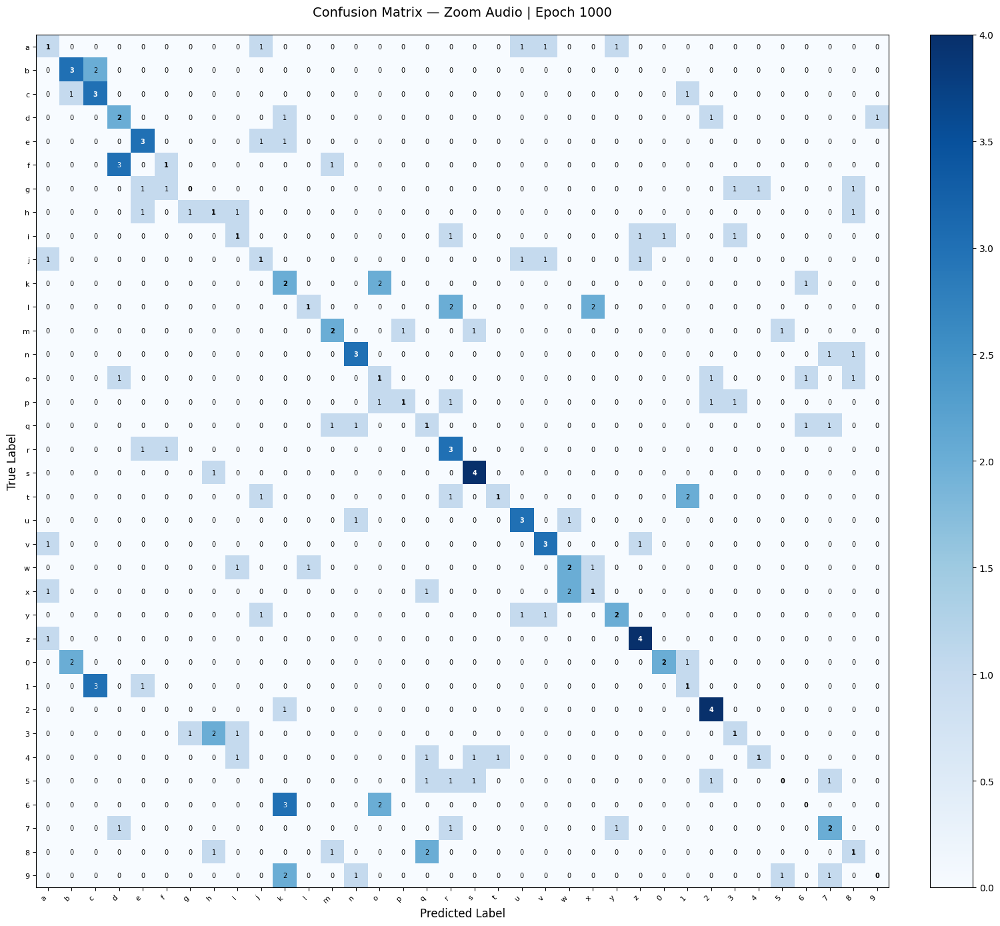

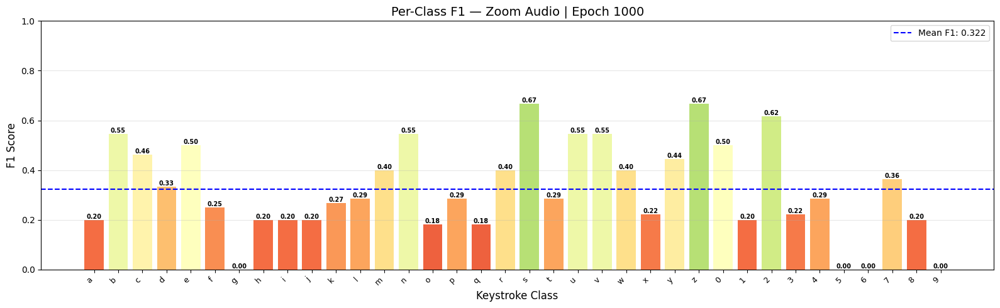

  Time      : 3.18s
  Train     → Loss: 0.0135 | Acc: 0.9914
  Val       → Loss: 5.1964   | Acc: 0.3444
  Weighted  → P: 0.3305 | R: 0.3444 | F1: 0.3223

Epoch 1001/1100
------------------------------------------------------------



  Validation Results — Zoom Audio | Epoch 1001
  Accuracy  : 0.3389
  Precision : 0.3324  (weighted)
  Recall    : 0.3389  (weighted)
  F1 Score  : 0.3231  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.2000     0.2857          5
  b              0.3333     0.4000     0.3636          5
  c              0.2857     0.4000     0.3333          5
  d              0.5000     0.2000     0.2857          5
  e              0.4286     0.6000     0.5000          5
  f              0.5000     0.6000     0.5455          5
  g              0.0000     0.0000     0.0000          5
  h              0.2500     0.2000     0.2222          5
  i              0.1429     0.2000     0.1667          5
  j              0.1667     0.2000     0.1818          5
  k              0.1429     0.2000     0.1667          5
  l              0.5000     0.2000     0.2857          5
  m              0.


  Validation Results — Zoom Audio | Epoch 1002
  Accuracy  : 0.3444
  Precision : 0.3968  (weighted)
  Recall    : 0.3444  (weighted)
  F1 Score  : 0.3389  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.5000     0.2000     0.2857          5
  b              0.4000     0.4000     0.4000          5
  c              0.3750     0.6000     0.4615          5
  d              0.6667     0.4000     0.5000          5
  e              0.2727     0.6000     0.3750          5
  f              0.6667     0.4000     0.5000          5
  g              1.0000     0.2000     0.3333          5
  h              0.1667     0.2000     0.1818          5
  i              0.3333     0.2000     0.2500          5
  j              0.2000     0.2000     0.2000          5
  k              0.1667     0.2000     0.1818          5
  l              0.2000     0.6000     0.3000          5
  m              0.


  Validation Results — Zoom Audio | Epoch 1003
  Accuracy  : 0.3389
  Precision : 0.3451  (weighted)
  Recall    : 0.3389  (weighted)
  F1 Score  : 0.3244  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.2000     0.2000     0.2000          5
  b              0.2500     0.2000     0.2222          5
  c              0.2857     0.4000     0.3333          5
  d              0.7500     0.6000     0.6667          5
  e              0.3333     0.6000     0.4286          5
  f              0.6667     0.4000     0.5000          5
  g              0.5000     0.2000     0.2857          5
  h              0.1429     0.2000     0.1667          5
  i              0.2500     0.2000     0.2222          5
  j              0.2000     0.2000     0.2000          5
  k              0.1250     0.2000     0.1538          5
  l              0.2500     0.8000     0.3810          5
  m              0.


  Validation Results — Zoom Audio | Epoch 1004
  Accuracy  : 0.3500
  Precision : 0.3477  (weighted)
  Recall    : 0.3500  (weighted)
  F1 Score  : 0.3333  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.5000     0.2000     0.2857          5
  c              0.3750     0.6000     0.4615          5
  d              0.7500     0.6000     0.6667          5
  e              0.2500     0.6000     0.3529          5
  f              0.5000     0.4000     0.4444          5
  g              0.0000     0.0000     0.0000          5
  h              0.0000     0.0000     0.0000          5
  i              0.2500     0.2000     0.2222          5
  j              0.1667     0.2000     0.1818          5
  k              0.1250     0.2000     0.1538          5
  l              0.4000     0.8000     0.5333          5
  m              0.

...


  Validation Results — Zoom Audio | Epoch 1096
  Accuracy  : 0.3056
  Precision : 0.3059  (weighted)
  Recall    : 0.3056  (weighted)
  F1 Score  : 0.2943  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.3000     0.6000     0.4000          5
  c              0.5000     0.4000     0.4444          5
  d              0.1429     0.2000     0.1667          5
  e              0.3000     0.6000     0.4000          5
  f              0.2000     0.2000     0.2000          5
  g              0.0000     0.0000     0.0000          5
  h              0.5000     0.2000     0.2857          5
  i              0.4000     0.4000     0.4000          5
  j              0.0000     0.0000     0.0000          5
  k              0.1111     0.2000     0.1429          5
  l              0.2000     0.2000     0.2000          5
  m              0.


  Validation Results — Zoom Audio | Epoch 1097
  Accuracy  : 0.3389
  Precision : 0.3407  (weighted)
  Recall    : 0.3389  (weighted)
  F1 Score  : 0.3210  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.3750     0.6000     0.4615          5
  c              0.5000     0.4000     0.4444          5
  d              0.4000     0.4000     0.4000          5
  e              0.3750     0.6000     0.4615          5
  f              0.3333     0.2000     0.2500          5
  g              0.0000     0.0000     0.0000          5
  h              0.5000     0.2000     0.2857          5
  i              0.2500     0.2000     0.2222          5
  j              0.0000     0.0000     0.0000          5
  k              0.1667     0.2000     0.1818          5
  l              0.1250     0.2000     0.1538          5
  m              0.


  Validation Results — Zoom Audio | Epoch 1098
  Accuracy  : 0.3444
  Precision : 0.3256  (weighted)
  Recall    : 0.3444  (weighted)
  F1 Score  : 0.3225  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.3750     0.6000     0.4615          5
  c              0.3333     0.2000     0.2500          5
  d              0.4000     0.4000     0.4000          5
  e              0.3750     0.6000     0.4615          5
  f              0.3333     0.2000     0.2500          5
  g              0.0000     0.0000     0.0000          5
  h              0.3333     0.2000     0.2500          5
  i              0.2500     0.2000     0.2222          5
  j              0.0000     0.0000     0.0000          5
  k              0.2500     0.2000     0.2222          5
  l              0.1111     0.2000     0.1429          5
  m              0.


  Validation Results — Zoom Audio | Epoch 1099
  Accuracy  : 0.3333
  Precision : 0.3359  (weighted)
  Recall    : 0.3333  (weighted)
  F1 Score  : 0.3239  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.4000     0.4000     0.4000          5
  b              0.5000     0.6000     0.5455          5
  c              0.5000     0.4000     0.4444          5
  d              0.4000     0.4000     0.4000          5
  e              0.3750     0.6000     0.4615          5
  f              0.0000     0.0000     0.0000          5
  g              0.0000     0.0000     0.0000          5
  h              0.3333     0.2000     0.2500          5
  i              0.3333     0.2000     0.2500          5
  j              0.2500     0.2000     0.2222          5
  k              0.1429     0.2000     0.1667          5
  l              0.1000     0.2000     0.1333          5
  m              0.


  Validation Results — Zoom Audio | Epoch 1100
  Accuracy  : 0.3167
  Precision : 0.3573  (weighted)
  Recall    : 0.3167  (weighted)
  F1 Score  : 0.3096  (weighted)

Per-Class Metrics
  Class       Precision     Recall         F1    Support
  --------------------------------------------------
  a              0.3333     0.2000     0.2500          5
  b              0.5000     0.6000     0.5455          5
  c              0.4000     0.4000     0.4000          5
  d              0.1667     0.2000     0.1818          5
  e              0.2857     0.4000     0.3333          5
  f              0.0000     0.0000     0.0000          5
  g              0.3333     0.2000     0.2500          5
  h              0.5000     0.2000     0.2857          5
  i              0.3333     0.2000     0.2500          5
  j              0.2857     0.4000     0.3333          5
  k              0.1429     0.4000     0.2105          5
  l              0.2353     0.8000     0.3636          5
  m              0.

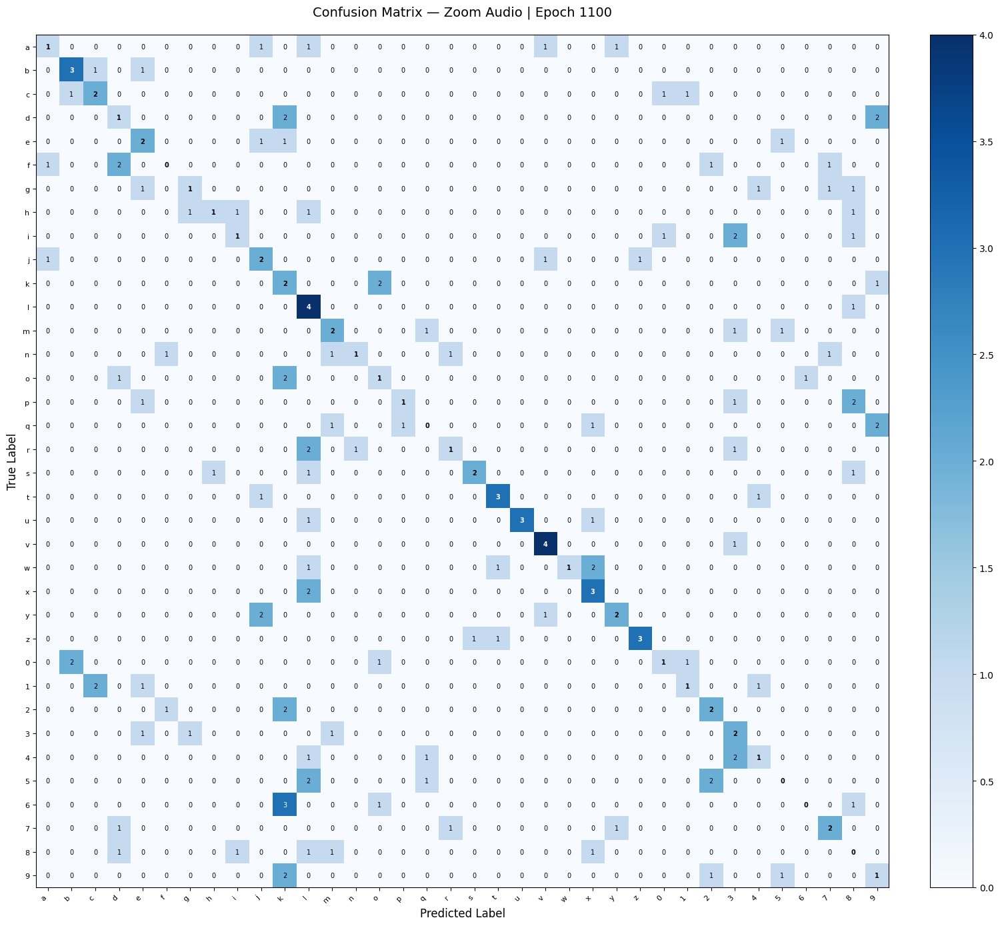

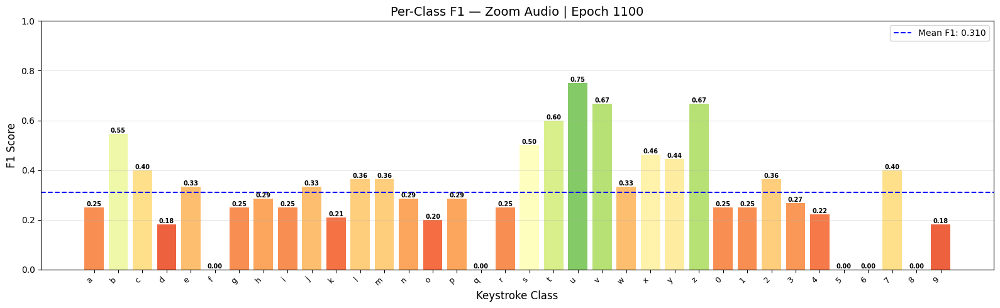

  Time      : 2.16s
  Train     → Loss: 0.0023 | Acc: 1.0000
  Val       → Loss: 5.3809   | Acc: 0.3167
  Weighted  → P: 0.3573 | R: 0.3167 | F1: 0.3096

✓ Loaded best Zoom Audio weights  (F1: 0.3749)


In [8]:
history = {
    "Phone Audio": {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': [],
        'weighted_val_precision': [],
        'weighted_val_recall': [],
        'weighted_val_f1': [],
        'learning_rates': []           
    },
    "Zoom Audio": {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': [],
        'weighted_val_precision': [],
        'weighted_val_recall': [],
        'weighted_val_f1': [],
        'learning_rates': []                        
    }
}

PLOT_EVERY_N_EPOCHS = 100

models = {
    "Phone Audio": [PhoneAudioModel, PhoneAudioTrainLoader, PhoneAudioValLoader, PhoneAudioOptimizer],
    "Zoom Audio":  [ZoomAudioModel,  ZoomAudioTrainLoader,  ZoomAudioValLoader,  ZoomAudioOptimizer]
}

best_val_f1_tracker = {}

for model_name in models:
    best_val_f1       = 0
    best_model_state  = None
    model             = models[model_name][0]
    train_loader      = models[model_name][1]
    val_loader        = models[model_name][2]
    optimizer         = models[model_name][3]

    print("\n" + "=" * 60)
    print(f"  STARTING TRAINING: {model_name}")
    print("=" * 60)
    print(f"  Epochs     : {NUM_EPOCHS}")
    print(f"  Device     : {device}")
    print(f"  Parameters : {model.get_num_params():,}")
    print("=" * 60)

    for epoch in range(NUM_EPOCHS):
        start_time = time.time()
        print(f"\nEpoch {epoch+1}/{NUM_EPOCHS}")
        print("-" * 60)

        """Training Phrase"""
        train_loss, train_acc = train(model, train_loader, criterion, optimizer, device)

        """Validating Phrase"""
        show_plots = ((epoch + 1) % PLOT_EVERY_N_EPOCHS == 0) or (epoch + 1 == NUM_EPOCHS)
        (val_loss, val_acc,
         precision_per_class, recall_per_class, f1_per_class, support_per_class,
         precision_weighted, recall_weighted, f1_weighted) = validate(
            model, val_loader, criterion, device,
            num_classes = 36,
            show_plots  = show_plots,
            epoch       = epoch + 1,
            model_name  = model_name
        )

        """Logging History"""
        current_lr = optimizer.param_groups[0]['lr']
        history[model_name]['train_loss'].append(train_loss)
        history[model_name]['train_acc'].append(train_acc)
        history[model_name]['val_loss'].append(val_loss)
        history[model_name]['val_acc'].append(val_acc)
        history[model_name]['weighted_val_precision'].append(precision_weighted)
        history[model_name]['weighted_val_recall'].append(recall_weighted)
        history[model_name]['weighted_val_f1'].append(f1_weighted)
        history[model_name]['learning_rates'].append(current_lr)

        """Saving Best Model"""
        if f1_weighted > best_val_f1:
            best_val_f1 = f1_weighted
            best_model_state = model.state_dict().copy()
            print(f"  ★ New best Weighted F1: {f1_weighted:.4f}")

        epoch_time = time.time() - start_time
        print(f"  Time      : {epoch_time:.2f}s")
        print(f"  Train     → Loss: {train_loss:.4f} | Acc: {train_acc:.4f}")
        print(f"  Val       → Loss: {val_loss:.4f}   | Acc: {val_acc:.4f}")
        print(f"  Weighted  → P: {precision_weighted:.4f} | R: {recall_weighted:.4f} | F1: {f1_weighted:.4f}")

    """Load Best Weights"""
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
        print(f"\n✓ Loaded best {model_name} weights  (F1: {best_val_f1:.4f})")

    best_val_f1_tracker[model_name] = best_val_f1

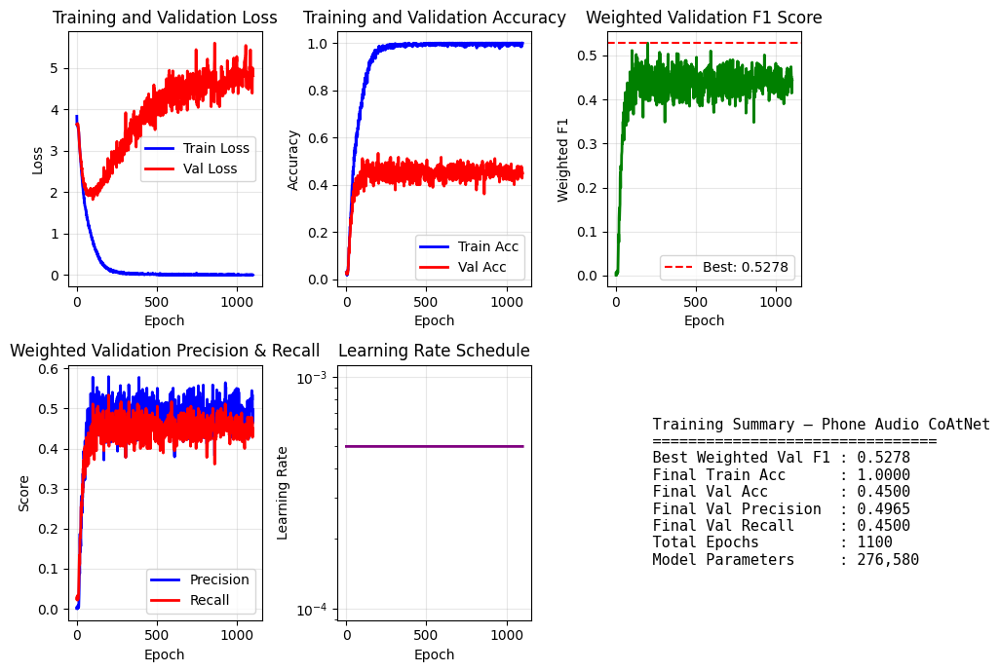

In [9]:
plot_training_history(history["Phone Audio"], "Phone Audio CoAtNet", PhoneAudioModel, best_val_f1_tracker["Phone Audio"])

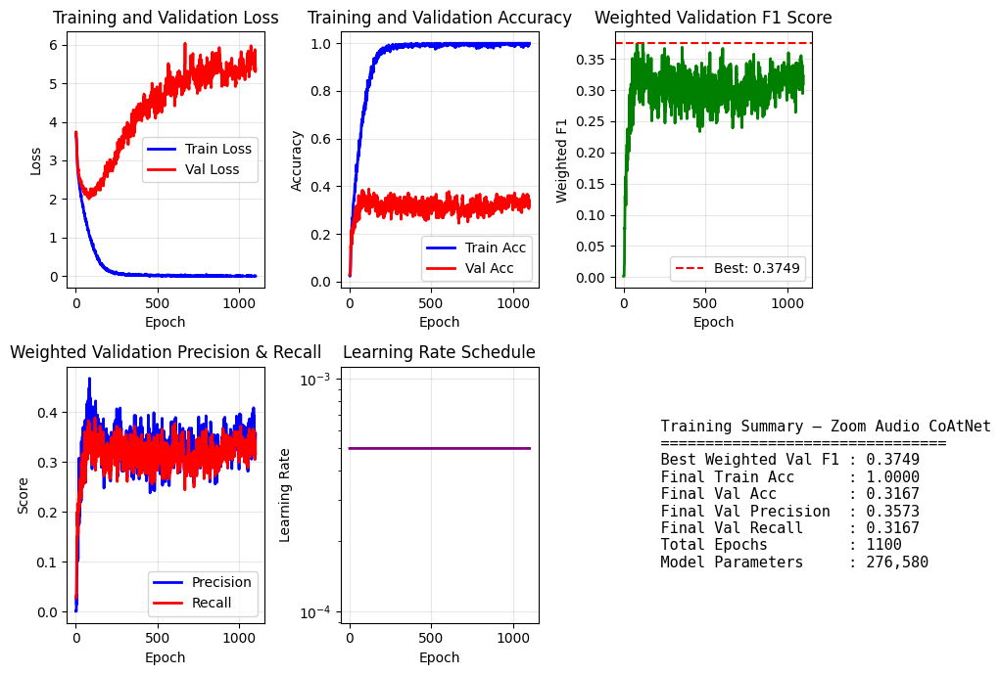

In [10]:
plot_training_history(history["Zoom Audio"],  "Zoom Audio CoAtNet", ZoomAudioModel,  best_val_f1_tracker["Zoom Audio"])

### Save Model

In [11]:
models = {"PhoneAudioCoATnet": PhoneAudioModel, "ZoomAudioCoATnet": ZoomAudioModel}

for modelName in models:
    model_save_path = f'{modelName}.pth'
    model = models[modelName]
    torch.save(model.state_dict(), model_save_path)
    print(f"\n✓ Model saved to: {model_save_path}")


✓ Model saved to: PhoneAudioCoATnet.pth

✓ Model saved to: ZoomAudioCoATnet.pth
